# Sensibilité 0νββ de SuperNEMO : version finale (activités mesurées)

Ce notebook reprend **exactement les entrées de la macro ROOT** :
* mêmes fichiers de simulation (`with_and_without_threshold/with_threshold` et `raphael_threshold_make_root_without_ptd_simu` pour les PMTs) ;
* même correspondance phase données → phase simulée (0→0, 1→1, 2→2, 3→3, 4→3) ;
* **N_sim lu dans chaque fichier** (`last_event_number`) et durées lues dans les fichiers de données (`run_time`) ;
* mêmes activités que la macro, y compris ²¹²Bi, ²¹⁴Pb, ²¹⁰Bi, ²²⁸Ac, ²¹²Pb et ²³⁴Th ;
* pas de blindage fer (choix de l'analyse double bêta) ;
* mêmes coupures, y compris les OMs exclus par phase ; la coupure angulaire est réglable avec `ANGLE_CUT`.

Neutrons : facteur ajusté sur les électrons externes de la phase 3 (`draw_all_separate.C`), appliqué comme un **taux constant** à toutes les phases, sans dépendance à la durée des phases.

Plan :
1. configuration ;
2. lecture des paramètres ROOT (N_sim, durées) ;
3. chargement simulations et données ;
4. **validation** : taux par jour comparés à la macro et spectre en évènements/jour/100 keV ;
5. carte de sensibilité (E_min, E_max) ;
6. sensibilité avec et sans la phase 0 ;
7. spectre pour la thèse ;
8. sensibilité en fonction de l'erreur sur l'échelle en énergie ;
9. sensibilité en fonction du temps (dates réelles, projection au 31/12/2026) ;
10. tableaux de contributions par zone en énergie ;
11. résumé et export ROOT.

In [1]:
import Pkg
Pkg.activate("/sps/nemo/scratch/granjon/sensitivity_from_Maros_training/SN_Sensitivity_training")
using SNSensitivityEstimate, UnROOT, FHist, CairoMakie, CSV, DataFramesMeta, Statistics, Printf
println("Julia tourne avec $(Threads.nthreads()) thread(s)")

PROJECT_DIR = "/sps/nemo/scratch/granjon/sensitivity_from_Maros_training/SN_Sensitivity_training"
OUT_DIR     = joinpath(PROJECT_DIR, "data", "out", "ex8"); mkpath(OUT_DIR)

# ---- constantes (identiques à la macro) ----
DAY     = 86400.0
YEAR    = 365.25 * DAY                  # la macro utilise 365,25 jours
M_ISO   = 6.110                         # kg de Se-82 (6110 g dans la macro)
W_SE    = 0.0819167                     # kg/mol
N_A     = 6.022e23
α       = 1.64485362695147              # 90 % CL
κ       = log(2) * N_A / W_SE * M_ISO   # T½ = κ · ε · t[an] / N_exclus(b)

# ---- Feldman-Cousins (table du package, accès direct) ----
FC_VEC = let tbl = SNSensitivityEstimate.tbl_90[]
    v = zeros(33000)
    for (b, S) in zip(tbl[:, 1], tbl[:, 2]); v[round(Int, b * 100) + 1] = S; end
    v
end
N_exclus(b) = b < 329 ? FC_VEC[round(Int, b * 100) + 1] : 1.8 * sqrt(b)

# ---- figures ----
THESIS_STYLE = true
ttl(s) = THESIS_STYLE ? "" : s
SUP = Dict(zip("-0123456789", "⁻⁰¹²³⁴⁵⁶⁷⁸⁹"))
function sci(x; d = 2)                   # 2.16e23 -> "2,16×10²³"
    e = floor(Int, log10(x)); m = round(x / 10.0^e, digits = d)
    ms = d == 0 ? string(round(Int, m)) : replace(string(m), "." => ",")
    return ms * "×10" * join(SUP[c] for c in string(e))
end
function savefig(f, name)
    save(joinpath(OUT_DIR, name * ".pdf"), f); save(joinpath(OUT_DIR, name * ".png"), f, px_per_unit = 2)
    println("→ ", joinpath(OUT_DIR, name * ".pdf")); f
end

  Activating project at `/sps/nemo/scratch/granjon/sensitivity_from_Maros_training/SN_Sensitivity_training`


Julia tourne avec 1 thread(s)


savefig (generic function with 1 method)

## 1. Configuration

Tout ce qui est à adapter est ici. **À vérifier en priorité** : le chemin du signal bb0nu (`BB0NU_FILE`). La macro ne simule pas le 0νββ ;
si aucun fichier n'existe dans le même dossier que les autres simulations, on reprend celui de l'ex5.

In [2]:
ANGLE_CUT        = true      # coupure angle 3D > 50° (section 7.5.4) ; false pour comparer à la macro telle quelle
INCLUDE_NEUTRONS = true
BIN_WIDTH        = 0.05      # MeV, pas de la carte (E_min, E_max) ; ≥ 0,02 conseillé
BINS             = 0:BIN_WIDTH:5

PHASES     = ["0", "1", "2", "3", "4"]                                              # phases des données
SIM_OF     = Dict("0" => "0", "1" => "1", "2" => "2", "3" => "3", "4" => "3")      # phaseNamesSim de la macro
NEUTRON_OF = Dict("0" => "0", "1" => "1", "2" => "2a", "3" => "2a", "4" => "3")
OMLIST_OF  = Dict("0" => "list_om_phase_0.txt", "1" => "list_om_phase_1.txt", "2" => "list_om_phase_2a.txt",
                  "3" => "list_om_phase_2b.txt", "4" => "list_om_phase_3.txt")
RADON_BQ_M3 = Dict("0" => 88e-3, "1" => 101e-3, "2" => 76.3e-3, "3" => 65.68e-3, "4" => 9.73483e-3)   # biActivity

BASE_PATH    = "/sps/nemo/scratch/granjon/double_beta/cimrman_curve/with_and_without_threshold/with_threshold"
PMT_PATH     = "/sps/nemo/scratch/granjon/double_beta/cimrman_curve/raphael_threshold_make_root_without_ptd_simu"
DATA_PATH    = "/sps/nemo/scratch/granjon/double_beta/cimrman_curve/ptd_pol2/root_with_max_threshold_working"
RUNTIME_PATH = "/sps/nemo/scratch/granjon/double_beta/cimrman_curve/ptd_pol2/root_with_max_threshold"
CALIB_PATH   = "/sps/nemo/scratch/granjon/full_gain_analysis/Bi/root/compute_a/phase_by_phase_calib_for_pol2"
NEUTRON_PATH = "/sps/nemo/scratch/spratt/files_for_mathis/neutron_sims"

mc_file(name, sim; pmt = false) = joinpath(pmt ? PMT_PATH : BASE_PATH, name, "phase_$sim", "$(name)_phase_$sim.root")
BB0NU_FILE(sim)     = mc_file("bb0nu", sim)                                                             # à adapter si besoin
BB0NU_FALLBACK(sim) = joinpath(PROJECT_DIR, "data", "mathis_files", "bb0nu", "phase_$sim", "simu_0", "rec_bb0nu_$(sim)_0.root")
BB0NU_NSIM_FALLBACK = 1_000_000

# ---- activités (Bq), copiées de la macro ----
A_BB2NU  = log(2) / (8.7e19 * YEAR) * N_A * 6110 / 81.9167
A_TH_CHAIN = 54e-6 / 0.36 * 6.25                          # 212Bi, 228Ac, 212Pb

# Activités du verre des PMTs 8" ajustées sur les électrons externes (draw_all_separate.C, tableau activity_summary) :
#   232Th ×1,67 (192 Bq), 238U ×1,96 (276 Bq), 40K ×2,01 (841 Bq). Le blindage fer n'est volontairement pas inclus.
USE_FITTED_PMT = false         # true = activités ajustées sur les électrons externes (non utilisé pour la thèse)
PMT8_FIT = USE_FITTED_PMT ? (U = 1.96, Th = 1.67, K = 2.01) : (U = 1.0, Th = 1.0, K = 1.0)
# (nom du dossier, pmt ?, activité(phase), groupe pour le tableau, groupe pour le spectre)
COMPONENTS = [
    ("bb2nu",         false, ph -> A_BB2NU,                         "2νββ",           "2νββ"),
    ("radon",         false, ph -> RADON_BQ_M3[ph] * 15.3 * 0.95,   "Radon",          "Radon (95 % vol + 5 % surf)"),
    ("radon_surface", false, ph -> RADON_BQ_M3[ph] * 15.3 * 0.05,   "Radon",          "Radon (95 % vol + 5 % surf)"),
    ("214Bi",         false, ph -> 290e-6 * 6.25,                   "Source",         "Bi-214 source"),
    ("234Pa",         false, ph -> 17.3e-3 * 6.25,                  "Source",         "Pa-234m source"),
    ("40K",           false, ph -> 58.7e-3 * 6.25,                  "Source",         "K-40 source"),
    ("208Tl",         false, ph -> 54e-6 * 6.25,                    "Source",         "Tl-208 source"),
    ("212Bi",         false, ph -> A_TH_CHAIN,                      "Source",         "Autres source"),
    ("228Ac",         false, ph -> A_TH_CHAIN,                      "Source",         "Autres source"),
    ("212Pb",         false, ph -> A_TH_CHAIN,                      "Source",         "Autres source"),
    ("214Pb",         false, ph -> 290e-6 * 6.25,                   "Source",         "Autres source"),
    ("234Th",         false, ph -> 17.3e-3 * 6.25,                  "Source",         "Autres source"),   # ajouté dans la macro angle_cut50
    ("210Bi",         false, ph -> 290e-6 * 6.25,                   "Source",         "Autres source"),
    ("bi_pmt",   true, ph -> 141.0 * PMT8_FIT.U,  "PMT", "Verre des PMTs"),
    ("tl_pmt",   true, ph -> 40.0  * PMT8_FIT.Th, "PMT", "Verre des PMTs"),
    ("k_pmt",    true, ph -> 417.0 * PMT8_FIT.K,  "PMT", "Verre des PMTs"),
    ("bi_5_pmt", true, ph -> 56 * 0.294,     "PMT", "Verre des PMTs"),
    ("bi_g_pmt", true, ph -> 56 * 0.235,     "PMT", "Verre des PMTs"),
    ("bi_x_pmt", true, ph -> 56 * 0.471,     "PMT", "Verre des PMTs"),
    ("tl_5_pmt", true, ph -> 3.15 * 0.294,   "PMT", "Verre des PMTs"),
    ("tl_g_pmt", true, ph -> 3.15 * 0.235,   "PMT", "Verre des PMTs"),
    ("tl_x_pmt", true, ph -> 3.15 * 0.471,   "PMT", "Verre des PMTs"),
    ("k_5_pmt",  true, ph -> 123 * 0.294,    "PMT", "Verre des PMTs"),
    ("k_g_pmt",  true, ph -> 123 * 0.235,    "PMT", "Verre des PMTs"),
    ("k_x_pmt",  true, ph -> 123 * 0.471,    "PMT", "Verre des PMTs"),
]
TABLE_GROUPS = ["2νββ", "Radon", "Source", "PMT", "Neutrons"]
SPEC_GROUPS  = ["2νββ", "Radon (95 % vol + 5 % surf)", "Bi-214 source", "Pa-234m source", "K-40 source", "Tl-208 source",
                "Autres source", "Verre des PMTs", "Neutrons"]

9-element Vector{String}:
 "2νββ"
 "Radon (95 % vol + 5 % surf)"
 "Bi-214 source"
 "Pa-234m source"
 "K-40 source"
 "Tl-208 source"
 "Autres source"
 "Verre des PMTs"
 "Neutrons"

## 2. Paramètres lus dans les fichiers ROOT : N_sim et durées

UnROOT ne lit pas les `TParameter`. On appelle donc ROOT (via `module load root`) pour lire, dans chaque fichier :
* `last_event_number` : nombre d'évènements simulés, exactement comme `neventperSimu` dans la macro ;
* `run_time` : durée de chaque phase, comme `get_times()`.

Si ROOT n'est pas trouvé, la commande à lancer dans un terminal est affichée.

In [3]:
READ_PARAMS_C = "#include <fstream>
#include <iostream>
#include <string>
#include \"TFile.h\"
#include \"TParameter.h\"
void read_params(const char* list) {
  std::ifstream f(list); std::string p;
  while (f >> p) {
    TFile* t = TFile::Open(p.c_str());
    double nsim = -1, rt = -1;
    if (t && !t->IsZombie()) {
      if (auto* a = dynamic_cast<TParameter<Long64_t>*>(t->Get(\"last_event_number\"))) nsim = a->GetVal();
      if (auto* b = dynamic_cast<TParameter<double>*>(t->Get(\"run_time\"))) rt = b->GetVal();
      t->Close();
    }
    std::cout << \"PARAM \" << p << \" \" << nsim << \" \" << rt << std::endl;
  }
}
"

function read_root_params(paths)
    list = joinpath(OUT_DIR, "param_files.txt"); write(list, join(paths, "\n") * "\n")
    mac  = joinpath(OUT_DIR, "read_params.C");   write(mac, READ_PARAMS_C)
    cmd  = `bash -lc "module load root 2>/dev/null; root -l -b -q '$(mac)(\"$(list)\")'"`
    out  = try read(cmd, String) catch
        error("ROOT introuvable. Dans un terminal : module load root ; $(cmd)")
    end
    d = Dict{String, Tuple{Float64, Float64}}()
    for l in split(out, '\n')
        startswith(l, "PARAM ") || continue
        _, p, a, b = split(l)
        d[p] = (parse(Float64, a), parse(Float64, b))
    end
    return d
end

mc_paths = [mc_file(c[1], SIM_OF[ph]; pmt = c[2]) for c in COMPONENTS for ph in PHASES]
sig_paths = unique([isfile(BB0NU_FILE(SIM_OF[ph])) ? BB0NU_FILE(SIM_OF[ph]) : BB0NU_FALLBACK(SIM_OF[ph]) for ph in PHASES])
rt_paths = [joinpath(RUNTIME_PATH, "phase_$ph.root") for ph in PHASES]
@time PARAMS = read_root_params(unique(vcat(mc_paths, sig_paths, rt_paths)))

THESIS_DAYS = Dict("0" => 37.91, "1" => 25.66, "2" => 14.21, "3" => 76.57, "4" => 155.19)   # tableau 7.1, secours
LIVE_S = Dict(ph => (v = get(PARAMS, joinpath(RUNTIME_PATH, "phase_$ph.root"), (-1.0, -1.0))[2]; v > 0 ? v : THESIS_DAYS[ph] * DAY) for ph in PHASES)
for ph in PHASES; println("phase $ph : ", round(LIVE_S[ph] / DAY, digits = 2), " jours"); end
T_TOT = sum(values(LIVE_S))
println("Total : ", round(T_TOT / DAY, digits = 2), " jours, exposition ", round(M_ISO * T_TOT / YEAR, digits = 3), " kg·an")
missing_files = [p for p in mc_paths if !haskey(PARAMS, p) || PARAMS[p][1] <= 0]
isempty(missing_files) || @warn "Fichiers absents ou sans last_event_number (ignorés) :" missing_files

[log] Entering SuperNEMO software common profile...
[log] SuperNEMO software common profile is already loaded.
[log] Exiting SuperNEMO software common profile...


  6.982465 seconds (431.13 k allocations: 29.697 MiB, 5.16% compilation time: 12% of which was recompilation)
phase 0 : 37.91 jours
phase 1 : 25.66 jours
phase 2 : 14.21 jours
phase 3 : 77.04 jours
phase 4 : 155.89 jours
Total : 310.71 jours, exposition 5.198 kg·an


true

## 3. Coupures et chargement

Coupures identiques à `FillHistFromTree` de la macro, plus la coupure angulaire si `ANGLE_CUT = true`.
Chaque couple (composante, phase) devient un `DataProcess` : les coups attendus sont $N_{pass}/N_{sim} \times A \times t_p$.

In [9]:
VAR_NAMES = ["energy_elec_sum", "angle_3D_between_ep_em", "delta_y_elec", "delta_z_elec", "internal_theoretical_time_diff",
             "energy_elec_1", "energy_elec_2", "hit_the_same_calo_hit", "closest_gamma", "closest_elec", "closest_track",
             "closest_time_track", "has_kinks", "num_om_elec_f", "vertex_3D_start_y", "vertex_3D_start_z"]

function good_oms(ph)
    good = [om < 520 for om in 0:711]                      # indice = om + 1
    for l in readlines(joinpath(CALIB_PATH, OMLIST_OF[ph]))[2:end], tok in split(l)
        om = tryparse(Int, tok); om === nothing || (good[om + 1] = false)
    end
    good
end
GOOD = Dict(ph => good_oms(ph) for ph in PHASES)

# renvoie E_sum des évènements passant TOUTES les coupures de la macro (+ angle si ANGLE_CUT)
function select_esum(path, good)
    t = UnROOT.LazyTree(UnROOT.ROOTFile(path), "Event", VAR_NAMES)
    E = Float64[]
    for ev in t
        dy, dz = ev.delta_y_elec, ev.delta_z_elec
        sqrt(dy^2 + dz^2) >= 100 && continue
        ev.hit_the_same_calo_hit == 1 && continue
        abs(ev.closest_gamma) <= 50 && continue
        abs(ev.closest_elec) <= 25 && continue
        abs(ev.closest_track) < 200 && continue
        abs(ev.closest_time_track) < 10 && continue
        om = ev.num_om_elec_f
        length(om) != 2 && continue
        (om[1] > 520 || om[2] > 520) && continue
        (!good[om[1] + 1] || !good[om[2] + 1]) && continue
        abs(ev.internal_theoretical_time_diff) >= 1.5 && continue
        (ev.energy_elec_1 < 0.350 || ev.energy_elec_2 < 0.350) && continue
        ev.has_kinks == 1 && continue
        vy, vz = ev.vertex_3D_start_y, ev.vertex_3D_start_z
        if length(vy) >= 2 && length(vz) >= 2
            y = 0.5 * (vy[1] + vy[2]); z = 0.5 * (vz[1] + vz[2])
            (((y - 1180) / 60)^2 + ((z + 850) / 140)^2 <= 1 || ((y - 1144) / 25)^2 + ((z - 196) / 40)^2 <= 1 ||
             ((y - 1114) / 25)^2 + ((z + 257) / 40)^2 <= 1 || abs(y) > 2360 || abs(z) > 1340) && continue
        end
        ANGLE_CUT && ev.angle_3D_between_ep_em < 50 && continue
        push!(E, ev.energy_elec_sum)
    end
    return E
end

select_esum (generic function with 1 method)

In [6]:
# Tableau des efficacités 

In [10]:
# =====================================================================================
# CUTFLOW : efficacité cumulée du signal simulé après chaque coupure, par phase + total pondéré
# Ordre des coupures = ordre du chapitre. Les coupures sont exactement celles de select_esum.
# Une efficacité cumulée dépend de l'ordre : le tableau est donc RECALCULÉ (pas seulement réordonné).
# À lancer après les sections 1 à 3 (PARAMS, GOOD, SIM_OF, mc_file…).  Sortie : OUT_DIR/table_cutflow.tex
# =====================================================================================
CF_SIMU      = "bb2nu"      # "bb2nu" (tableau du chapitre) ou "bb0nu"
CF_ANGLE_ROW = false        # true : ajoute la ligne « angle > 50° » à la fin (coupure utilisée pour la sensibilité)
CF_DAYS      = Dict("0" => 37.9111, "1" => 25.656, "2" => 14.2069, "3" => 76.5699, "4" => 155.198)   # durées de la légende (309,54 j)

# (étiquette LaTeX, test : true = l'évènement PASSE la coupure). good = OMs valides de la phase.
in_hot_or_border(ev) = begin
    vy, vz = ev.vertex_3D_start_y, ev.vertex_3D_start_z
    length(vy) >= 2 && length(vz) >= 2 || return false
    y = 0.5 * (vy[1] + vy[2]); z = 0.5 * (vz[1] + vz[2])
    ((y - 1180) / 60)^2 + ((z + 850) / 140)^2 <= 1 || ((y - 1144) / 25)^2 + ((z - 196) / 40)^2 <= 1 ||
    ((y - 1114) / 25)^2 + ((z + 257) / 40)^2 <= 1 || abs(y) > 2360 || abs(z) > 1340
end
oms_ok(ev, good) = (om = ev.num_om_elec_f; length(om) == 2 && om[1] <= 520 && om[2] <= 520 && good[om[1] + 1] && good[om[2] + 1])

CF_CUTS = [
    (raw"Rejet même OM hit",                            (ev, g) -> ev.hit_the_same_calo_hit != 1),
    (raw"$|\Delta t_{\rm int}|<1{,}5$~ns",              (ev, g) -> abs(ev.internal_theoretical_time_diff) < 1.5),
    (raw"Distance vertex $\Delta y,\Delta z<100$~mm",   (ev, g) -> sqrt(ev.delta_y_elec^2 + ev.delta_z_elec^2) < 100),
    (raw"Rejet électrons additionnels",                 (ev, g) -> abs(ev.closest_elec) > 25),
    (raw"Rejet $\gamma$ en coïncidence",                (ev, g) -> abs(ev.closest_gamma) > 50),
    (raw"Rejet trace courte coïncidente ($t$)",         (ev, g) -> abs(ev.closest_time_track) >= 10),
    (raw"Rejet trace courte proche",                    (ev, g) -> abs(ev.closest_track) >= 200),
    (raw"Hors points chauds / bordures",                (ev, g) -> !in_hot_or_border(ev)),
    (raw"OM valides",                                   (ev, g) -> oms_ok(ev, g)),
    (raw"Rejet diffusion",                              (ev, g) -> ev.has_kinks != 1),
    (raw"$E_1,E_2>350$~keV",                            (ev, g) -> ev.energy_elec_1 >= 0.350 && ev.energy_elec_2 >= 0.350),
]
CF_ANGLE_ROW && push!(CF_CUTS, (raw"Angle $>50^\circ$", (ev, g) -> ev.angle_3D_between_ep_em >= 50))

# fichier et N_sim de la simulation pour une phase
function cf_file(ph)
    sim = SIM_OF[ph]
    if CF_SIMU == "bb0nu"
        f = isfile(BB0NU_FILE(sim)) ? BB0NU_FILE(sim) : BB0NU_FALLBACK(sim)
        return f, (haskey(PARAMS, f) && PARAMS[f][1] > 0 ? PARAMS[f][1] : BB0NU_NSIM_FALLBACK)
    end
    f = mc_file(CF_SIMU, sim); return f, PARAMS[f][1]
end

# nombre d'évènements restant après chaque étape (étape 0 = 2 e⁻ candidats = entrées de l'arbre)
function cutflow_counts(ph)
    f, nsim = cf_file(ph); good = GOOD[ph]
    cnt = zeros(Int, length(CF_CUTS) + 1)
    for ev in UnROOT.LazyTree(UnROOT.ROOTFile(f), "Event", VAR_NAMES)
        cnt[1] += 1
        for (k, (_, pass)) in enumerate(CF_CUTS)
            pass(ev, good) || break
            cnt[k + 1] += 1
        end
    end
    return cnt ./ nsim
end

@time CF = Dict(ph => cutflow_counts(ph) for ph in PHASES)          # efficacités cumulées par phase
TD = sum(CF_DAYS[ph] for ph in PHASES)
CF_TOT = [sum(CF[ph][k] * CF_DAYS[ph] for ph in PHASES) / TD for k in 1:length(CF_CUTS) + 1]

labels = vcat([raw"2 $e^-$ candidats"], [c[1] for c in CF_CUTS])
fmtp(x) = @sprintf("%.2f\\%%", 100x)
io = IOBuffer()
println(io, "\\begin{table}[H]\n\\centering\n\\footnotesize\n\\setlength{\\tabcolsep}{2.5pt}\n\\begin{tabular}{lrrrrrrr}\n\\hline")
println(io, "Coupure & Ph.0 & Ph.1 & Ph.2 & Ph.3 & Ph.4 & Total pondéré & Écart relatif \\\\ \\hline")
for k in eachindex(labels)
    ecart = k == 1 ? "--" : @sprintf("%.1f\\%%", 100 * (CF_TOT[k - 1] - CF_TOT[k]) / CF_TOT[k - 1])
    println(io, labels[k], " \n& ", join([fmtp(CF[ph][k]) for ph in PHASES], " & "), " & ", fmtp(CF_TOT[k]), " & ", ecart, " \\\\")
end
sig = CF_SIMU == "bb2nu" ? raw"$2\nu\beta\beta$" : raw"$0\nu\beta\beta$"
println(io, "\\hline\n\\end{tabular}")
println(io, "\\caption{\\centering \\small \nEfficacité cumulée de sélection du signal simulé $sig après chaque coupure, pour chacune des cinq phases de prise de données. ",
            "La colonne « Total pondéré » correspond à la moyenne pondérée des cinq phases par leur durée réelle d'acquisition (37,91, 25,66, 14,21, 76,57 et 155,19~jours, soit 309,54~jours au total). ",
            "La dernière colonne indique l'écart relatif \$(N_{\\rm avant}-N_{\\rm après})/N_{\\rm avant}\$ associé à chaque coupure sur l'efficacité pondérée.\n}")
println(io, "\\label{cutflow_eff_abs}\n\\end{table}")
CF_TEX = String(take!(io))
write(joinpath(OUT_DIR, "table_cutflow_$(CF_SIMU).tex"), CF_TEX)
print(CF_TEX)
println("\nContrôle : efficacité finale pondérée = ", fmtp(CF_TOT[end]), " (doit rester 3,54 % pour bb2nu sans la ligne angle : l'ordre ne change pas le total)")

341.843798 seconds (2.22 G allocations: 70.915 GiB, 3.10% gc time, 0.35% compilation time)
\begin{table}[H]
\centering
\footnotesize
\setlength{\tabcolsep}{2.5pt}
\begin{tabular}{lrrrrrrr}
\hline
Coupure & Ph.0 & Ph.1 & Ph.2 & Ph.3 & Ph.4 & Total pondéré & Écart relatif \\ \hline
2 $e^-$ candidats 
& 8.03\% & 17.32\% & 18.54\% & 18.54\% & 18.54\% & 17.15\% & -- \\
Rejet même OM hit 
& 6.88\% & 14.82\% & 15.88\% & 15.89\% & 15.89\% & 14.70\% & 14.3\% \\
$|\Delta t_{\rm int}|<1{,}5$~ns 
& 6.50\% & 13.02\% & 13.98\% & 13.99\% & 13.99\% & 12.99\% & 11.6\% \\
Distance vertex $\Delta y,\Delta z<100$~mm 
& 5.88\% & 11.37\% & 12.17\% & 12.19\% & 12.19\% & 11.35\% & 12.6\% \\
Rejet électrons additionnels 
& 5.82\% & 11.12\% & 11.91\% & 11.93\% & 11.93\% & 11.11\% & 2.1\% \\
Rejet $\gamma$ en coïncidence 
& 5.80\% & 10.93\% & 11.72\% & 11.75\% & 11.75\% & 10.95\% & 1.5\% \\
Rejet trace courte coïncidente ($t$) 
& 5.58\% & 10.44\% & 11.20\% & 11.22\% & 11.22\% & 10.47\% & 4.4\% \\
Rejet trace cou

### Neutrons

Même liste de fichiers que `FillNeutronHistFromMap` (sauf `inelastic`). Le facteur 0,29 a été ajusté dans `draw_all_separate.C`
sur la **phase 3** (canal externe, haute énergie). Dans ce code, le poids d'un évènement simulé vaut, en évènements/jour :
$sf \cdot 0{,}29 \cdot (t_3/T_{tot}) \cdot t_3[\mathrm{an}] \cdot 0{,}29 \cdot t_3[\mathrm{an}]/2{,}845$.

Ce nombre n'a de sens que pour la phase 3. Le flux de neutrons étant constant dans le temps, on l'utilise comme **taux par jour** pour
toutes les phases (`NEUTRON_MODE = :fit_ref`). La macro `usine_a_plot` réévaluait au contraire la formule avec le $t_p$ de chaque
phase, ce qui donne une dépendance en $t_p^2$ (`:macro`, gardé pour comparer).

In [11]:
NEUTRON_FIT  = 0.29          # facteur ajusté dans draw_all_separate.C (phase 3, canal externe), appliqué deux fois comme dans la macro
NEUTRON_REF  = "3"           # phase sur laquelle le facteur a été ajusté
NEUTRON_MODE = :fit_ref      # :fitted (ajusté en 4c, recommandé une fois connu) | :fit_ref (facteur de draw_all_separate, phase 3) | :macro | :constant
NEUTRON_K    = nothing       # facteur ajusté en 4c sur les électrons externes > 5 MeV, toutes phases (utilisé si NEUTRON_MODE = :fitted)

# taux par évènement simulé passant les coupures (s⁻¹)
function neutron_rate_per_event(sf, t_p)
    if NEUTRON_MODE == :fitted
        # taux constant ajusté sur le canal externe, toutes phases : N_p = N_pass · sf · K · t_p / 2,845 an
        return sf * NEUTRON_K / (2.845 * YEAR)
    elseif NEUTRON_MODE == :fit_ref
        # normalisation de draw_all_separate.C évaluée pour la phase de référence (évts/jour),
        # puis appliquée comme un TAUX CONSTANT à toutes les phases
        t_ref = LIVE_S[NEUTRON_REF]
        return sf * NEUTRON_FIT^2 * (t_ref / T_TOT) * (t_ref / YEAR)^2 / 2.845 / DAY
    elseif NEUTRON_MODE == :macro      # usine_a_plot : dépend de t_p (évts/jour → /s)
        return sf * 0.29 * (t_p / T_TOT) * (t_p / YEAR) * (T_TOT / (2.845 * YEAR)) * 0.29 / DAY
    else                               # :constant
        return sf * 0.29^2 / (2.845 * YEAR)
    end
end
NEUTRON_SCALES = let m = Dict{String, Float64}()
    for l in readlines(joinpath(NEUTRON_PATH, "all_scaling_factors.txt"))[2:end]
        f = split(l); length(f) < 5 && continue
        m["$(f[1])_$(f[2])_$(f[3])_$(f[4])"] = parse(Float64, f[5])
    end
    m
end
function load_neutrons(ph)
    np = NEUTRON_OF[ph]; suffix = "_phase" * np; procs = DataProcess[]
    for (k, sf) in NEUTRON_SCALES
        endswith(k, suffix) || continue
        speed, dir, elem = split(k[1:end-length(suffix)], "_"; limit = 3)
        elem == "inelastic" && continue
        fn = joinpath(NEUTRON_PATH, speed, dir, elem, "phase$np", "combined_phase$np.root")
        isfile(fn) || continue
        E = select_esum(fn, GOOD[ph])
        push!(procs, DataProcess(E, "n_$(speed)_$(dir)_$(elem)", false, neutron_rate_per_event(sf, LIVE_S[ph]), LIVE_S[ph], 1.0, BINS, 1.0))
    end
    procs
end

load_neutrons (generic function with 1 method)

In [5]:
GROUP_TABLE = Dict{String, String}(); GROUP_SPEC = Dict{String, String}()
for c in COMPONENTS; GROUP_TABLE[c[1]] = c[4]; GROUP_SPEC[c[1]] = c[5]; end
table_group(name) = startswith(name, "n_") ? "Neutrons" : GROUP_TABLE[name]
spec_group(name)  = startswith(name, "n_") ? "Neutrons" : GROUP_SPEC[name]

function load_phase(ph)
    sim = SIM_OF[ph]; t = LIVE_S[ph]; procs = DataProcess[]
    for (name, pmt, A, _, _) in COMPONENTS
        p = mc_file(name, sim; pmt = pmt)
        (haskey(PARAMS, p) && PARAMS[p][1] > 0) || continue
        push!(procs, DataProcess(select_esum(p, GOOD[ph]), name, false, A(ph), t, PARAMS[p][1], BINS, 1.0))
    end
    INCLUDE_NEUTRONS && append!(procs, load_neutrons(ph))
    # signal
    sp = isfile(BB0NU_FILE(sim)) ? BB0NU_FILE(sim) : BB0NU_FALLBACK(sim)
    nsim = haskey(PARAMS, sp) && PARAMS[sp][1] > 0 ? PARAMS[sp][1] : BB0NU_NSIM_FALLBACK
    push!(procs, DataProcess(select_esum(sp, GOOD[ph]), "bb0nu", true, 1.0, t, nsim, BINS, 1.0))
    data = select_esum(joinpath(DATA_PATH, "phase_$ph.root"), GOOD[ph])
    return (phase = ph, t_s = t, procs = procs, data = data)
end

@time SETS = Threads.nthreads() > 1 ? fetch.([Threads.@spawn load_phase(ph) for ph in PHASES]) : [load_phase(ph) for ph in PHASES]
println("Signal bb0nu utilisé : ", isfile(BB0NU_FILE(SIM_OF["0"])) ? "dossier de la macro" : "fichiers de l'ex5 (BB0NU_FALLBACK)")

LoadError: UndefVarError: `load_neutrons` not defined

## 4. Validation par rapport à la macro

**Tableau** : taux de chaque contribution en évènements/jour, sur tout le spectre, **par phase**. On garde cet affichage par phase
uniquement pour pouvoir le comparer aux légendes de la macro (« Data 37.7/day », etc.). Il n'est pas destiné à la thèse.

**Figure** : spectre de toutes les phases combinées, en évènements/jour/100 keV, avec le même style que la macro, pour une comparaison visuelle.

In [10]:
counts(p) = length(p.dataVector) / p.nTotalSim * p.activity * p.amount * p.timeMeas
let cols = vcat(["phase", "jours", "données / jour", "MC total / jour"], SPEC_GROUPS)
    df = DataFrame([c => Any[] for c in cols])
    for s in SETS
        days = s.t_s / DAY
        d = Dict(g => 0.0 for g in SPEC_GROUPS)
        for p in s.procs; p.signal || (d[spec_group(p.isotopeName)] += counts(p)); end
        push!(df, vcat([s.phase, round(days, digits = 2), round(length(s.data) / days, digits = 2), round(sum(values(d)) / days, digits = 2)],
                       [round(d[g] / days, digits = 3) for g in SPEC_GROUPS]))
    end
    df
end

Row,phase,jours,données / jour,MC total / jour,2νββ,Radon (95 % vol + 5 % surf),Bi-214 source,Pa-234m source,K-40 source,Tl-208 source,Autres source,Verre des PMTs,Neutrons
,Any,Any,Any,Any,Any,Any,Any,Any,Any,Any,Any,Any,Any
1,0,37.91,60.98,53.1,30.473,11.616,0.168,5.069,0.456,0.023,0.038,5.214,0.043
2,1,25.66,41.9,44.05,29.384,7.977,0.102,4.469,0.48,0.011,0.028,1.589,0.013
3,2,14.21,54.06,54.08,37.641,7.781,0.133,5.725,0.608,0.014,0.036,2.126,0.017
4,3,77.04,50.51,52.64,37.275,6.74,0.131,5.678,0.597,0.014,0.036,2.148,0.016
5,4,155.89,31.35,32.44,25.796,0.696,0.091,3.935,0.416,0.01,0.025,1.46,0.011


In [11]:
# =====================================================================================
# SPECTRES AVEC / SANS COUPURE ANGULAIRE + SPECTRE ANGULAIRE (sans coupure angulaire)
# Composantes séparées comme dans cellule_spectre_pmt.jl (PMT ²¹⁴Bi / ²⁰⁸Tl / ⁴⁰K à part).
#
# SETS ne contient que E1+E2 APRÈS la coupure angulaire : on relit donc les fichiers une fois (même boucle et mêmes
# coupures que select_esum, sauf l'angle), en gardant E1+E2 et l'angle de chaque évènement. Sauvegardé dans
# OUT_DIR/SETS_ANGLE.jls : les relances suivantes prennent quelques secondes.
# Prérequis : sections 1 à 3 (et 4c si tu utilises les neutrons ajustés, comme pour SETS).
# Figures enregistrées dans OUT_DIR : spectre_E_avec_angle_{lin,log}, spectre_E_sans_angle_{lin,log}, spectre_angle_{lin,log}
# =====================================================================================
using Serialization

ANGLE_MIN  = 50.0          # degrés, coupure angulaire
SIG_THALF  = nothing       # ex. 2.30e23 pour superposer le signal 0νββ sur les spectres en énergie ; nothing = pas de signal
E_EDGES    = collect(0:0.1:5)        # MeV, 100 keV
A_EDGES    = collect(0:5.0:180)      # degrés, 5°

# ---------- lecture : toutes les coupures de select_esum sauf l'angle ----------
function select_eang(path, good)
    t = UnROOT.LazyTree(UnROOT.ROOTFile(path), "Event", VAR_NAMES)
    E = Float64[]; A = Float64[]
    for ev in t
        dy, dz = ev.delta_y_elec, ev.delta_z_elec
        sqrt(dy^2 + dz^2) >= 100 && continue
        ev.hit_the_same_calo_hit == 1 && continue
        abs(ev.closest_gamma) <= 50 && continue
        abs(ev.closest_elec) <= 25 && continue
        abs(ev.closest_track) < 200 && continue
        abs(ev.closest_time_track) < 10 && continue
        om = ev.num_om_elec_f
        length(om) != 2 && continue
        (om[1] > 520 || om[2] > 520) && continue
        (!good[om[1] + 1] || !good[om[2] + 1]) && continue
        abs(ev.internal_theoretical_time_diff) >= 1.5 && continue
        (ev.energy_elec_1 < 0.350 || ev.energy_elec_2 < 0.350) && continue
        ev.has_kinks == 1 && continue
        vy, vz = ev.vertex_3D_start_y, ev.vertex_3D_start_z
        if length(vy) >= 2 && length(vz) >= 2
            y = 0.5 * (vy[1] + vy[2]); z = 0.5 * (vz[1] + vz[2])
            (((y - 1180) / 60)^2 + ((z + 850) / 140)^2 <= 1 || ((y - 1144) / 25)^2 + ((z - 196) / 40)^2 <= 1 ||
             ((y - 1114) / 25)^2 + ((z + 257) / 40)^2 <= 1 || abs(y) > 2360 || abs(z) > 1340) && continue
        end
        push!(E, ev.energy_elec_sum); push!(A, ev.angle_3D_between_ep_em)
    end
    return (E = E, A = A)
end

function load_phase_angle(ph)
    sim = SIM_OF[ph]; t = LIVE_S[ph]; bkg = NamedTuple[]
    for (name, pmt, Act, _, _) in COMPONENTS
        p = mc_file(name, sim; pmt = pmt)
        (haskey(PARAMS, p) && PARAMS[p][1] > 0) || continue
        push!(bkg, (name = name, w = Act(ph) * t / PARAMS[p][1], ev = select_eang(p, GOOD[ph])))
    end
    if INCLUDE_NEUTRONS
        np = NEUTRON_OF[ph]; suffix = "_phase" * np
        for (k, sf) in NEUTRON_SCALES
            endswith(k, suffix) || continue
            speed, dir, elem = split(k[1:end-length(suffix)], "_"; limit = 3)
            elem == "inelastic" && continue
            fn = joinpath(NEUTRON_PATH, speed, dir, elem, "phase$np", "combined_phase$np.root")
            isfile(fn) || continue
            push!(bkg, (name = "n_$(speed)_$(dir)_$(elem)", w = neutron_rate_per_event(sf, t) * t, ev = select_eang(fn, GOOD[ph])))
        end
    end
    sp = isfile(BB0NU_FILE(sim)) ? BB0NU_FILE(sim) : BB0NU_FALLBACK(sim)
    nsim = haskey(PARAMS, sp) && PARAMS[sp][1] > 0 ? PARAMS[sp][1] : BB0NU_NSIM_FALLBACK
    return (phase = ph, t_s = t, bkg = bkg, sig = (nsim = nsim, ev = select_eang(sp, GOOD[ph])),
            data = select_eang(joinpath(DATA_PATH, "phase_$ph.root"), GOOD[ph]))
end

println("NEUTRON_MODE = $NEUTRON_MODE (même normalisation que SETS)")
ANG_FILE = joinpath(OUT_DIR, "SETS_ANGLE.jls")
if isfile(ANG_FILE)
    SETS_ANG = deserialize(ANG_FILE); println("Relu depuis $ANG_FILE")
else
    @time SETS_ANG = Threads.nthreads() > 1 ? fetch.([Threads.@spawn load_phase_angle(ph) for ph in PHASES]) :
                                              [load_phase_angle(ph) for ph in PHASES]
    serialize(ANG_FILE, SETS_ANG)
end

# ---------- groupes (PMTs séparés en 3) ----------
SPEC_GROUPS_PLOT = ["2νββ", "Radon (95 % vol + 5 % surf)", "Bi-214 source", "Pa-234m source", "K-40 source", "Tl-208 source",
                    "Autres source", "PMT ²¹⁴Bi", "PMT ²⁰⁸Tl", "PMT ⁴⁰K", "Neutrons"]
SPEC_COLORS = Dict("2νββ" => :orange, "Radon (95 % vol + 5 % surf)" => :magenta, "Bi-214 source" => :purple,
                   "Pa-234m source" => :green, "K-40 source" => :dodgerblue, "Tl-208 source" => :navy,
                   "Autres source" => :brown, "Neutrons" => :gray60,
                   "PMT ²¹⁴Bi" => :darkgoldenrod3, "PMT ²⁰⁸Tl" => :goldenrod1, "PMT ⁴⁰K" => :khaki3)
function spec_group_plot(name)
    startswith(name, "n_")  && return "Neutrons"
    startswith(name, "bi_") && return "PMT ²¹⁴Bi"
    startswith(name, "tl_") && return "PMT ²⁰⁸Tl"
    startswith(name, "k_")  && return "PMT ⁴⁰K"
    return GROUP_SPEC[name]
end

# ---------- histogrammes : var = :E ou :A ; keep(E, A) = sélection supplémentaire ----------
function hist_groups(sets, var, edges, keep; tHalf = nothing)
    nb = length(edges) - 1
    g = Dict(k => zeros(nb) for k in SPEC_GROUPS_PLOT); sig = zeros(nb); d = zeros(nb)
    function addw!(v, ev, w)
        x = getproperty(ev, var)
        for k in eachindex(x)
            keep(ev.E[k], ev.A[k]) || continue
            i = searchsortedlast(edges, x[k]); 1 <= i <= nb && (v[i] += w)
        end
    end
    for s in sets
        for p in s.bkg; addw!(g[spec_group_plot(p.name)], p.ev, p.w); end
        tHalf === nothing || addw!(sig, s.sig.ev, κ * (s.t_s / YEAR) / (tHalf * s.sig.nsim))
        addw!(d, s.data, 1.0)
    end
    return g, d, sig
end

stairs_y(c) = vcat(c, c[end])
function plot_groups(g, d, sig, edges; xlabel, ylabel, logy, fname, vline = nothing, tHalf = nothing, xrange = (edges[1], edges[end]))
    ctr = (edges[1:end-1] .+ edges[2:end]) ./ 2
    mc = sum(values(g))
    ymin = logy ? max(1e-1, 0.3 * minimum(filter(>(0), mc); init = 1.0)) : 0.0
    f = Figure(size = (1400, 1050), fontsize = 26)
    ax  = Axis(f[1, 1], ylabel = ylabel, yscale = logy ? log10 : identity)
    axr = Axis(f[2, 1], xlabel = xlabel, ylabel = "100×(Données−MC)/MC [%]")
    linkxaxes!(ax, axr); hidexdecorations!(ax, grid = false); rowsize!(f.layout, 2, Relative(0.28)); rowgap!(f.layout, 6)
    if vline !== nothing
        for a in (ax, axr); vlines!(a, [vline], color = :red, linestyle = :dash, linewidth = 2); end
    end
    for k in SPEC_GROUPS_PLOT
        any(g[k] .> 0) || continue
        stairs!(ax, edges, stairs_y(max.(g[k], ymin)), step = :post, color = SPEC_COLORS[k], linewidth = 2.5, label = k)
    end
    stairs!(ax, edges, stairs_y(max.(mc, ymin)), step = :post, color = :red3, linewidth = 4, label = "MC total")
    tHalf === nothing || stairs!(ax, edges, stairs_y(max.(sig, ymin)), step = :post, color = :black, linestyle = :dash,
                                 linewidth = 3, label = "0νββ, T½ = $(sci(tHalf)) an")
    m = d .> 0
    lo = min.(sqrt.(d[m]), d[m] .- ymin * 1.001)
    errorbars!(ax, ctr[m], d[m], lo, sqrt.(d[m]), color = :black, whiskerwidth = 6)
    scatter!(ax, ctr[m], d[m], color = :black, markersize = 10, label = "Données")
    k = (d .> 0) .& (mc .> 0)
    errorbars!(axr, ctr[k], 100 .* (d[k] .- mc[k]) ./ mc[k], 100 .* sqrt.(d[k]) ./ mc[k], color = :black, whiskerwidth = 6)
    scatter!(axr, ctr[k], 100 .* (d[k] .- mc[k]) ./ mc[k], color = :black, markersize = 9)
    hlines!(axr, [0], color = :red3, linestyle = :dash)
    xlims!(ax, xrange...); ylims!(axr, -100, 100)
    logy ? ylims!(ax, ymin, 3 * maximum(max.(mc, d))) : ylims!(ax, 0, 1.15 * maximum(max.(mc, d .+ sqrt.(d))))
    Legend(f[1, 2], ax, framevisible = false, labelsize = 20, merge = true)
    savefig(f, fname)
end

# ---------- 1) E1+E2 avec coupure angulaire, 2) sans, 3) angle sans coupure ----------
avec_angle(E, A) = A >= ANGLE_MIN
sans_angle(E, A) = true
for logy in (false, true)
    sfx = logy ? "log" : "lin"
    g, d, sig = hist_groups(SETS_ANG, :E, E_EDGES, avec_angle; tHalf = SIG_THALF)
    display(plot_groups(g, d, sig, E_EDGES; xlabel = "E1 + E2 (MeV)", ylabel = "Évènements / 100 keV", logy = logy,
                        tHalf = SIG_THALF, fname = "spectre_E_avec_angle_$sfx"))
    g, d, sig = hist_groups(SETS_ANG, :E, E_EDGES, sans_angle; tHalf = SIG_THALF)
    display(plot_groups(g, d, sig, E_EDGES; xlabel = "E1 + E2 (MeV)", ylabel = "Évènements / 100 keV", logy = logy,
                        tHalf = SIG_THALF, fname = "spectre_E_sans_angle_$sfx"))
    g, d, sig = hist_groups(SETS_ANG, :A, A_EDGES, sans_angle)
    display(plot_groups(g, d, sig, A_EDGES; xlabel = "Angle 3D entre les deux électrons (°)", ylabel = "Évènements / 5°", logy = logy,
                        vline = ANGLE_MIN, fname = "spectre_angle_$sfx"))
end

# contrôle : avec la coupure angulaire, on doit retrouver le nombre d'évènements de SETS
println("Données avec coupure angulaire : ", sum(count(>=(ANGLE_MIN), s.data.A) for s in SETS_ANG),
        "  (SETS : ", sum(length(s.data) for s in SETS), ")")

NEUTRON_MODE = fit_ref (même normalisation que SETS)
Relu depuis /sps/nemo/scratch/granjon/sensitivity_from_Maros_training/SN_Sensitivity_training/data/out/ex8/SETS_ANGLE.jls


LoadError: InterruptException:

### 4b. Contrôle de la normalisation des neutrons : spectre externe, toutes phases, 0–10 MeV

Reproduction de `draw_all_separate.C` (sélection externe), mais pour **toutes les phases ensemble** :
* **sélection externe** : $\sqrt{\Delta y^2 + \Delta z^2} < 100$ mm, pas le même calo, $|closest_\gamma| > 25$, $|closest_e| > 25$,
  $|closest_{track}| > 200$, $|closest_{time\,track}| > 10$, $|\Delta t_{int}| > 2$ ns, 2 OMs valides (liste de chaque phase) ;
  **pas** de coupure en énergie, kinks, région de vertex ni angle ;
* chaque phase : simulation et OMs de la phase, activité × durée de la phase ; données `root_with_max_threshold/phase_X.root` ;
* résultat en évènements par jour moyens sur les 309,54 jours, 0–10 MeV, bins de 50 keV, échelle log de $10^{-5}$ à 10 ;
* neutrons avec **la normalisation utilisée dans ce notebook** (`NEUTRON_MODE`).

**Cellule autonome** : elle n'a besoin que des cellules des sections 1, 2 et 3 (définitions), **pas** du chargement des phases (`SETS`).
Le blindage fer (`VALID_IRON`, activités non ajustées de `draw_all_separate.C`, simulation de la phase 3 pour toutes les phases) sert
uniquement à la comparaison avec ta figure.

[log] Entering SuperNEMO software common profile...
[log] SuperNEMO software common profile is already loaded.
[log] Exiting SuperNEMO software common profile...


2017.898481 seconds (4.18 G allocations: 273.567 GiB, 1.39% gc time, 0.03% compilation time: 3% of which was recompilation)
Évènements / jour (toutes phases, sélection externe) : données = 7829.518, > 4 MeV : 3.40514
  Interne + radon   63.8594   > 4 MeV : 0.0
  PMT 5"            61.2864   > 4 MeV : 0.0
  PMT 8"            1538.6424   > 4 MeV : 0.62849
  Blindage fer      1620.3518   > 4 MeV : 0.0
  Neutrons          3.944   > 4 MeV : 1.98589
  MC total          3288.084   > 4 MeV : 2.61438
→ /sps/nemo/scratch/granjon/sensitivity_from_Maros_training/SN_Sensitivity_training/data/out/ex8/validation_external_all_phases.pdf


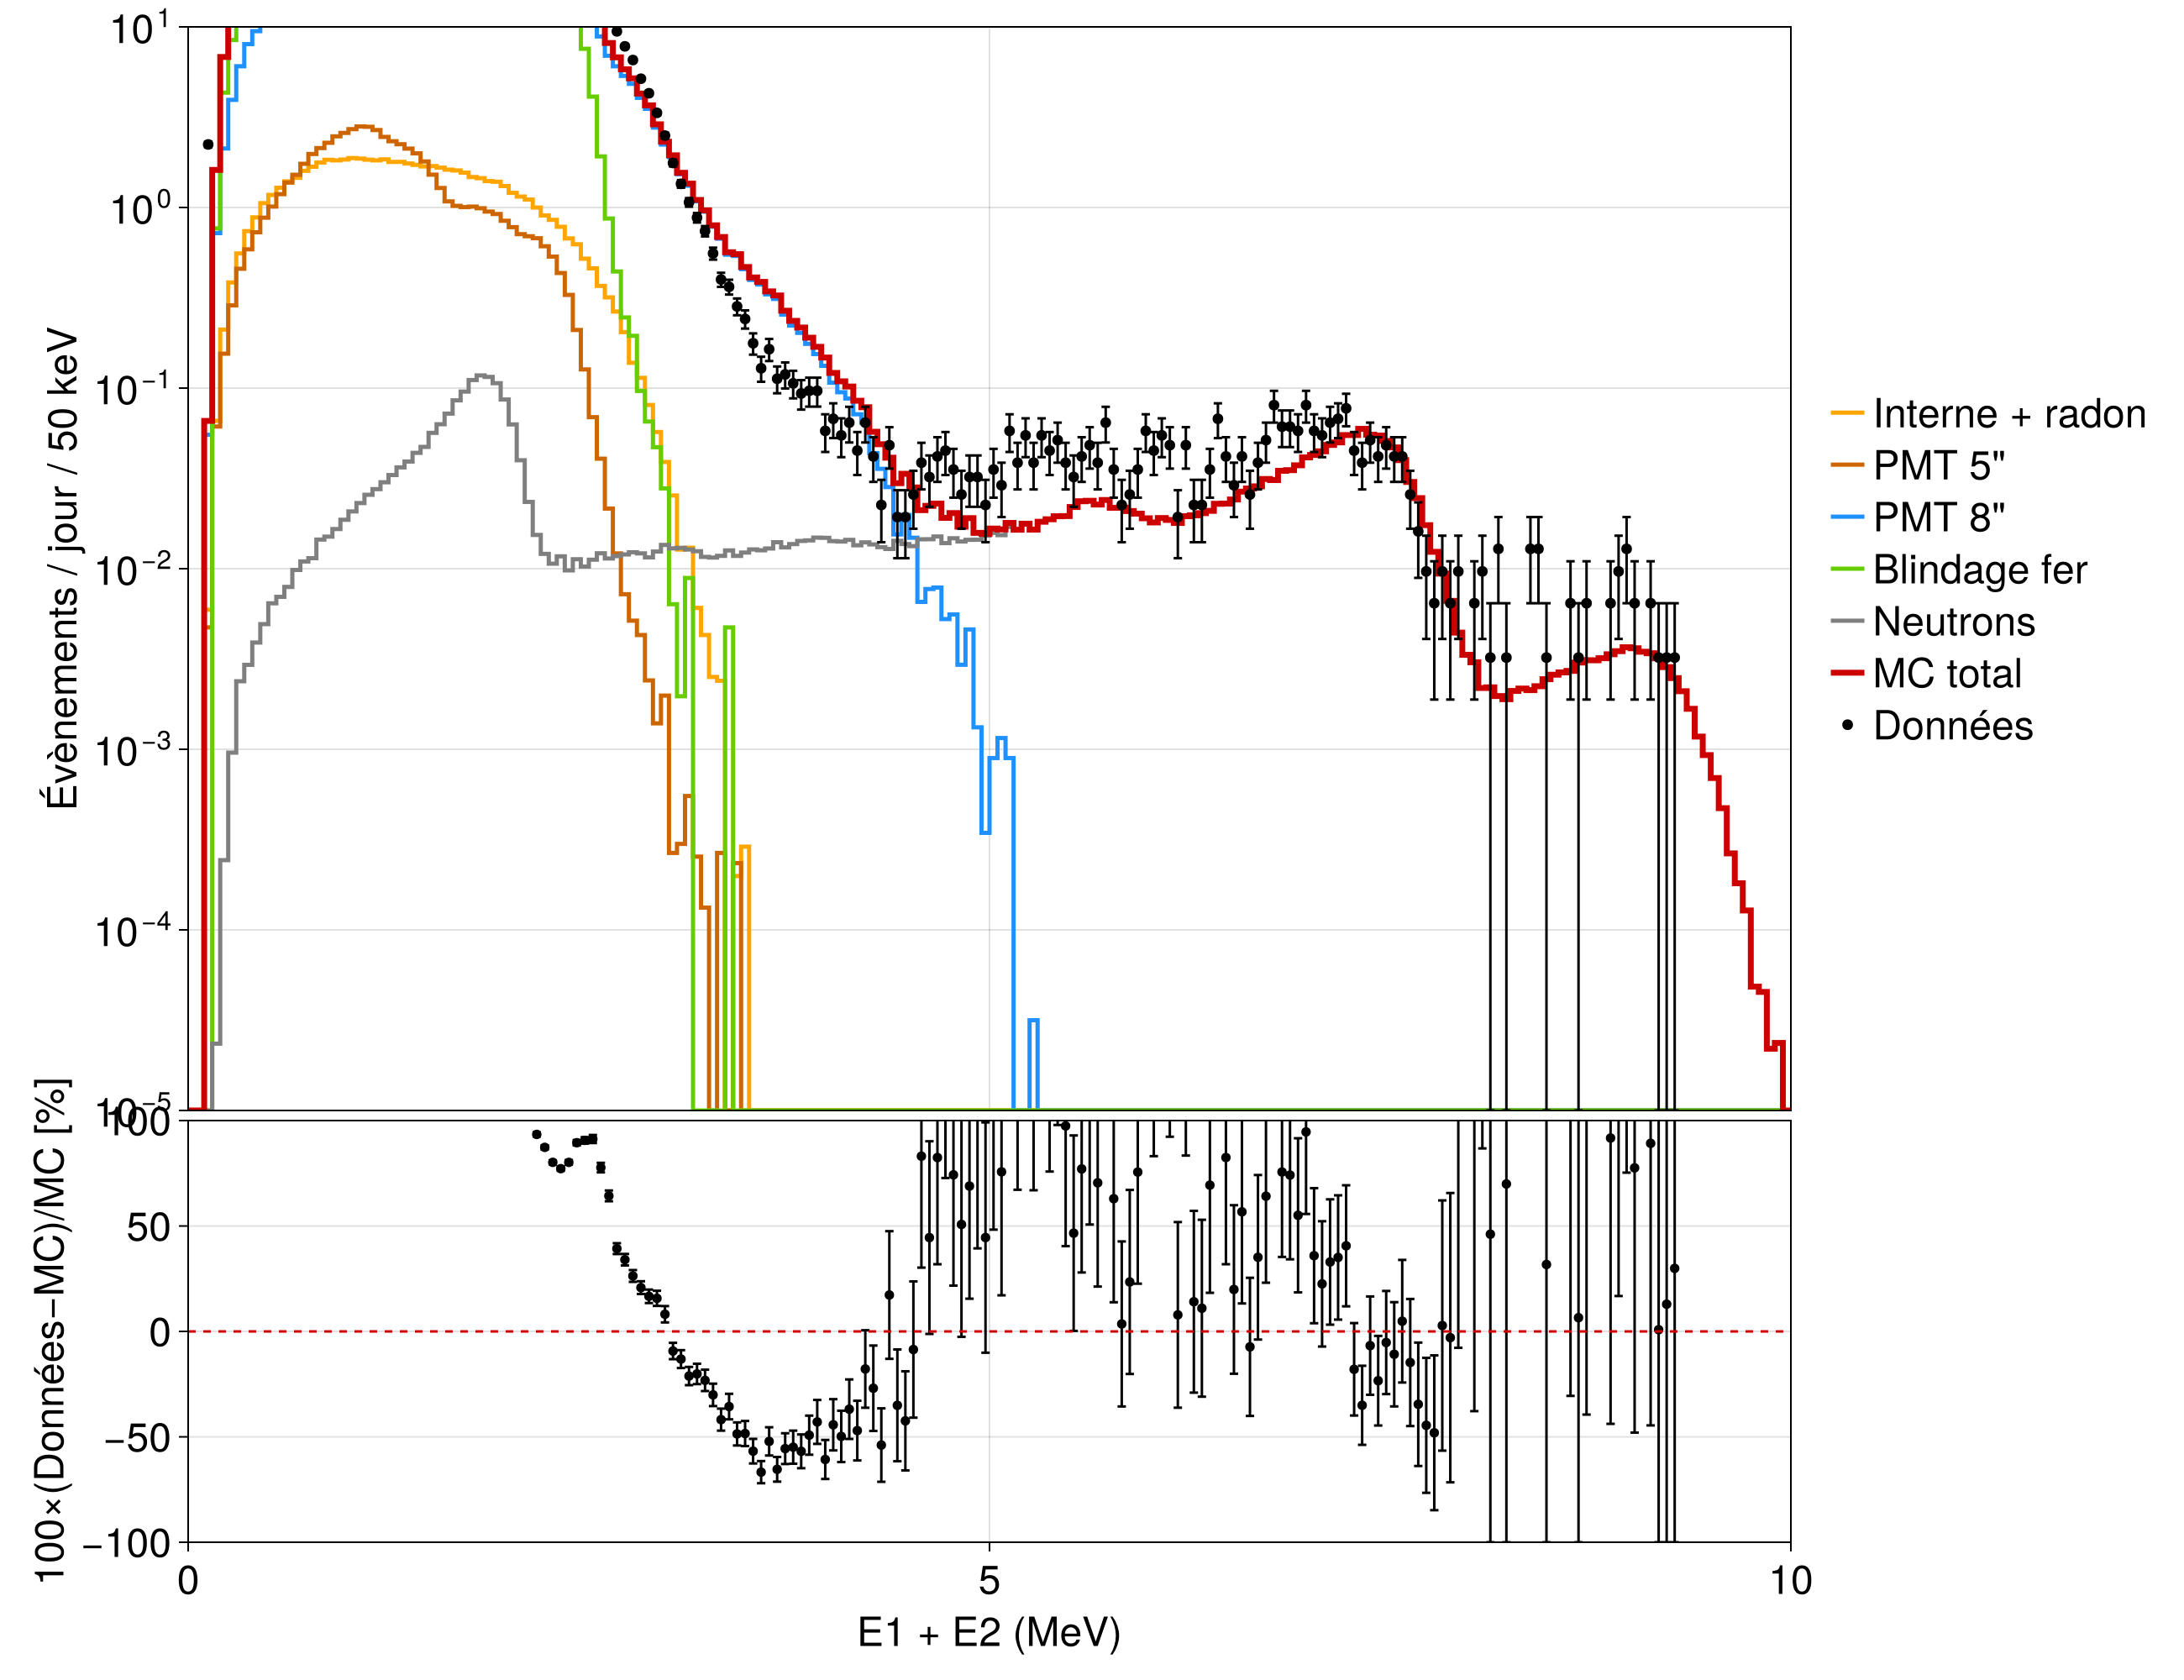

In [13]:
VALID_IRON = true
IRON_PATH  = "/sps/nemo/scratch/granjon/external/iron"
IRON = [("iron_bi",    joinpath(IRON_PATH, "bi_pmt/phase_3/iron_bi.root"),    3680.0001),
        ("iron_tl",    joinpath(IRON_PATH, "tl_pmt/phase_3/iron_tl.root"),    273.7),
        ("iron_k",     joinpath(IRON_PATH, "k_pmt/phase_3/iron_k.root"),      3680.0001),
        ("iron_bi212", joinpath(IRON_PATH, "bi_212/phase_3/iron_bi212.root"), 273.7 / 0.36),
        ("iron_pb212", joinpath(IRON_PATH, "Pb_212/phase_3/iron_pb212.root"), 273.7 / 0.36),
        ("iron_pb214", joinpath(IRON_PATH, "Pb_214/phase_3/iron_pb214.root"), 273.7 / 0.36),   # comme dans draw_all_separate.C
        ("iron_Ac",    joinpath(IRON_PATH, "Ac/phase_3/iron_Ac.root"),        273.7 / 0.36)]
EXT_GROUPS = ["Interne + radon", "PMT 5\"", "PMT 8\"", "Blindage fer", "Neutrons"]
EXT_COLORS = [:orange, :darkorange3, :dodgerblue, :chartreuse3, :gray50]
EXT_EDGES  = collect(0:0.05:10)

function select_external(path, good)
    t = UnROOT.LazyTree(UnROOT.ROOTFile(path), "Event", VAR_NAMES)
    E = Float64[]
    for ev in t
        sqrt(ev.delta_y_elec^2 + ev.delta_z_elec^2) < 100 || continue
        ev.hit_the_same_calo_hit == 0 || continue
        abs(ev.closest_gamma) > 25 || continue
        abs(ev.closest_elec) > 25 || continue
        abs(ev.closest_track) > 200 || continue
        abs(ev.closest_time_track) > 10 || continue
        abs(ev.internal_theoretical_time_diff) > 2 || continue
        om = ev.num_om_elec_f
        length(om) == 2 || continue
        (good[om[1] + 1] && good[om[2] + 1]) || continue
        push!(E, ev.energy_elec_sum)
    end
    E
end
function ext_hist(E, w)
    nb = length(EXT_EDGES) - 1; h = zeros(nb)
    for x in E; i = searchsortedlast(EXT_EDGES, x); 1 <= i <= nb && (h[i] += w); end
    h
end

IRON_PARAMS = VALID_IRON ? read_root_params([x[2] for x in IRON if isfile(x[2])]) : Dict()

# une phase -> Dict(groupe => comptes sur la durée de la phase), comptes données
function external_phase(ph)
    sim = SIM_OF[ph]; good = GOOD[ph]; t = LIVE_S[ph]; nb = length(EXT_EDGES) - 1
    g = Dict(k => zeros(nb) for k in EXT_GROUPS)
    for (name, pmt, A, _, _) in COMPONENTS
        p = mc_file(name, sim; pmt = pmt)
        (haskey(PARAMS, p) && PARAMS[p][1] > 0) || continue
        grp = !pmt ? "Interne + radon" : (occursin("_5_", name) || occursin("_g_", name) || occursin("_x_", name)) ? "PMT 5\"" : "PMT 8\""
        g[grp] .+= ext_hist(select_external(p, good), A(ph) * t / PARAMS[p][1])
    end
    if VALID_IRON
        for (name, path, A) in IRON
            (isfile(path) && haskey(IRON_PARAMS, path) && IRON_PARAMS[path][1] > 0) || continue
            g["Blindage fer"] .+= ext_hist(select_external(path, good), A * t / IRON_PARAMS[path][1])
        end
    end
    np = NEUTRON_OF[ph]; suffix = "_phase" * np
    for (k, sf) in NEUTRON_SCALES
        endswith(k, suffix) || continue
        speed, dir, elem = split(k[1:end-length(suffix)], "_"; limit = 3)
        elem == "inelastic" && continue
        fn = joinpath(NEUTRON_PATH, speed, dir, elem, "phase$np", "combined_phase$np.root")
        isfile(fn) || continue
        g["Neutrons"] .+= ext_hist(select_external(fn, good), neutron_rate_per_event(sf, t) * t)
    end
    d = ext_hist(select_external(joinpath(RUNTIME_PATH, "phase_$ph.root"), good), 1.0)
    return g, d
end

@time EXT = Threads.nthreads() > 1 ? fetch.([Threads.@spawn external_phase(ph) for ph in PHASES]) : [external_phase(ph) for ph in PHASES]
EXT_K = neutron_rate_per_event(1.0, LIVE_S[PHASES[1]]) * 2.845 * YEAR   # normalisation des neutrons utilisée pour EXT

let days = T_TOT / DAY, edges = EXT_EDGES, ctr = (EXT_EDGES[1:end-1] .+ EXT_EDGES[2:end]) ./ 2
    g = Dict(k => sum(e[1][k] for e in EXT) ./ days for k in EXT_GROUPS)
    dcount = sum(e[2] for e in EXT); d = dcount ./ days; derr = sqrt.(dcount) ./ days
    mc = sum(values(g))
    println("Évènements / jour (toutes phases, sélection externe) : données = $(round(sum(d), digits = 3)), > 4 MeV : $(round(sum(d[ctr .> 4]), digits = 5))")
    for k in EXT_GROUPS; println("  ", rpad(k, 18), round(sum(g[k]), digits = 4), "   > 4 MeV : ", round(sum(g[k][ctr .> 4]), digits = 5)); end
    println("  MC total          ", round(sum(mc), digits = 4), "   > 4 MeV : ", round(sum(mc[ctr .> 4]), digits = 5))

    ymin, ymax = 1e-5, 10.0
    f = Figure(size = (1300, 1000), fontsize = 24)
    ax  = Axis(f[1, 1], ylabel = "Évènements / jour / 50 keV", yscale = log10, title = ttl("Toutes phases, évènements externes"))
    axr = Axis(f[2, 1], xlabel = "E1 + E2 (MeV)", ylabel = "100×(Données−MC)/MC [%]")
    linkxaxes!(ax, axr); hidexdecorations!(ax, grid = false); rowsize!(f.layout, 2, Relative(0.28)); rowgap!(f.layout, 6)
    for (k, c) in zip(EXT_GROUPS, EXT_COLORS)
        any(g[k] .> 0) || continue
        stairs!(ax, edges, vcat(max.(g[k], ymin), max(g[k][end], ymin)), step = :post, color = c, linewidth = 2.5, label = k)
    end
    stairs!(ax, edges, vcat(max.(mc, ymin), max(mc[end], ymin)), step = :post, color = :red3, linewidth = 3.5, label = "MC total")
    m = dcount .> 0
    errorbars!(ax, ctr[m], d[m], min.(derr[m], d[m] .- ymin * 1.001), derr[m], color = :black, whiskerwidth = 5)
    scatter!(ax, ctr[m], d[m], color = :black, markersize = 9, label = "Données")
    k = m .& (mc .> 0)
    errorbars!(axr, ctr[k], 100 .* (d[k] .- mc[k]) ./ mc[k], 100 .* derr[k] ./ mc[k], color = :black, whiskerwidth = 5)
    scatter!(axr, ctr[k], 100 .* (d[k] .- mc[k]) ./ mc[k], color = :black, markersize = 8)
    hlines!(axr, [0], color = :red3, linestyle = :dash)
    xlims!(ax, 0, 10); ylims!(ax, ymin, ymax); ylims!(axr, -100, 100)
    Legend(f[1, 2], ax, framevisible = false, merge = true)
    savefig(f, "validation_external_all_phases")
end

### 4c. Ajustement du niveau de neutrons sur les électrons externes au-dessus de 5 MeV (toutes phases)

Au-dessus de 5 MeV, seuls les neutrons contribuent au canal externe. On ajuste **un seul facteur d'échelle $\mu$** sur la contribution des
neutrons de la cellule 4b (toutes phases), les autres contributions étant fixées, par **maximum de vraisemblance de Poisson** (bins de 50 keV,
bins vides compris) :
$$\ln L(\mu) = \sum_i \left[n_i \ln \lambda_i(\mu) - \lambda_i(\mu)\right], \qquad \lambda_i(\mu) = a_i + \mu\, n^{\rm neutrons}_i .$$
L'erreur à 1σ correspond à $\Delta \ln L = 0{,}5$. On donne aussi le χ² de Neyman et le rapport des intégrales, pour comparaison, et on teste
le seuil (4,5, 5 et 6 MeV).

Le résultat est converti en facteur **K** (taux par évènement simulé = $sf \cdot K / 2{,}845$ an, constant dans le temps). Pour l'utiliser :
`NEUTRON_MODE = :fitted` et `NEUTRON_K = K`. Si `SETS` est déjà en mémoire, la cellule **remet directement à l'échelle** les neutrons des
phases chargées (`APPLY_FIT = true`), sans rien relire : il suffit ensuite de relancer à partir de la section 5.

Row,emin,n_data,n_mc_neutrons,n_other,μ,μ_lo,μ_hi,μ_chi2,μ_ratio,nbins
,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Int64
1,4.5,919.0,574.197,18.6387,1.5635,1.5115,1.6165,1.3025,1.56803,110
2,5.0,816.0,529.331,0.924114,1.539,1.486,1.593,1.277,1.53982,100
3,6.0,553.0,406.812,0.0,1.3595,1.3025,1.4175,1.155,1.35935,80


Au-dessus de 5.0 MeV : 816 évènements observés, 815.6 ajustés
μ = 1.539 [1.486 ; 1.593]  (χ² : 1.277, rapport : 1.54)
→ NEUTRON_K = 0.5214893925325885   (1σ : [0.5035303686182109 ; 0.5397872659547845])   ; K utilisé en 4b = 0.3388495078184461
  Équivalent « facteur 0,29 » de draw_all_separate : 0.36 (si NEUTRON_MODE = :fit_ref)
→ /sps/nemo/scratch/granjon/sensitivity_from_Maros_training/SN_Sensitivity_training/data/out/ex8/neutron_fit_external.pdf


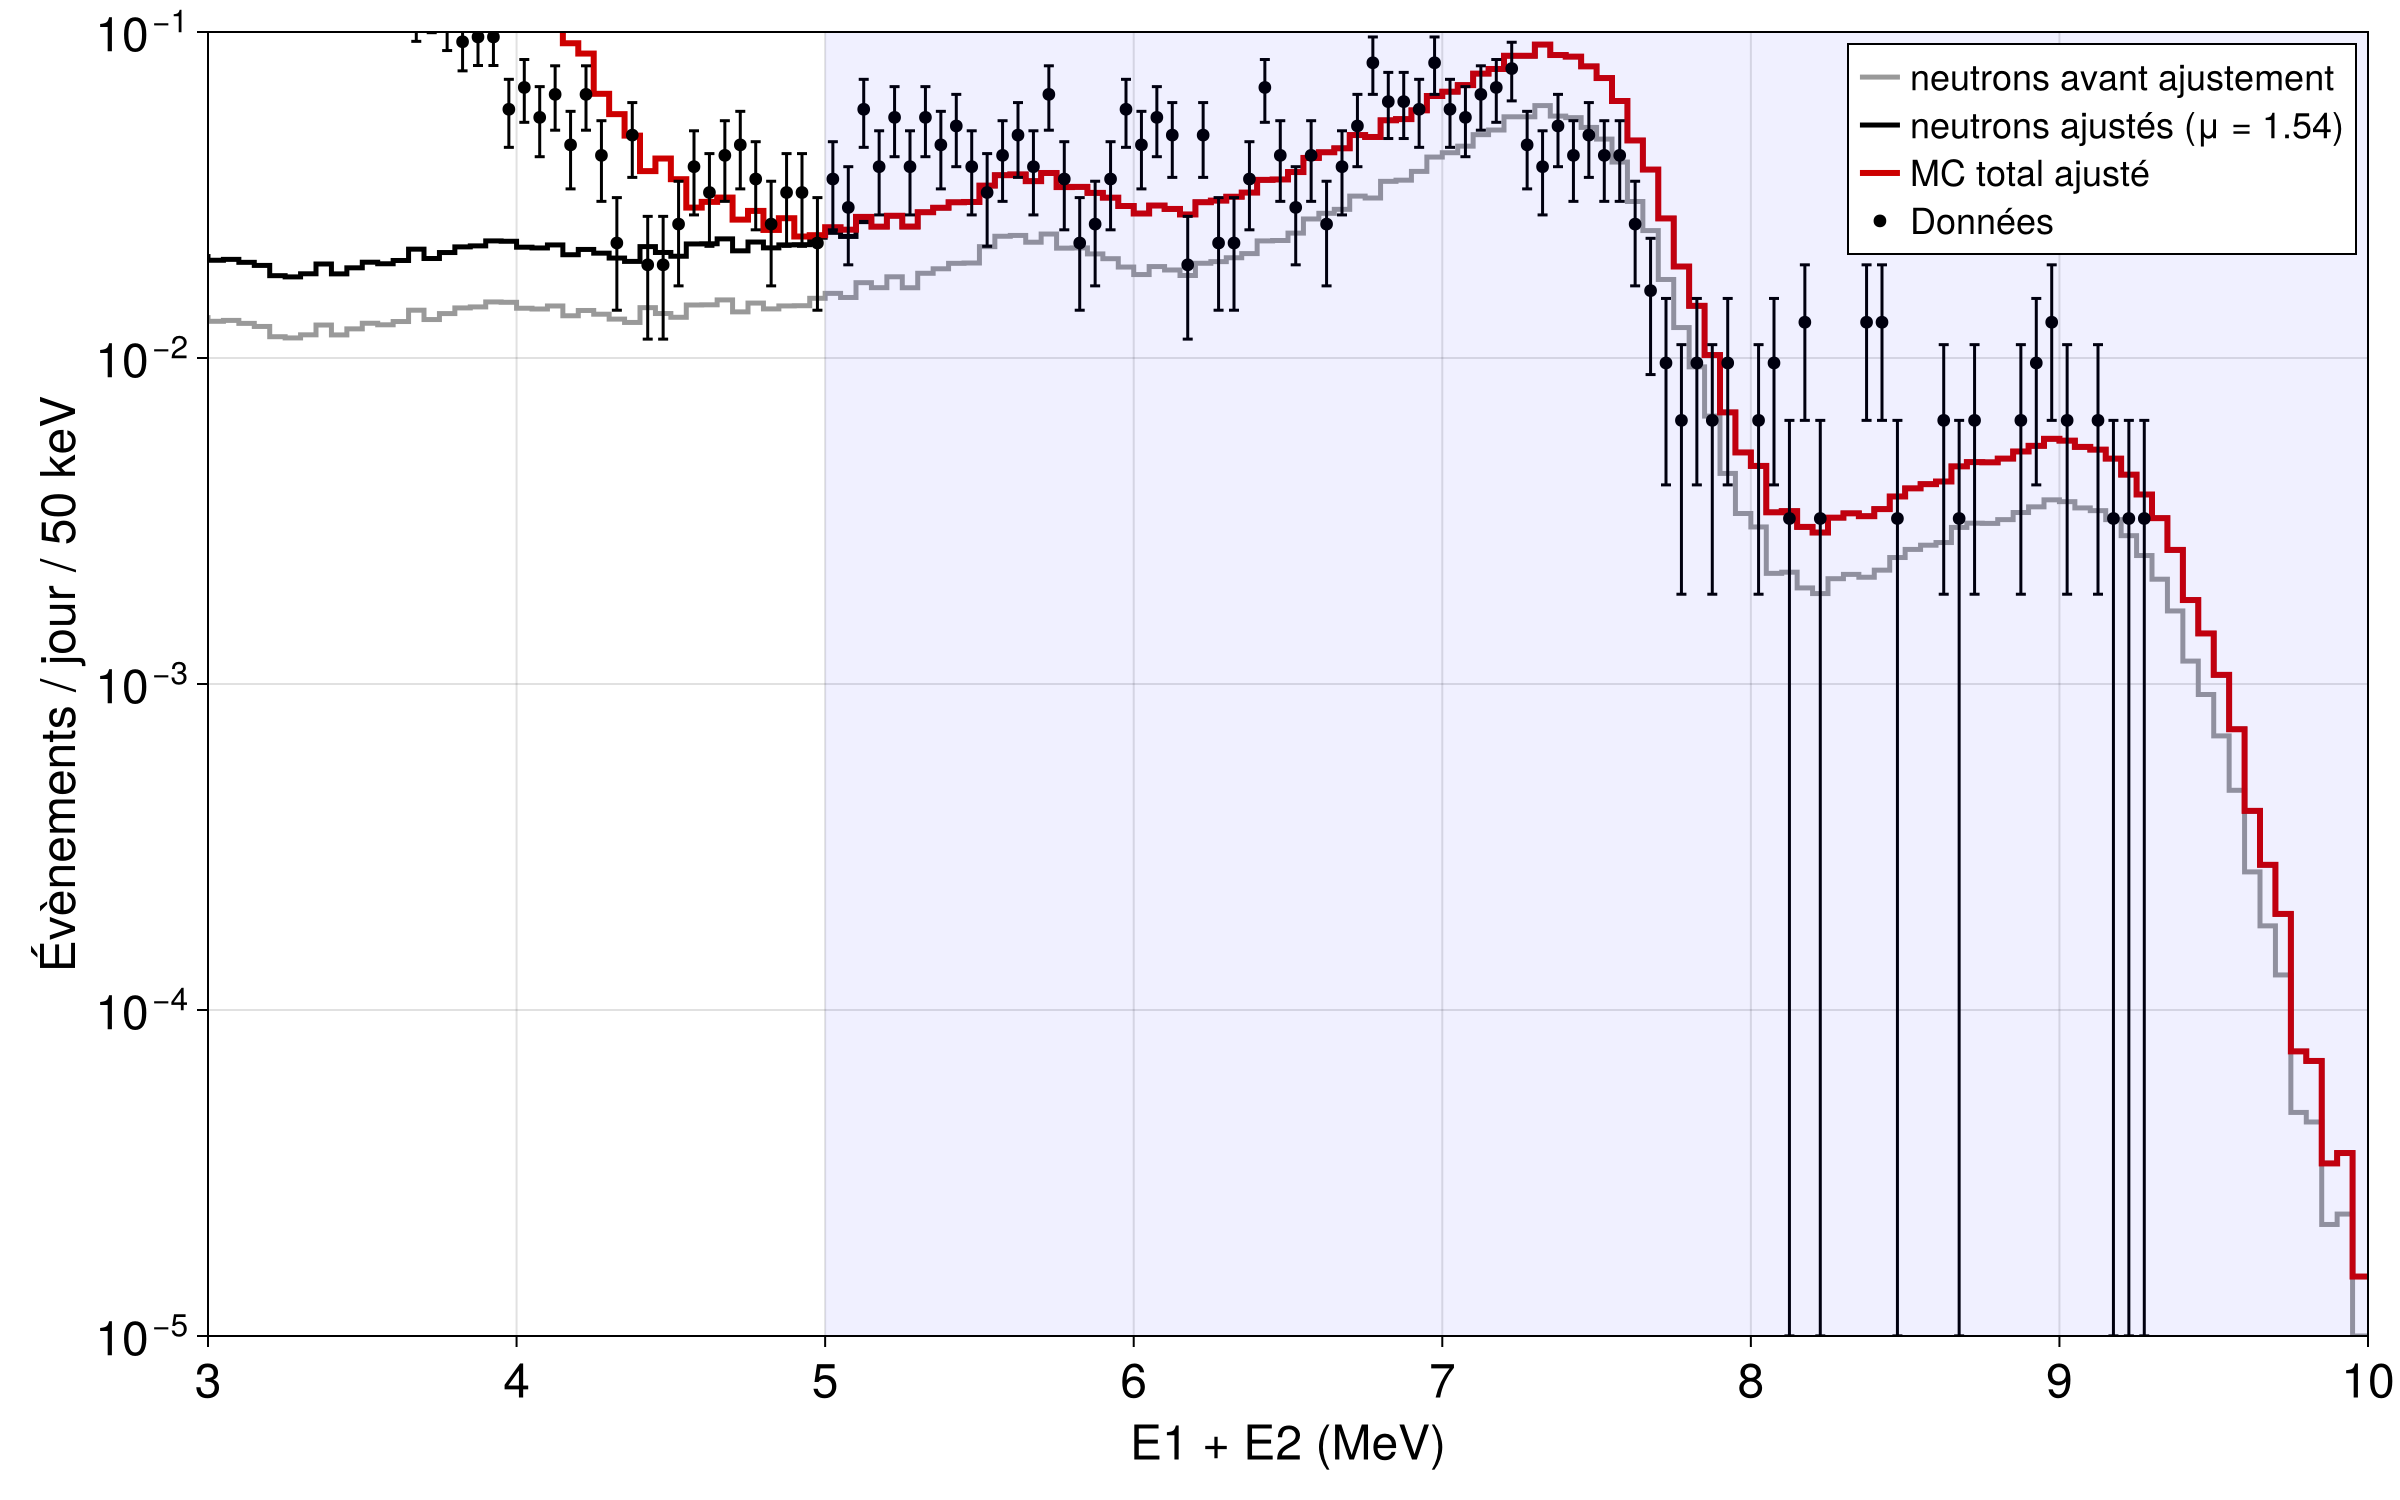

In [14]:
E_FIT_MIN  = 5.0
E_FIT_TEST = [4.5, 5.0, 6.0]
APPLY_FIT  = true

# facteur K correspondant à la normalisation actuelle (taux = sf · K / 2,845 an)
K_current() = neutron_rate_per_event(1.0, LIVE_S[PHASES[1]]) * 2.845 * YEAR
NEUTRON_MODE == :macro && error("L'ajustement suppose un taux constant : utiliser NEUTRON_MODE = :fit_ref, :constant ou :fitted.")

function fit_neutrons(emin)
    ctr = (EXT_EDGES[1:end-1] .+ EXT_EDGES[2:end]) ./ 2; sel = ctr .>= emin
    n  = sum(e[2] for e in EXT)[sel]                                          # données (comptes)
    nn = sum(e[1]["Neutrons"] for e in EXT)[sel]                              # neutrons (comptes, normalisation actuelle)
    a  = sum(sum(e[1][k] for k in EXT_GROUPS if k != "Neutrons") for e in EXT)[sel]
    lnL(μ) = sum(n[i] > 0 ? n[i] * log(a[i] + μ * nn[i]) - (a[i] + μ * nn[i]) : -(a[i] + μ * nn[i]) for i in eachindex(n))
    μs = range(0.0, 20.0, length = 40001); L = lnL.(max.(μs, 1e-9))
    i0 = argmax(L); μhat = μs[i0]
    inside = μs[L .>= L[i0] - 0.5]
    χ2(μ) = sum(n[i] > 0 ? (n[i] - a[i] - μ * nn[i])^2 / n[i] : 0.0 for i in eachindex(n))
    μchi = μs[argmin(χ2.(μs))]
    return (emin = emin, n_data = sum(n), n_mc_neutrons = sum(nn), n_other = sum(a), μ = μhat, μ_lo = first(inside), μ_hi = last(inside),
            μ_chi2 = μchi, μ_ratio = sum(nn) > 0 ? (sum(n) - sum(a)) / sum(nn) : NaN, nbins = length(n))
end

FITS = [fit_neutrons(e) for e in E_FIT_TEST]
display(DataFrame(FITS))
F = FITS[findfirst(f -> f.emin == E_FIT_MIN, FITS)]
K_FIT = F.μ * EXT_K; K_LO = F.μ_lo * EXT_K; K_HI = F.μ_hi * EXT_K
println("Au-dessus de $(E_FIT_MIN) MeV : $(round(Int, F.n_data)) évènements observés, $(round(F.μ * F.n_mc_neutrons + F.n_other, digits = 1)) ajustés")
println("μ = $(round(F.μ, digits = 3)) [$(round(F.μ_lo, digits = 3)) ; $(round(F.μ_hi, digits = 3))]  (χ² : $(round(F.μ_chi2, digits = 3)), rapport : $(round(F.μ_ratio, digits = 3)))")
println("→ NEUTRON_K = $(K_FIT)   (1σ : [$(K_LO) ; $(K_HI)])   ; K utilisé en 4b = $(EXT_K)")
println("  Équivalent « facteur 0,29 » de draw_all_separate : $(round(sqrt(F.μ) * NEUTRON_FIT, digits = 3)) (si NEUTRON_MODE = :fit_ref)")

if APPLY_FIT && isdefined(Main, :SETS)
    ratio = K_FIT / K_current()
    for s in SETS, p in s.procs
        startswith(p.isotopeName, "n_") && set_activity!(p, p.activity * ratio)
    end
    global NEUTRON_K = K_FIT; global NEUTRON_MODE = :fitted
    println("Neutrons de SETS remis à l'échelle (×$(round(ratio, digits = 3))). NEUTRON_MODE = :fitted. Relance à partir de la section 5.")
end

# figure : spectre externe au-dessus de 3 MeV avant/après ajustement
let ctr = (EXT_EDGES[1:end-1] .+ EXT_EDGES[2:end]) ./ 2, days = T_TOT / DAY
    nn = sum(e[1]["Neutrons"] for e in EXT) ./ days
    a  = sum(sum(e[1][k] for k in EXT_GROUPS if k != "Neutrons") for e in EXT) ./ days
    dc = sum(e[2] for e in EXT); d = dc ./ days; de = sqrt.(dc) ./ days
    ymin = 1e-5
    f = Figure(size = (1200, 750), fontsize = 24)
    ax = Axis(f[1, 1], xlabel = "E1 + E2 (MeV)", ylabel = "Évènements / jour / 50 keV", yscale = log10)
    stairs!(ax, EXT_EDGES, vcat(max.(nn, ymin), max(nn[end], ymin)), step = :post, color = :gray60, linewidth = 2.5, label = "neutrons avant ajustement")
    stairs!(ax, EXT_EDGES, vcat(max.(F.μ .* nn, ymin), max(F.μ * nn[end], ymin)), step = :post, color = :black, linewidth = 2.5, label = "neutrons ajustés (μ = $(round(F.μ, digits = 2)))")
    stairs!(ax, EXT_EDGES, vcat(max.(a .+ F.μ .* nn, ymin), max(a[end] + F.μ * nn[end], ymin)), step = :post, color = :red3, linewidth = 3, label = "MC total ajusté")
    m = dc .> 0
    errorbars!(ax, ctr[m], d[m], min.(de[m], d[m] .- ymin * 1.001), de[m], color = :black, whiskerwidth = 5)
    scatter!(ax, ctr[m], d[m], color = :black, markersize = 9, label = "Données")
    vspan!(ax, E_FIT_MIN, 10, color = (:blue, 0.06))
    xlims!(ax, 3, 10); ylims!(ax, ymin, 1e-1)
    axislegend(ax, position = :rt, labelsize = 18)
    savefig(f, "neutron_fit_external")
end

## 5. Carte de sensibilité (E_min, E_max)

Pour chaque ROI $[E_{min}\,;E_{max}[$ :
$$\varepsilon\,T = \sum_p \varepsilon_p\, t_p, \qquad b = \sum_p b_p, \qquad T_{1/2} > \kappa\,\frac{\varepsilon\,T}{N_{exclus}(b)}, \qquad \kappa = \frac{\ln 2\, N_A}{W}\,M.$$

In [20]:
function sensitivity_map(sets)
    T = sum(s.t_s for s in sets)
    ε = nothing; b = nothing; tmpl = nothing
    for s in sets, p in s.procs
        if p.signal
            e = bincounts(p.efficiency) .* (s.t_s / T); ε = ε === nothing ? e : ε .+ e
        else
            h = get_bkg_counts(p); tmpl === nothing && (tmpl = h)
            b = b === nothing ? copy(bincounts(h)) : b .+ bincounts(h)
        end
    end
    tmap = deepcopy(tmpl)
    tmap.bincounts .= κ * (T / YEAR) .* ε ./ N_exclus.(b)
    I = argmax(bincounts(tmap))
    return (tmap = tmap, roi = (round(BINS[I[1]], digits = 3), round(BINS[I[2] + 1], digits = 3)),
            eff = ε[I], bkg = b[I], Nex = N_exclus(b[I]), tHalf = bincounts(tmap)[I],
            exposure = M_ISO * T / YEAR)
end

@time R = sensitivity_map(SETS)
N_OBS = sum(count(x -> R.roi[1] <= x < R.roi[2], s.data) for s in SETS)
println("ROI = $(R.roi) MeV, ε = $(round(100R.eff, digits = 2)) %, b = $(round(R.bkg, digits = 2)), N_exclus = $(round(R.Nex, digits = 2)), ",
        "observés = $N_OBS, T½ > $(sci(R.tHalf)) an ($(round(R.exposure, digits = 2)) kg·an)")

let
    f = with_theme(theme_latexfonts()) do
        f = Figure(size = (1300, 1050), fontsize = 30)
        zoom = (2.0, 3.6)
        ax = Axis(f[1, 1], xlabel = "E_min de la ROI (MeV) / $(round(Int, 1000BIN_WIDTH)) keV",
                  ylabel = "E_max de la ROI (MeV) / $(round(Int, 1000BIN_WIDTH)) keV", aspect = 1)
        p = plot!(ax, R.tmap, colormap = :viridis)
        lines!(ax, [zoom...], [zoom...], color = :gray, linestyle = :dot)
        scatter!(ax, [R.roi[1]], [R.roi[2]], color = :red, marker = :xcross, markersize = 28, strokewidth = 2)
        text!(ax, zoom[1] + 0.05, zoom[2] - 0.05, align = (:left, :top), fontsize = 24,
              text = "ROI = [$(R.roi[1]) ; $(R.roi[2])[ MeV\nT½ > $(sci(R.tHalf)) an\nε = $(round(100R.eff, digits = 1)) %, b = $(round(R.bkg, digits = 1))")
        limits!(ax, zoom..., zoom...)
        Colorbar(f[1, 2], p, label = L"T_{1/2}^{0\nu}\;\mathrm{(an)}")
        f
    end
    savefig(f, "sensitivity_map")
end

LoadError: UndefVarError: `SETS` not defined

## 6. Sensibilité avec et sans la phase 0

La phase 0 correspond au tout début de la prise de données, avec une activité du radon élevée et une configuration du détecteur différente des
phases suivantes. On compare la sensibilité obtenue avec toutes les phases et sans la phase 0, chacune avec sa ROI ré-optimisée.

In [15]:
SETS_NO0 = [s for s in SETS if s.phase != "0"]
R0 = sensitivity_map(SETS_NO0)
n_obs(sets, roi) = sum(count(x -> roi[1] <= x < roi[2], s.data) for s in sets)
CMP = DataFrame(
    configuration = ["Toutes les phases (0 à 4)", "Sans la phase 0 (1 à 4)"],
    jours         = [round(sum(s.t_s for s in SETS) / DAY, digits = 2), round(sum(s.t_s for s in SETS_NO0) / DAY, digits = 2)],
    exposition    = [round(R.exposure, digits = 2), round(R0.exposure, digits = 2)],
    ROI           = [R.roi, R0.roi],
    eff_pct       = [round(100R.eff, digits = 2), round(100R0.eff, digits = 2)],
    b             = [round(R.bkg, digits = 2), round(R0.bkg, digits = 2)],
    N_exclus      = [round(R.Nex, digits = 2), round(R0.Nex, digits = 2)],
    observes      = [n_obs(SETS, R.roi), n_obs(SETS_NO0, R0.roi)],
    T12           = [sci(R.tHalf), sci(R0.tHalf)])
CSV.write(joinpath(OUT_DIR, "sensitivity_with_without_phase0.csv"), CMP)

tex_num(x; d = 2) = replace(Printf.format(Printf.Format("%.$(d)f"), x), "." => "{,}")
tex_sci(x) = (e = floor(Int, log10(x)); "\$" * tex_num(x / 10.0^e) * " \\times 10^{$e}\$")
let io = IOBuffer()
    println(io, "\\begin{tabular}{lcc}\n\\toprule")
    println(io, " & Phases 0 à 4 & Phases 1 à 4 \\\\\n\\midrule")
    println(io, "Durée d'acquisition (jours) & ", tex_num(CMP.jours[1]), " & ", tex_num(CMP.jours[2]), " \\\\")
    println(io, "Exposition (kg\$\\cdot\$an) & ", tex_num(R.exposure), " & ", tex_num(R0.exposure), " \\\\")
    println(io, "ROI (MeV) & \$[", tex_num(R.roi[1]), "\\,;\\,", tex_num(R.roi[2]), "[\$ & \$[", tex_num(R0.roi[1]), "\\,;\\,", tex_num(R0.roi[2]), "[\$ \\\\")
    println(io, "Efficacité \$\\varepsilon\$ (\\%) & ", tex_num(100R.eff; d = 1), " & ", tex_num(100R0.eff; d = 1), " \\\\")
    println(io, "Bruit de fond attendu \$b\$ & ", tex_num(R.bkg; d = 1), " & ", tex_num(R0.bkg; d = 1), " \\\\")
    println(io, "\$N_{\\rm exclus}(b)\$ & ", tex_num(R.Nex; d = 1), " & ", tex_num(R0.Nex; d = 1), " \\\\")
    println(io, "Évènements observés & ", CMP.observes[1], " & ", CMP.observes[2], " \\\\\n\\midrule")
    println(io, "\$T_{1/2}^{0\\nu}\$ (ans, 90~\\% CL) & ", tex_sci(R.tHalf), " & ", tex_sci(R0.tHalf), " \\\\")
    println(io, "\\bottomrule\n\\end{tabular}")
    write(joinpath(OUT_DIR, "table_phase0.tex"), String(take!(io)))
end
CMP

Row,configuration,jours,exposition,ROI,eff_pct,b,N_exclus,observes,T12
,String,Float64,Float64,Tuple…,Float64,Float64,Float64,Int64,String
1,Toutes les phases (0 à 4),310.71,5.2,"(2.7, 3.05)",8.1,21.46,9.32,22,"2,3×10²³"
2,Sans la phase 0 (1 à 4),272.8,4.56,"(2.7, 3.05)",8.06,16.12,8.22,17,"2,28×10²³"


## 7. Spectre pour la thèse

Toutes phases combinées, en évènements sur l'exposition totale, échelle log, avec la ROI et le signal à la sensibilité obtenue.

In [16]:
# =====================================================================================
# Spectre final pour la thèse : couleurs/légende du spectre précédent (PMTs séparés en ²¹⁴Bi / ²⁰⁸Tl / ⁴⁰K),
# signal 0νββ (T½ = R.tHalf), ROI, et χ²/ndf affiché comme sur la figure de la macro.
# χ² = Σ (D − MC)² / (σ_D² + σ_MC²), σ_D = √D, σ_MC = √Σw², sur les bins où D > 0 ET MC > 0 (comme merge_phase_spectra.C),
# sur tout l'histogramme 0–5 MeV par défaut (chi2_range pour restreindre) ; ndf = nombre de bins.
# Sauvegardé en PDF (et PNG) dans OUT_DIR sous le nom fname.
# =====================================================================================
SPEC_BIN = 0.1
stairs_y(c) = vcat(c, c[end])
# mêmes composantes, noms et couleurs que merge_phase_spectra.C
SPEC_GROUPS_PLOT = ["MC 2νββ", "MC Radon", "MC ²³⁸U", "MC ²³⁴Pa", "MC ⁴⁰K", "MC ²³²Th", "MC verre des PMTs", "MC Neutrons"]
SPEC_COLORS = Dict("MC 2νββ" => :gold, "MC Radon" => :magenta, "MC ²³⁸U" => :purple, "MC ²³⁴Pa" => :green,
                   "MC ⁴⁰K" => :deepskyblue, "MC ²³²Th" => :blue, "MC verre des PMTs" => :darkorange, "MC Neutrons" => :gray70)
function spec_group_plot(name)
    startswith(name, "n_") && return "MC Neutrons"
    endswith(name, "pmt")  && return "MC verre des PMTs"                       # tous les PMTs (8", 5", x-wall, γ-veto) ensemble
    name == "bb2nu"                          && return "MC 2νββ"
    name in ("radon", "radon_surface")       && return "MC Radon"
    name in ("214Bi", "214Pb", "210Bi")      && return "MC ²³⁸U"               # chaîne ²³⁸U (bas de chaîne)
    name in ("234Pa", "234Th")               && return "MC ²³⁴Pa"               # chaîne ²³⁸U (haut de chaîne)
    name == "40K"                            && return "MC ⁴⁰K"
    name in ("208Tl", "212Bi", "212Pb", "228Ac") && return "MC ²³²Th"           # chaîne ²³²Th
    error("composante non classée : $name")
end

function plot_spectrum_chi2(sets; per_day = false, logy = true, xrange = (0.0, 5.0), roi = nothing, tHalf = nothing,
                            fname = "spectrum_chi2", ylim = nothing, chi2_range = nothing)
    edges = collect(0:SPEC_BIN:5); nb = length(edges) - 1
    g = Dict(k => zeros(nb) for k in SPEC_GROUPS_PLOT); g2 = Dict(k => zeros(nb) for k in SPEC_GROUPS_PLOT); w2 = zeros(nb); sig = zeros(nb); d = zeros(nb)
    function addw!(v, x, w; v2 = nothing)
        for xi in x
            i = searchsortedlast(edges, xi)
            1 <= i <= nb || continue
            v[i] += w; v2 === nothing || (v2[i] += w^2)
        end
    end
    for s in sets
        for p in s.procs
            if p.signal
                tHalf === nothing || addw!(sig, p.dataVector, κ * (s.t_s / YEAR) / (tHalf * p.nTotalSim))
            else
                grp = spec_group_plot(p.isotopeName); wp = p.activity * p.amount * p.timeMeas / p.nTotalSim
                addw!(g[grp], p.dataVector, wp; v2 = w2)
                addw!(zeros(nb), p.dataVector, wp; v2 = g2[grp])                 # Σw² par composante
            end
        end
        addw!(d, s.data, 1.0)
    end
    days = sum(s.t_s for s in sets) / DAY
    sc   = per_day ? 1 / days : 1.0
    ctr  = (edges[1:end-1] .+ edges[2:end]) ./ 2
    mc   = sum(values(g))

    # χ² sur la fenêtre affichée
    # même définition que merge_phase_spectra.C : bins avec données > 0 ET MC > 0, sur tout l'histogramme (0–5 MeV)
    lo_c, hi_c = chi2_range === nothing ? (edges[1], edges[end]) : chi2_range
    inx = (ctr .>= lo_c) .& (ctr .< hi_c) .& (d .> 0) .& (mc .> 0)
    chi2 = sum(((d .- mc) .^ 2 ./ (d .+ w2))[inx]); ndf = count(inx)

    ymin = ylim !== nothing ? ylim[1] : (logy ? (per_day ? 1e-3 : 1e-1) : 0.0)
    f = Figure(size = (1100, 1100), fontsize = 26)
    ax  = Axis(f[1, 1], ylabel = per_day ? "Évènements / jour / 100 keV" : "Évènements / 100 keV", yscale = logy ? log10 : identity)
    axr = Axis(f[2, 1], xlabel = "E₁ + E₂ (MeV)", ylabel = "100×(Données−MC)/MC [%]")
    linkxaxes!(ax, axr); hidexdecorations!(ax, grid = false, ticks = false); rowsize!(f.layout, 2, Relative(0.28)); rowgap!(f.layout, 6)
    if roi !== nothing
        vspan!(ax, roi..., color = (:red, 0.12), label = "ROI [$(roi[1]) ; $(roi[2])[ MeV")
        vspan!(axr, roi..., color = (:red, 0.12))
    end
    for k in SPEC_GROUPS_PLOT
        any(g[k] .> 0) || continue
        stairs!(ax, edges, stairs_y(max.(g[k] .* sc, ymin)), step = :post, color = SPEC_COLORS[k], linewidth = 2.5, label = k)
    end
    emc = sqrt.(w2)
    stairs!(ax, edges, stairs_y(max.(mc .* sc, ymin)), step = :post, color = :red3, linewidth = 4, label = "MC Total")
    # erreurs statistiques MC (√Σw²) au centre des bins, par-dessus chaque histogramme MC (option « E » de ROOT)
    for k in SPEC_GROUPS_PLOT
        mk = g[k] .> 0
        any(mk) || continue
        e = sqrt.(g2[k][mk]) .* sc; y = g[k][mk] .* sc
        errorbars!(ax, ctr[mk], y, clamp.(y .- ymin * 1.001, 0, e), e, color = SPEC_COLORS[k], linewidth = 1.5, whiskerwidth = 4)
    end
    mt = mc .> 0
    errorbars!(ax, ctr[mt], mc[mt] .* sc, clamp.(mc[mt] .* sc .- ymin * 1.001, 0, emc[mt] .* sc), emc[mt] .* sc,
               color = :red3, linewidth = 2, whiskerwidth = 5)
    tHalf === nothing || stairs!(ax, edges, stairs_y(max.(sig .* sc, ymin)), step = :post, color = :black, linestyle = :dash,
                                 linewidth = 3, label = "0νββ, T½ = $(sci(tHalf)) an")
    m = d .> 0
    # erreurs √N sur les données (barre basse arrêtée au bas de l'axe en échelle log)
    lo = min.(sqrt.(d[m]) .* sc, d[m] .* sc .- ymin * 1.001)
    errorbars!(ax, ctr[m], d[m] .* sc, lo, sqrt.(d[m]) .* sc, color = :black, whiskerwidth = 6)
    scatter!(ax, ctr[m], d[m] .* sc, color = :black, markersize = 11, label = "Données")
    k = (d .> 0) .& (mc .> 0)
    # erreur du rapport comme dans merge_phase_spectra.C : données (√N) et MC (√Σw²)
    rerr = 100 .* sqrt.(d[k] ./ mc[k] .^ 2 .+ (d[k] .^ 2 .* w2[k]) ./ mc[k] .^ 4)
    errorbars!(axr, ctr[k], 100 .* (d[k] .- mc[k]) ./ mc[k], rerr, color = :black, whiskerwidth = 6)
    scatter!(axr, ctr[k], 100 .* (d[k] .- mc[k]) ./ mc[k], color = :black, markersize = 9)
    hlines!(axr, [0], color = :black, linestyle = :dash)
    xlims!(ax, xrange...); ylims!(axr, -100, 100)
    if ylim !== nothing
        ylims!(ax, ylim...)
    else
        logy ? ylims!(ax, ymin, 3 * maximum(mc .* sc)) : ylims!(ax, 0, 1.15 * maximum(d .* sc))
    end
    text!(ax, 0.03, 0.96, space = :relative, align = (:left, :top), fontsize = 30,
          text = "χ²/ndf = $(round(chi2, digits = 1)) / $ndf = $(round(chi2 / ndf, digits = 2))")
    # légende dans l'ordre de la macro : Données, composantes MC, MC Total (+ 0νββ et ROI)
    els = Any[[LineElement(color = :black, points = Point2f[(0.5, 0), (0.5, 1)]), MarkerElement(color = :black, marker = :circle, markersize = 11)]]
    labs = ["Données"]
    for k in SPEC_GROUPS_PLOT
        any(g[k] .> 0) || continue
        push!(els, LineElement(color = SPEC_COLORS[k], linewidth = 2.5)); push!(labs, k)
    end
    push!(els, LineElement(color = :red3, linewidth = 4)); push!(labs, "MC Total")
    tHalf === nothing || (push!(els, LineElement(color = :black, linestyle = :dash, linewidth = 3)); push!(labs, "0νββ, T½ = $(sci(tHalf)) an"))
    roi === nothing   || (push!(els, PolyElement(color = (:red, 0.12))); push!(labs, "ROI [$(roi[1]) ; $(roi[2])[ MeV"))
    axislegend(ax, els, labs, position = :rt, framevisible = true, labelsize = 20, rowgap = 0, backgroundcolor = :white)
    println("χ²/ndf = $(round(chi2, digits = 1)) / $ndf = $(round(chi2 / ndf, digits = 2))  (bins D > 0 et MC > 0 entre $(lo_c) et $(hi_c) MeV)")
    savefig(f, fname)
end

# R (ROI optimale et T½) vient de la section 5 ; s'il n'existe pas, on le recalcule ici (quelques secondes)
if !@isdefined(R)
    function sensitivity_map(sets)
        T = sum(s.t_s for s in sets); ε = nothing; b = nothing; tmpl = nothing
        for s in sets, p in s.procs
            if p.signal
                e = bincounts(p.efficiency) .* (s.t_s / T); ε = ε === nothing ? e : ε .+ e
            else
                h = get_bkg_counts(p); tmpl === nothing && (tmpl = h)
                b = b === nothing ? copy(bincounts(h)) : b .+ bincounts(h)
            end
        end
        tmap = deepcopy(tmpl); tmap.bincounts .= κ * (T / YEAR) .* ε ./ N_exclus.(b)
        I = argmax(bincounts(tmap))
        return (tmap = tmap, roi = (round(BINS[I[1]], digits = 3), round(BINS[I[2] + 1], digits = 3)),
                eff = ε[I], bkg = b[I], Nex = N_exclus(b[I]), tHalf = bincounts(tmap)[I], exposure = M_ISO * T / YEAR)
    end
    global R = sensitivity_map(SETS)
end
println("ROI = $(R.roi) MeV, T½ > $(sci(R.tHalf)) an")

display(plot_spectrum_chi2(SETS; per_day = true, logy = true, xrange = (0.5, 4.0), roi = R.roi, tHalf = R.tHalf,
                           fname = "spectrum_sensitivity", ylim = (1e-5, 20)))

# comparaison avec merge_phase_spectra_without_0.C (phases 1 à 4 seulement, sans la phase 0) :
display(plot_spectrum_chi2([s for s in SETS if s.phase != "0"]; per_day = true, logy = true, xrange = (0.5, 4.0),
                           roi = R.roi, tHalf = R.tHalf, fname = "spectrum_sensitivity_sans_phase0", ylim = (1e-5, 20)))

ROI = (2.7, 3.05) MeV, T½ > 2,3×10²³ an
χ²/ndf = 35.6 / 27 = 1.32  (bins D > 0 et MC > 0 entre 0.0 et 5.0 MeV)


LoadError: Failed to resolve [31mcairo_attributes:[39m
[ComputeEdge] [31mcairo_attributes[39m = #17(([92mpositions_in_markerspace[39m, [92mprojectionview[39m, [92meye_to_clip[39m, [92mcam_view[39m, [92mmarkersize[39m, [92mstrokewidth[39m, [92mcairo_marker[39m, [92mmarker_offset[39m, [92mconverted_rotation[39m, [92mbillboard[39m, [92mtransform_marker[39m, [92msize_model[39m, [92mmarkerspace[39m, [92mspace[39m, [92mclip_planes[39m, [92munclipped_indices[39m, [92mfont[39m, [92mstrokecolor[39m, [31mcomputed_color[39m, [90mresolution[39m, ), changed, cached)
[90m  @ /pbs/home/m/mgranjon/.julia/packages/CairoMakie/9K2tG/src/utils.jl:4[39m
[ComputeEdge] [31mcomputed_color[39m = #1949(([92mscaled_color[39m, [92mscaled_colorrange[39m, [31malpha_colormap[39m, [90mnan_color[39m, [90mlowclip_color[39m, [90mhighclip_color[39m, [90mcolor_mapping_type[39m, ), changed, cached)
[90m  @ /pbs/home/m/mgranjon/.julia/packages/Makie/WKgwk/src/ba

In [8]:
# ===== Sensibilité en fonction du temps : toutes phases + phase 4 seule (radon mesuré, 1 et 0,1 mBq/m³) =====
# Cartes (E_min, E_max) calculées une seule fois par phase, puis mises à l'échelle avec le temps vivant.
# Un point par courbe à DATA_END, puis projection. Utilise les variables de la cellule précédente (section 9).
RADON_ALT = [1e-3, 0.1e-3]                      # Bq/m³

function roi_maps(s)                            # Σ ε·t [s], b radon, b autres (cartes E_min × E_max)
    et = zeros(size(bincounts(s.procs[1].efficiency))); bR = zero(et); bO = zero(et)
    for p in s.procs
        if p.signal; et .+= bincounts(p.efficiency) .* s.t_s
        elseif p.isotopeName in ("radon", "radon_surface"); bR .+= bincounts(get_bkg_counts(p))
        else; bO .+= bincounts(get_bkg_counts(p)); end
    end
    (t = s.t_s, et = et, bR = bR, bO = bO)
end
@time MAPS = Dict(zip([s.phase for s in SETS], fetch.([Threads.@spawn roi_maps(s) for s in SETS])))
best(et, b) = maximum(κ .* (et ./ YEAR) ./ N_exclus.(b))

PR_D  = sort(unique(vcat([Date(y, m, 1) for y in 2026:2028 for m in 1:12 if DATA_END < Date(y, m, 1) <= PLOT_END], MARK_DATES)))
extra(d) = Dates.value(d - DATA_END) * DUTY * DAY
m4  = MAPS["4"]; fR = [A / RADON_BQ_M3["4"] for A in RADON_ALT]
b4(f) = m4.bO .+ f .* m4.bR
etA = sum(m.et for m in values(MAPS)); bA = sum(m.bR .+ m.bO for m in values(MAPS))

function curve(et0, b0, b4f)                    # T½ à DATA_END puis aux dates de projection (threads)
    pr = zeros(length(PR_D))
    Threads.@threads for k in eachindex(PR_D)
        x = extra(PR_D[k]) / m4.t; pr[k] = best(et0 .+ m4.et .* x, b0 .+ b4f .* x)
    end
    (T0 = best(et0, b0), proj = pr)
end
CURVES = [("toutes phases", :black, :tomato, "", curve(etA, bA, b4(1.0))),
          ("phase 4 seule ($(round(1e3RADON_BQ_M3["4"], digits = 1)) mBq/m³)", :royalblue, :royalblue, "_p4", curve(m4.et, b4(1.0), b4(1.0))),
          ("phase 4 seule (1 mBq/m³)",   :seagreen,   :seagreen,   "_p4_1mBq",   curve(m4.et, b4(fR[1]), b4(fR[1]))),
          ("phase 4 seule (0,1 mBq/m³)", :darkorange, :darkorange, "_p4_0p1mBq", curve(m4.et, b4(fR[2]), b4(fR[2])))]
ix(d) = findfirst(==(d), PR_D)
for (lab, _, _, _, c) in CURVES
    println(rpad(lab, 30), " : $DATA_END → $(sci(c.T0)) an  |  ", join(["$d → $(sci(c.proj[ix(d)])) an" for d in MARK_DATES], "  |  "))
end

function time_fig(curves, name; labels = true)
    f = Figure(size = (1300, 750), fontsize = 26)
    ax = Axis(f[1, 1], xlabel = "Date", ylabel = "T½ 0νββ (an), 90 % CL", yscale = log10)
    vspan!(ax, xday(DATA_START), xday(DATA_END), color = (:gray, 0.08), label = "données analysées")
    for (lab, c0, cp, _, c) in curves
        scatter!(ax, [xday(DATA_END)], [c.T0], color = c0, markersize = 16, label = lab * " (données analysées)")
        lines!(ax, xday.(vcat([DATA_END], PR_D)), vcat([c.T0], c.proj), color = cp, linestyle = :dash, linewidth = 3, label = lab * " (projection)")
        scatter!(ax, xday.(MARK_DATES), [c.proj[ix(d)] for d in MARK_DATES], color = cp, marker = :diamond, markersize = 18)
        if labels
            text!(ax, xday(DATA_END), c.T0, text = "  $(sci(c.T0; d = 1)) an", align = (:left, :top), fontsize = 20, color = c0)
            for d in MARK_DATES
                text!(ax, xday(d), c.proj[ix(d)], text = "$(sci(c.proj[ix(d)]; d = 1)) an", align = (:center, :bottom),
                      offset = (0, 12), fontsize = 20, color = cp)
            end
        end
    end
    ticks = [Date(y, m, 1) for y in 2025:2028 for m in (1, 7) if DATA_START <= Date(y, m, 1) <= PLOT_END]
    ax.xticks = (xday.(ticks), ["$(MOIS[month(t)]) $(year(t))" for t in ticks])
    tk = [2e22, 5e22, 1e23, 2e23, 5e23, 1e24, 2e24, 5e24]; ax.yticks = (tk, [sci(x; d = 0) for x in tk])
    xlims!(ax, 0, xday(PLOT_END))
    axislegend(ax, position = length(curves) > 1 ? :lt : :rb, labelsize = length(curves) > 1 ? 15 : 18)
    savefig(f, name); display(f)
end
for C in CURVES; time_fig([C], "sensitivity_vs_time" * C[4]); end
time_fig(CURVES, "sensitivity_vs_time_compar"; labels = false)

LoadError: UndefVarError: `SETS` not defined

In [17]:
# =====================================================================================
# Tableau LaTeX « tab_sensibilite » (à mettre juste après le plot de sensibilité)
# Attendus par contribution entre 0,5 et 3,2 MeV et dans la ROI (R.roi), avec erreurs statistiques :
#   MC : √Σw² (w = A·t_p/N_sim par évènement simulé), données : √N.  Dernière colonne : part du bruit de fond dans la ROI.
# Sortie : OUT_DIR/table_sensibilite.tex (bloc table complet, à \input dans la thèse)
# =====================================================================================
TAB_WIN = [(0.5, 3.2), R.roi]
TAB_GROUPS = ["2νββ", "Radon (95 % vol + 5 % surf)", "Bi-214 source", "Pa-234m source", "K-40 source", "Tl-208 source",
              "Autres source", "Verre des PMTs", "Neutrons"]
TAB_LATEX = Dict("2νββ" => raw"$\beta\beta2\nu$", "Radon (95 % vol + 5 % surf)" => "Radon (gaz et surface)",
                 "Bi-214 source" => raw"$^{214}$Bi (source)", "Pa-234m source" => raw"$^{234m}$Pa (source)",
                 "K-40 source" => raw"$^{40}$K (source)", "Tl-208 source" => raw"$^{208}$Tl (source)",
                 "Autres source" => "Autres (source)", "Verre des PMTs" => "Verre des PMTs", "Neutrons" => "Neutrons")
tab_group(name) = startswith(name, "n_") ? "Neutrons" : GROUP_SPEC[name]

# sommes Σw et Σw² par groupe et par fenêtre
S1 = Dict(k => zeros(length(TAB_WIN)) for k in TAB_GROUPS); S2 = deepcopy(S1)
for s in SETS, p in s.procs
    p.signal && continue
    w = p.activity * p.amount * p.timeMeas / p.nTotalSim; k = tab_group(p.isotopeName)
    for (j, (lo, hi)) in enumerate(TAB_WIN)
        n = count(E -> lo <= E < hi, p.dataVector)
        S1[k][j] += n * w; S2[k][j] += n * w^2
    end
end
TOT1 = [sum(S1[k][j] for k in TAB_GROUPS) for j in eachindex(TAB_WIN)]
TOT2 = [sum(S2[k][j] for k in TAB_GROUPS) for j in eachindex(TAB_WIN)]
NDAT = [sum(count(E -> lo <= E < hi, s.data) for s in SETS) for (lo, hi) in TAB_WIN]
DAYS = sum(s.t_s for s in SETS) / DAY

# mise en forme : erreur à 2 chiffres significatifs, valeur arrondie au même rang, virgule décimale
dec(x) = replace(x, "." => "{,}")
function pm(v, e)
    v == 0 && return "--"
    nd = max(0, 1 - floor(Int, log10(e)))
    fmt(x) = nd == 0 ? string(round(Int, x)) : string(round(x, digits = nd))
    return "\$" * dec(fmt(v)) * " \\pm " * dec(fmt(e)) * "\$"
end
pct(x) = x == 0 ? "--" : dec(string(round(x, digits = 1)))
roi_str = "ROI \$[" * dec(@sprintf("%.2f", R.roi[1])) * "\\,;\\," * dec(@sprintf("%.2f", R.roi[2])) * "[\$"

io = IOBuffer()
println(io, "\\begin{table}[H]\n\\centering\n\\small\n\\begin{tabular}{lccc}\n\\toprule")
println(io, "Contribution & 0,5 -- 3,2 MeV & $roi_str & ROI (\\%) \\\\\n\\midrule")
for k in TAB_GROUPS
    println(io, TAB_LATEX[k], " & ", pm(S1[k][1], sqrt(S2[k][1])), " & ", pm(S1[k][2], sqrt(S2[k][2])), " & ",
            pct(100 * S1[k][2] / TOT1[2]), " \\\\")
end
println(io, "\\midrule")
println(io, "MC total & ", pm(TOT1[1], sqrt(TOT2[1])), " & ", pm(TOT1[2], sqrt(TOT2[2])), " & 100 \\\\")
println(io, "Données & ", pm(NDAT[1], sqrt(NDAT[1])), " & ", pm(NDAT[2], sqrt(NDAT[2])), " & \\\\")
println(io, "\\bottomrule\n\\end{tabular}")
println(io, "\\caption{\\centering \\small  Nombre d'événements attendus pour chaque contribution après application des sélections double bêta, ",
            "entre 0,5 et 3,2~MeV et dans la ROI, pour ", dec(@sprintf("%.2f", DAYS)), " jours de données.}")
println(io, "\\label{tab_sensibilite}\n\\end{table}")
TAB_TEX = String(take!(io))
write(joinpath(OUT_DIR, "table_sensibilite.tex"), TAB_TEX)
print(TAB_TEX)
println("\n→ ", joinpath(OUT_DIR, "table_sensibilite.tex"))

\begin{table}[H]
\centering
\small
\begin{tabular}{lccc}
\toprule
Contribution & 0,5 -- 3,2 MeV & ROI $[2{,}70\,;\,3{,}05[$ & ROI (\%) \\
\midrule
$\beta\beta2\nu$ & $9337{,}1 \pm 5{,}5$ & $0{,}15 \pm 0{,}021$ & 0{,}7 \\
Radon (gaz et surface) & $1383{,}4 \pm 5{,}3$ & $19{,}35 \pm 0{,}63$ & 90{,}2 \\
$^{214}$Bi (source) & $35{,}161 \pm 0{,}059$ & $0{,}4173 \pm 0{,}0065$ & 1{,}9 \\
$^{234m}$Pa (source) & $1439{,}0 \pm 2{,}6$ & -- & -- \\
$^{40}$K (source) & $149{,}05 \pm 0{,}97$ & -- & -- \\
$^{208}$Tl (source) & $3{,}719 \pm 0{,}032$ & $0{,}1997 \pm 0{,}0069$ & 0{,}9 \\
Autres (source) & $9{,}306 \pm 0{,}085$ & -- & -- \\
Verre des PMTs & $661{,}3 \pm 8{,}3$ & $1{,}09 \pm 0{,}26$ & 5{,}1 \\
Neutrons & $2{,}103 \pm 0{,}074$ & $0{,}25 \pm 0{,}028$ & 1{,}2 \\
\midrule
MC total & $13020 \pm 12$ & $21{,}46 \pm 0{,}69$ & 100 \\
Données & $12924 \pm 114$ & $22{,}0 \pm 4{,}7$ & \\
\bottomrule
\end{tabular}
\caption{\centering \small  Nombre d'événements attendus pour chaque contribution après 

## 8. Sensibilité en fonction de l'erreur sur l'échelle en énergie

On multiplie **toutes les énergies simulées** (signal et bruits de fond) par $(1 + x)$, avec $x$ de 0 à 5 %, en gardant la **ROI optimale
fixe**, puis on recalcule $\varepsilon$, $b$ et $T_{1/2}$. Cela revient à supposer que l'énergie mesurée est surestimée de $x$ par rapport
à la simulation (erreur d'étalonnage), alors que la ROI a été choisie sur la simulation nominale.

Ici on simule l'énergie E' = E + δ·E·g, où g est un nombre tiré dans une gaussienne centrée sur 0 et de largeur 1.

ROI [2.7 ; 3.05[ — δ = 0 : T½ > 2,3×10²³ an
δ = 1 % (étalement) : T½ > 2,25×10²³ an  (-2.2 %)
→ /sps/nemo/scratch/granjon/sensitivity_from_Maros_training/SN_Sensitivity_training/data/out/ex8/sensitivity_vs_energy_uncertainty.pdf


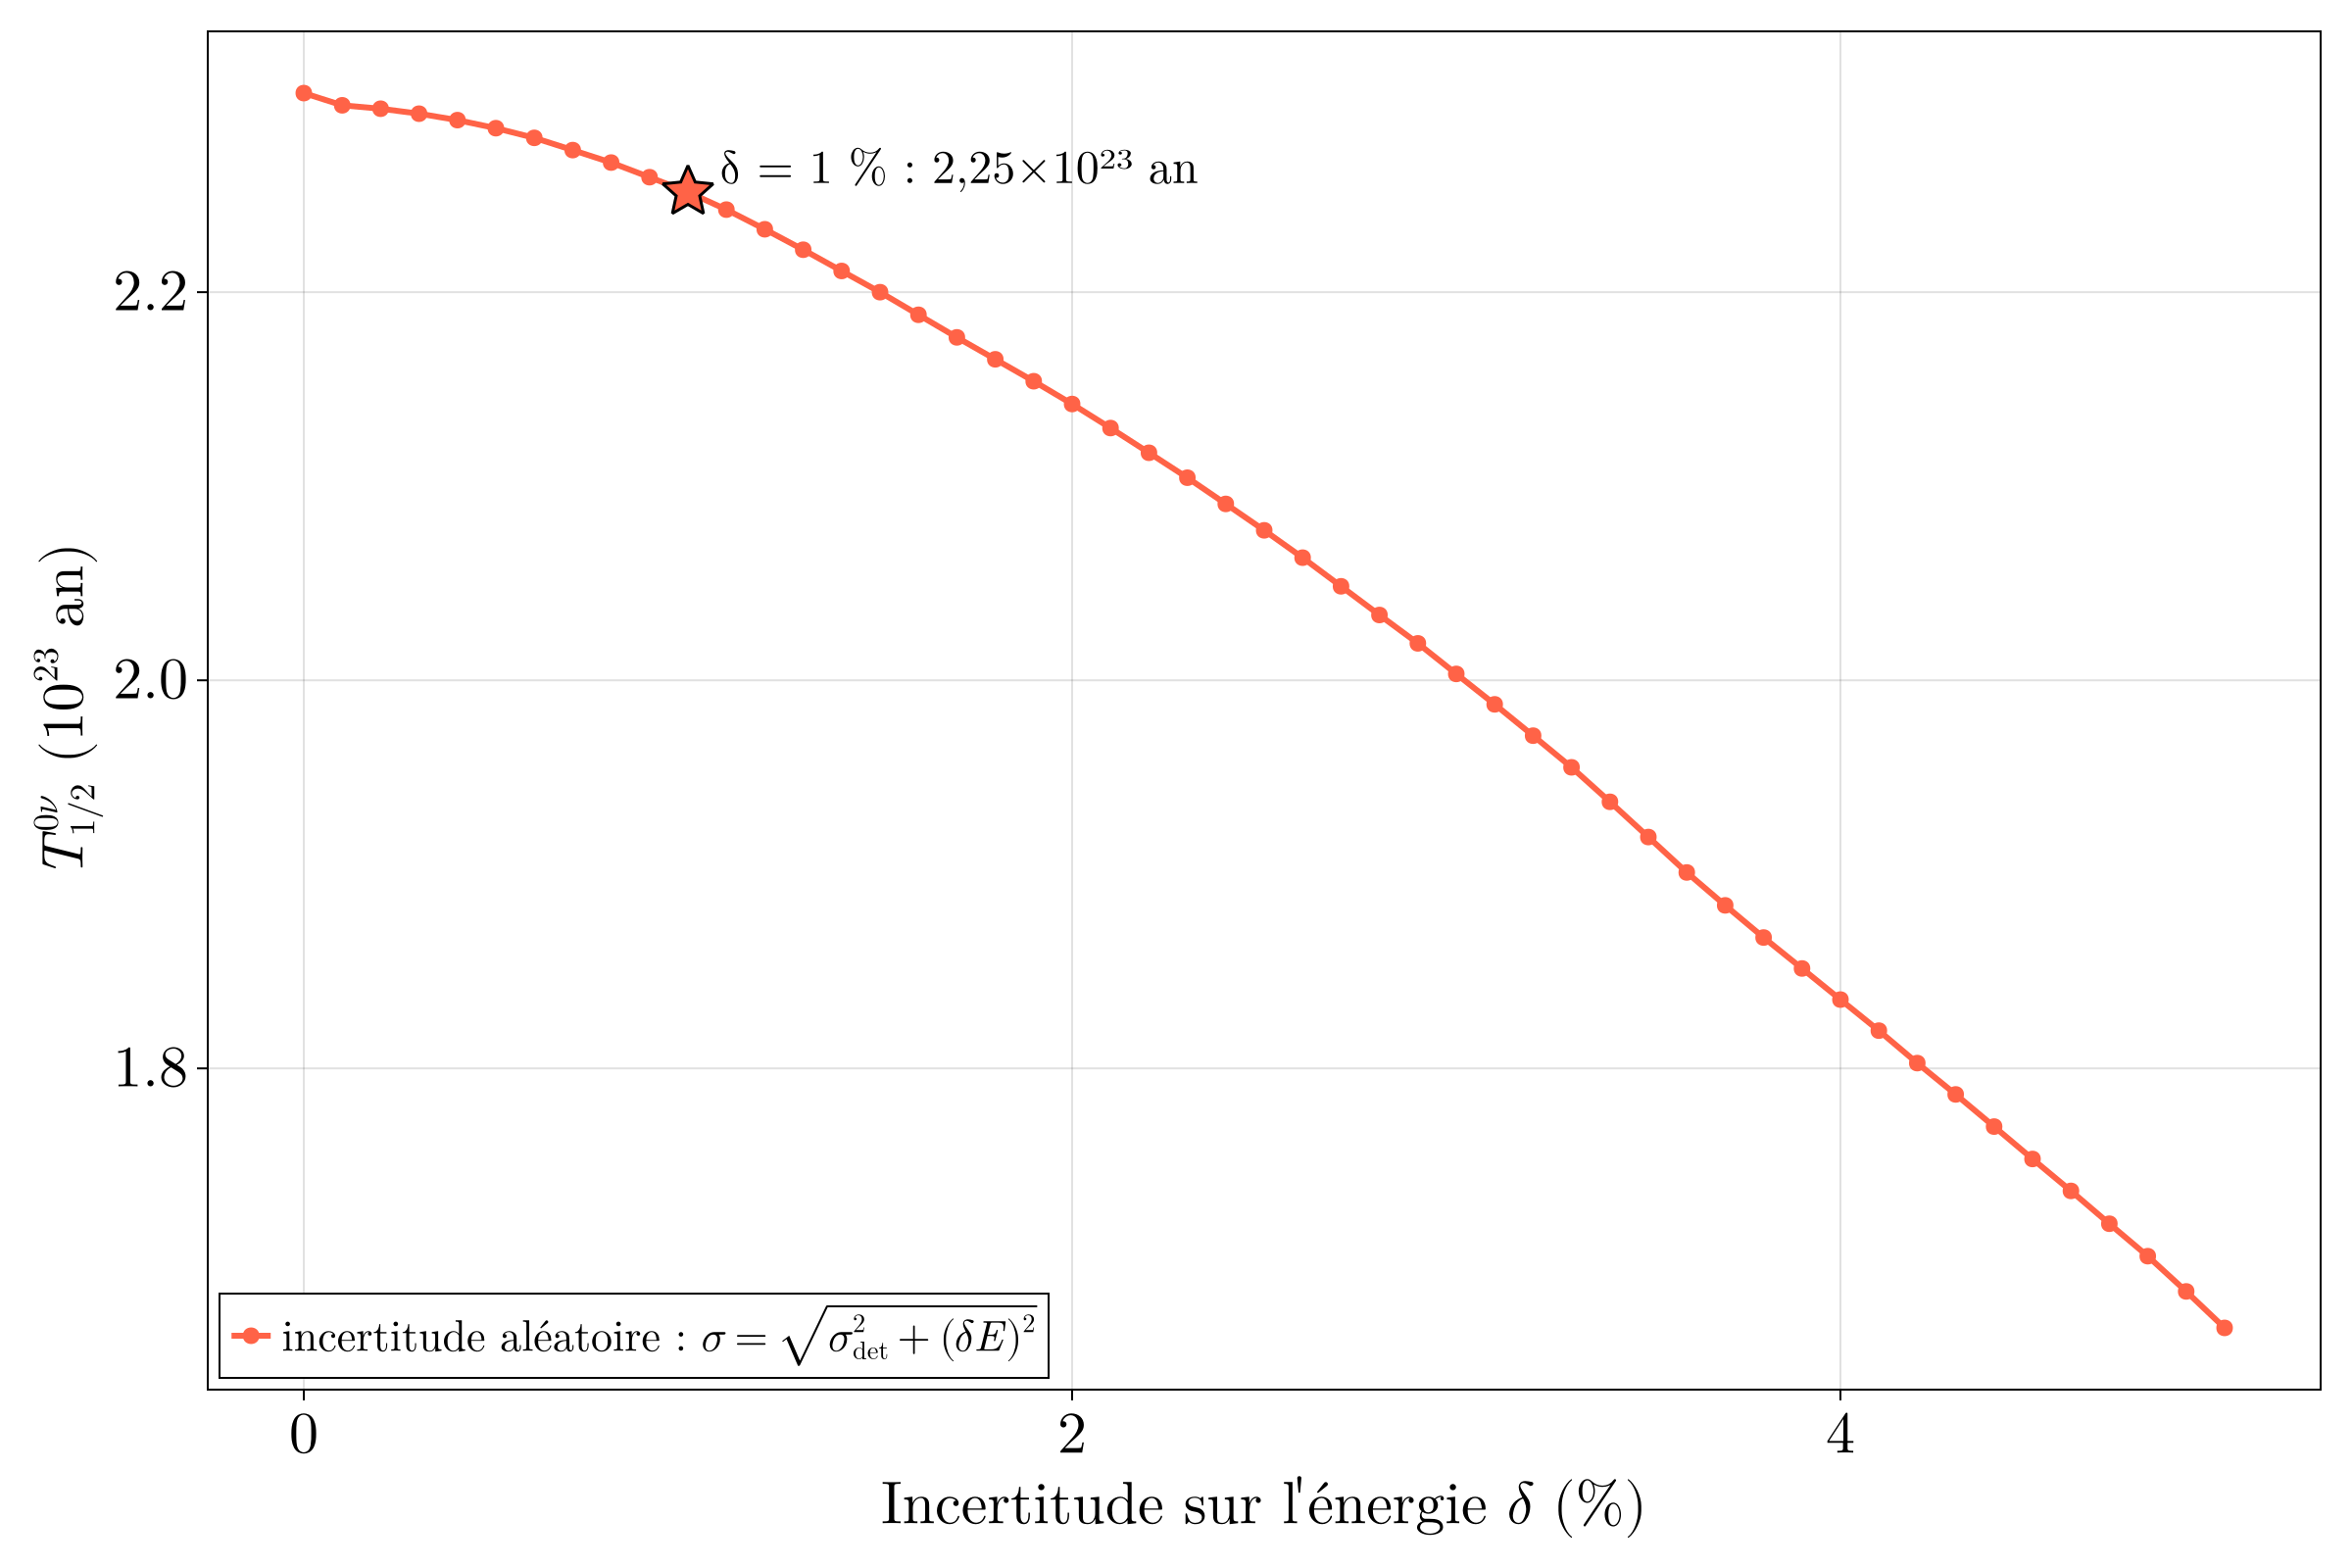

In [18]:
# =====================================================================================
# Sensibilité 0νββ en fonction de l'incertitude sur l'énergie
#   courbe principale : incertitude ALÉATOIRE δ (σ relatif) → étalement gaussien σ = δ·E ajouté en quadrature
#                       à la résolution du MC : σ_tot = √(σ_det² + (δ·E)²)
#   courbe en pointillés (optionnelle) : DÉCALAGE systématique de l'échelle E → (1+δ)·E (ancien calcul)
# ROI fixe. Les données ne changent pas, seul le MC (signal et bruits de fond) est modifié.
# À lancer après la section 5 (SETS et R en mémoire).
# =====================================================================================
D_SCAN       = collect(0.0:0.1:5.0)  # δ en %
ROI_D        = R.roi                  # ou (2.70, 3.15)
PER_ELECTRON = false                  # true : δ indépendante sur chaque électron → σ_sum ≈ δ·E/√2 (E1 ≈ E2)
SHOW_SHIFT   = false                   # superposer le décalage systématique pour comparaison

# Φ via erf (Abramowitz-Stegun 7.1.26, précision 1e-7)
function erf_as(x)
    t = 1 / (1 + 0.3275911 * abs(x))
    y = 1 - (((((1.061405429t - 1.453152027)t + 1.421413741)t - 0.284496736)t + 0.254829592)t) * exp(-x^2)
    return sign(x) * y
end
Φ(x) = 0.5 * (1 + erf_as(x / sqrt(2)))

# probabilité qu'un évènement d'énergie E tombe dans [lo ; hi[ après étalement (smear) ou décalage (shift)
p_smear(E, lo, hi, δ) = (σ = (PER_ELECTRON ? 1 / sqrt(2) : 1.0) * δ / 100 * E; Φ((hi - E) / σ) - Φ((lo - E) / σ))
p_shift(E, lo, hi, δ) = (lo <= (1 + δ / 100) * E < hi) ? 1.0 : 0.0

function sens_energy(sets, roi, δ, mode)
    lo, hi = roi; εt = 0.0; b = 0.0
    for s in sets, p in s.procs
        n = δ == 0 ? count(E -> lo <= E < hi, p.dataVector) :
            mode == :smear ? sum(E -> p_smear(E, lo, hi, δ), p.dataVector; init = 0.0) :
                             sum(E -> p_shift(E, lo, hi, δ), p.dataVector; init = 0.0)
        n /= p.nTotalSim
        p.signal ? (εt += n * s.t_s / YEAR) : (b += n * p.activity * p.amount * p.timeMeas)
    end
    return (tHalf = κ * εt / N_exclus(b), eff = εt / (sum(s.t_s for s in sets) / YEAR), bkg = b)
end

SMEAR = [merge((delta = d,), sens_energy(SETS, ROI_D, d, :smear)) for d in D_SCAN]
SHIFT = SHOW_SHIFT ? [merge((delta = d,), sens_energy(SETS, ROI_D, d, :shift)) for d in D_SCAN] : nothing
CSV.write(joinpath(OUT_DIR, "sensitivity_vs_energy_uncertainty.csv"),
          DataFrame(delta = D_SCAN, tHalf_smear = [r.tHalf for r in SMEAR], eff_smear = [r.eff for r in SMEAR], b_smear = [r.bkg for r in SMEAR],
                    tHalf_shift = SHOW_SHIFT ? [r.tHalf for r in SHIFT] : missing))
i1 = findfirst(==(1.0), D_SCAN)
println("ROI [$(ROI_D[1]) ; $(ROI_D[2])[ — δ = 0 : T½ > $(sci(SMEAR[1].tHalf)) an")
println("δ = 1 % (étalement) : T½ > $(sci(SMEAR[i1].tHalf)) an  ($(round(100 * (SMEAR[i1].tHalf / SMEAR[1].tHalf - 1), digits = 1)) %)")
SHOW_SHIFT && println("δ = 1 % (décalage)  : T½ > $(sci(SHIFT[i1].tHalf)) an  ($(round(100 * (SHIFT[i1].tHalf / SHIFT[1].tHalf - 1), digits = 1)) %)")

let
    f = with_theme(theme_latexfonts()) do
        f = Figure(size = (1200, 800), fontsize = 30)
        ax = Axis(f[1, 1], xlabel = L"\mathrm{Incertitude\ sur\ l'énergie}\ \delta\ (\%)", ylabel = L"T_{1/2}^{0\nu}\ (10^{23}\ \mathrm{an})")
        scatterlines!(ax, D_SCAN, [r.tHalf / 1e23 for r in SMEAR], color = :tomato, linewidth = 3, markersize = 12,
                      label = L"\mathrm{incertitude\ aléatoire}\ :\ \sigma = \sqrt{\sigma_{\mathrm{det}}^2 + (\delta E)^2}")
        SHOW_SHIFT && scatterlines!(ax, D_SCAN, [r.tHalf / 1e23 for r in SHIFT], color = :gray40, linestyle = :dash, linewidth = 2,
                                    markersize = 9, label = L"\mathrm{décalage\ systématique}\ :\ E \rightarrow (1+\delta)\,E")
        scatter!(ax, [1.0], [SMEAR[i1].tHalf / 1e23], color = :tomato, marker = :star5, markersize = 30, strokecolor = :black, strokewidth = 1.5)
        text!(ax, 1.0, SMEAR[i1].tHalf / 1e23, text = "  δ = 1 % : $(sci(SMEAR[i1].tHalf)) an", align = (:left, :bottom), fontsize = 24)
        axislegend(ax, position = :lb, framevisible = true, labelsize = 22)
        f
    end
    savefig(f, "sensitivity_vs_energy_uncertainty")
end

## 9. Sensibilité en fonction du temps

Axe horizontal en **dates réelles**.
* **Points** : sensibilité cumulée à la fin de chaque phase (ROI ré-optimisée à chaque fois), avec et sans la phase 0.
* **Tirets** : projection jusqu'au 31 décembre 2026 dans les conditions de la phase 4, avec le même taux d'acquisition effectif
  (jours de données / jours calendaires) que sur la période analysée.

⚠️ Les dates de fin de phase ne sont pas dans les fichiers ROOT. Par défaut, elles sont estimées en répartissant la durée d'acquisition de
chaque phase uniformément entre le 10/04/2025 et le 16/04/2026. **Remplace `PHASE_END` par les vraies dates de la frise (figure 7.1).**

In [22]:
using Dates
DATA_START = Date(2025, 4, 10); DATA_END = Date(2026, 4, 16)
PROJ_END   = Date(2026, 12, 31)
MARK_DATES = [Date(2027, 1, 1), Date(2028, 1, 1)]
PLOT_END   = Date(2028, 3, 1)
PHASE_END  = nothing          # vraies dates de fin de phase : Dict("0" => Date(...), ..., "4" => Date(2026, 4, 16))
CAL_DAYS   = Dates.value(DATA_END - DATA_START) + 1
DUTY       = (T_TOT / DAY) / CAL_DAYS
cum_live   = cumsum([LIVE_S[ph] for ph in PHASES])
phase_end(k) = PHASE_END === nothing ? DATA_START + Day(round(Int, cum_live[k] / T_TOT * CAL_DAYS) - 1) : PHASE_END[PHASES[k]]
println("Taux d'acquisition effectif : $(round(100DUTY, digits = 1)) %")

function project(sets, d::Date)
    extra = Dates.value(d - DATA_END) * DUTY * DAY
    extra <= 0 && return sensitivity_map(sets)
    last = sets[end]
    ext = (phase = "proj", t_s = extra, data = Float64[],
           procs = [DataProcess(p.dataVector, p.isotopeName, p.signal, p.activity, extra, p.nTotalSim, BINS, p.amount) for p in last.procs])
    return sensitivity_map(vcat(sets, [ext]))
end

# sensibilité cumulée à la fin de chaque phase
meas_d = [phase_end(k) for k in eachindex(PHASES)]
meas_T = [sensitivity_map(SETS[1:k]).tHalf for k in eachindex(PHASES)]
# projection mensuelle
PROJ_DATES = sort(unique(vcat([Date(y, m, 1) for y in 2026:2028 for m in 1:12 if DATA_END < Date(y, m, 1) <= PLOT_END],
                              [PROJ_END], MARK_DATES)))
proj  = [project(SETS, d) for d in PROJ_DATES]
getp(d) = proj[findfirst(==(d), PROJ_DATES)]
RP    = getp(PROJ_END); RMARK = [getp(d) for d in MARK_DATES]
RP0   = project(SETS_NO0, PROJ_END)
TIME  = Dict(:all => (pts_d = meas_d, pts_T = meas_T, proj_d = PROJ_DATES, proj_T = [r.tHalf for r in proj]),
             :no0 => (pts_d = [DATA_END], pts_T = [R0.tHalf], proj_d = [PROJ_END], proj_T = [RP0.tHalf]))
for (ph, d, T) in zip(PHASES, meas_d, meas_T); println("fin phase $ph ($d) : T½ > $(sci(T)) an"); end
for (d, r) in zip(MARK_DATES, RMARK); println("$d : T½ > $(sci(r.tHalf)) an ($(round(r.exposure, digits = 2)) kg·an)"); end

MOIS = ["janv.", "févr.", "mars", "avr.", "mai", "juin", "juil.", "août", "sept.", "oct.", "nov.", "déc."]
xday(d) = Dates.value(d - DATA_START)
let
    f = Figure(size = (1300, 750), fontsize = 26)
    ax = Axis(f[1, 1], xlabel = "Date", ylabel = "T½ 0νββ (an), 90 % CL", yscale = log10)
    vspan!(ax, xday(DATA_START), xday(DATA_END), color = (:gray, 0.08), label = "données analysées")
    # 5 phases (sensibilité cumulée)
    scatterlines!(ax, xday.(meas_d), meas_T, color = :black, markersize = 16, linewidth = 2.5, label = "données (fin de chaque phase)")
    for (ph, d, T) in zip(PHASES, meas_d, meas_T)
        text!(ax, xday(d), T, text = "P$ph", align = (:right, :bottom), offset = (-6, 6), fontsize = 18)
    end
    text!(ax, xday(DATA_END), R.tHalf, text = "  $(sci(R.tHalf; d = 1)) an", align = (:left, :top), fontsize = 20)
    # projection
    lines!(ax, xday.(vcat([DATA_END], PROJ_DATES)), vcat([R.tHalf], [r.tHalf for r in proj]),
           color = :tomato, linestyle = :dash, linewidth = 3, label = "projection (conditions de la phase 4)")
    scatter!(ax, xday.(MARK_DATES), [r.tHalf for r in RMARK], color = :tomato, marker = :diamond, markersize = 18,
             label = "projection au 1ᵉʳ janvier")
    for (d, r) in zip(MARK_DATES, RMARK)
        text!(ax, xday(d), r.tHalf, text = "$(sci(r.tHalf; d = 1)) an", align = (:center, :bottom), offset = (0, 12),
              fontsize = 20, color = :tomato)
    end
    ticks = [Date(y, m, 1) for y in 2025:2028 for m in (1, 7) if DATA_START <= Date(y, m, 1) <= PLOT_END]
    ax.xticks = (xday.(ticks), ["$(MOIS[month(t)]) $(year(t))" for t in ticks])
    tk = [2e22, 5e22, 1e23, 2e23, 3e23, 5e23]; ax.yticks = (tk, [sci(x; d = 0) for x in tk])
    xlims!(ax, 0, xday(PLOT_END))
    axislegend(ax, position = :rb, labelsize = 18)
    savefig(f, "sensitivity_vs_time")
end

Taux d'acquisition effectif : 83.5 %


LoadError: UndefVarError: `SETS` not defined

In [21]:
# =====================================================================================
# Sensibilité en fonction du temps — PHASE 4 SEULE + projection dans les mêmes conditions
# Cellule autonome : nécessite seulement SETS, sensitivity_map, sci, savefig (sections 1 à 5).
# =====================================================================================
using Dates
DATA_START = Date(2025, 4, 10); DATA_END = Date(2026, 4, 16)
MARK_DATES = [Date(2027, 1, 1), Date(2028, 1, 1)]
PLOT_END   = Date(2028, 3, 1)
P4_START   = nothing          # vraie date de début de la phase 4, ex. Date(2025, 10, 20) ; nothing = estimée

S4 = only(s for s in SETS if s.phase == "4")
if P4_START === nothing      # estimation : phases réparties au prorata du temps vivant sur la période de données
    cal = Dates.value(DATA_END - DATA_START) + 1
    tbefore = sum(s.t_s for s in SETS if s.phase != "4")
    P4_START = DATA_START + Day(round(Int, tbefore / sum(s.t_s for s in SETS) * cal))
end
CAL4  = Dates.value(DATA_END - P4_START) + 1
DUTY4 = (S4.t_s / DAY) / CAL4
println("Phase 4 : du $P4_START au $DATA_END ($CAL4 j calendaires, $(round(S4.t_s / DAY, digits = 1)) j vivants, taux $(round(100DUTY4, digits = 1)) %)")

# phase 4 avec un temps vivant t (s) : mêmes simulations et activités, durée changée
scaled4(t) = (phase = "4", t_s = t, data = Float64[],
              procs = [DataProcess(p.dataVector, p.isotopeName, p.signal, p.activity, t, p.nTotalSim, BINS, p.amount) for p in S4.procs])
live4(d) = d <= DATA_END ? Dates.value(d - P4_START + Day(1)) * DUTY4 * DAY : S4.t_s + Dates.value(d - DATA_END) * DUTY4 * DAY
sens4(d) = sensitivity_map([scaled4(live4(d))])

R4 = sensitivity_map([S4])
println("Phase 4 seule au $DATA_END : ROI $(R4.roi), b = $(round(R4.bkg, digits = 2)), T½ > $(sci(R4.tHalf)) an ($(round(R4.exposure, digits = 2)) kg·an)")

IN_D  = [d for d in [Date(y, m, 1) for y in 2025:2026 for m in 1:12] if P4_START < d < DATA_END]
IN4   = [sens4(d) for d in IN_D]
PR_D  = sort(unique(vcat([Date(y, m, 1) for y in 2026:2028 for m in 1:12 if DATA_END < Date(y, m, 1) <= PLOT_END], MARK_DATES)))
PR4   = [sens4(d) for d in PR_D]
MARK4 = [PR4[findfirst(==(d), PR_D)] for d in MARK_DATES]
for (d, r) in zip(MARK_DATES, MARK4)
    println("$d : T½ > $(sci(r.tHalf)) an ($(round(r.exposure, digits = 2)) kg·an, ROI $(r.roi))")
end

MOIS = ["janv.", "févr.", "mars", "avr.", "mai", "juin", "juil.", "août", "sept.", "oct.", "nov.", "déc."]
xd(d) = Dates.value(d - P4_START)
let
    f = Figure(size = (1300, 750), fontsize = 26)
    ax = Axis(f[1, 1], xlabel = "Date", ylabel = "T½ 0νββ (an), 90 % CL", yscale = log10)
    vspan!(ax, 0, xd(DATA_END), color = (:gray, 0.08), label = "phase 4 analysée")
    lines!(ax, xd.(vcat(IN_D, [DATA_END])), vcat([r.tHalf for r in IN4], [R4.tHalf]), color = :black, linewidth = 2.5, label = "phase 4 (données)")
    scatter!(ax, [xd(DATA_END)], [R4.tHalf], color = :black, markersize = 16)
    text!(ax, xd(DATA_END), R4.tHalf, text = "  $(sci(R4.tHalf; d = 1)) an", align = (:left, :top), fontsize = 20)
    lines!(ax, xd.(vcat([DATA_END], PR_D)), vcat([R4.tHalf], [r.tHalf for r in PR4]), color = :tomato, linestyle = :dash,
           linewidth = 3, label = "projection (conditions de la phase 4)")
    scatter!(ax, xd.(MARK_DATES), [r.tHalf for r in MARK4], color = :tomato, marker = :diamond, markersize = 18, label = "projection au 1ᵉʳ janvier")
    for (d, r) in zip(MARK_DATES, MARK4)
        text!(ax, xd(d), r.tHalf, text = "$(sci(r.tHalf; d = 1)) an", align = (:center, :bottom), offset = (0, 12), fontsize = 20, color = :tomato)
    end
    ticks = [Date(y, m, 1) for y in 2025:2028 for m in (1, 4, 7, 10) if P4_START <= Date(y, m, 1) <= PLOT_END]
    ax.xticks = (xd.(ticks), ["$(MOIS[month(t)]) $(year(t))" for t in ticks])
    tk = [1e22, 2e22, 5e22, 1e23, 2e23, 3e23, 5e23]; ax.yticks = (tk, [sci(x; d = 0) for x in tk])
    xlims!(ax, 0, xd(PLOT_END))
    axislegend(ax, position = :rb, labelsize = 18)
    savefig(f, "sensitivity_vs_time_phase4")
end

LoadError: UndefVarError: `SETS` not defined

In [16]:
# ===== Sensibilité en fonction du temps : toutes phases + phase 4 seule (radon mesuré, 1 et 0,1 mBq/m³) =====
# Cartes (E_min, E_max) calculées une seule fois par phase, puis mises à l'échelle avec le temps vivant.
# Un point par courbe à DATA_END, puis projection. Utilise les variables de la cellule précédente (section 9).
RADON_ALT = [1e-3, 0.1e-3]                      # Bq/m³

function roi_maps(s)                            # Σ ε·t [s], b radon, b autres (cartes E_min × E_max)
    et = zeros(size(bincounts(s.procs[1].efficiency))); bR = zero(et); bO = zero(et)
    for p in s.procs
        if p.signal; et .+= bincounts(p.efficiency) .* s.t_s
        elseif p.isotopeName in ("radon", "radon_surface"); bR .+= bincounts(get_bkg_counts(p))
        else; bO .+= bincounts(get_bkg_counts(p)); end
    end
    (t = s.t_s, et = et, bR = bR, bO = bO)
end
@time MAPS = Dict(zip([s.phase for s in SETS], fetch.([Threads.@spawn roi_maps(s) for s in SETS])))
best(et, b) = maximum(κ .* (et ./ YEAR) ./ N_exclus.(b))

PR_D  = sort(unique(vcat([Date(y, m, 1) for y in 2026:2028 for m in 1:12 if DATA_END < Date(y, m, 1) <= PLOT_END], MARK_DATES)))
extra(d) = Dates.value(d - DATA_END) * DUTY * DAY
m4  = MAPS["4"]; fR = [A / RADON_BQ_M3["4"] for A in RADON_ALT]
b4(f) = m4.bO .+ f .* m4.bR
etA = sum(m.et for m in values(MAPS)); bA = sum(m.bR .+ m.bO for m in values(MAPS))

function curve(et0, b0, b4f)                    # T½ à DATA_END puis aux dates de projection (threads)
    pr = zeros(length(PR_D))
    Threads.@threads for k in eachindex(PR_D)
        x = extra(PR_D[k]) / m4.t; pr[k] = best(et0 .+ m4.et .* x, b0 .+ b4f .* x)
    end
    (T0 = best(et0, b0), proj = pr)
end
CURVES = [("toutes phases", :black, :tomato, "", curve(etA, bA, b4(1.0))),
          ("phase 4 seule ($(round(1e3RADON_BQ_M3["4"], digits = 1)) mBq/m³)", :royalblue, :royalblue, "_p4", curve(m4.et, b4(1.0), b4(1.0))),
          ("phase 4 seule (1 mBq/m³)",   :seagreen,   :seagreen,   "_p4_1mBq",   curve(m4.et, b4(fR[1]), b4(fR[1]))),
          ("phase 4 seule (0,1 mBq/m³)", :darkorange, :darkorange, "_p4_0p1mBq", curve(m4.et, b4(fR[2]), b4(fR[2])))]
ix(d) = findfirst(==(d), PR_D)
for (lab, _, _, _, c) in CURVES
    println(rpad(lab, 30), " : $DATA_END → $(sci(c.T0)) an  |  ", join(["$d → $(sci(c.proj[ix(d)])) an" for d in MARK_DATES], "  |  "))
end

function time_fig(curves, name; labels = true)
    f = Figure(size = (1300, 750), fontsize = 26)
    ax = Axis(f[1, 1], xlabel = "Date", ylabel = "T½ 0νββ (an), 90 % CL", yscale = log10)
    vspan!(ax, xday(DATA_START), xday(DATA_END), color = (:gray, 0.08), label = "données analysées")
    for (lab, c0, cp, _, c) in curves
        scatter!(ax, [xday(DATA_END)], [c.T0], color = c0, markersize = 16, label = lab * " (données analysées)")
        lines!(ax, xday.(vcat([DATA_END], PR_D)), vcat([c.T0], c.proj), color = cp, linestyle = :dash, linewidth = 3, label = lab * " (projection)")
        scatter!(ax, xday.(MARK_DATES), [c.proj[ix(d)] for d in MARK_DATES], color = cp, marker = :diamond, markersize = 18)
        if labels
            text!(ax, xday(DATA_END), c.T0, text = "  $(sci(c.T0; d = 1)) an", align = (:left, :top), fontsize = 20, color = c0)
            for d in MARK_DATES
                text!(ax, xday(d), c.proj[ix(d)], text = "$(sci(c.proj[ix(d)]; d = 1)) an", align = (:center, :bottom),
                      offset = (0, 12), fontsize = 20, color = cp)
            end
        end
    end
    ticks = [Date(y, m, 1) for y in 2025:2028 for m in (1, 7) if DATA_START <= Date(y, m, 1) <= PLOT_END]
    ax.xticks = (xday.(ticks), ["$(MOIS[month(t)]) $(year(t))" for t in ticks])
    tk = [2e22, 5e22, 1e23, 2e23, 5e23, 1e24, 2e24, 5e24]; ax.yticks = (tk, [sci(x; d = 0) for x in tk])
    xlims!(ax, 0, xday(PLOT_END))
    axislegend(ax, position = length(curves) > 1 ? :lt : :rb, labelsize = length(curves) > 1 ? 15 : 18)
    savefig(f, name); display(f)
end
for C in CURVES; time_fig([C], "sensitivity_vs_time" * C[4]); end
time_fig(CURVES, "sensitivity_vs_time_compar"; labels = false)

LoadError: UndefVarError: `SETS` not defined

## 10. Contributions par zone en énergie

**Tableau 1 (thèse)** : nombre d'évènements attendus pour chaque bruit de fond, pour les 309,54 jours, dans plusieurs zones de E1+E2,
avec les données observées et la part de chaque bruit de fond dans la ROI.

**Tableau 2 (annexe)** : détail par simulation (activité, évènements attendus sur tout le spectre et dans la ROI, part dans la ROI,
nombre d'évènements **simulés** dans la ROI pour juger de la statistique Monte-Carlo).

In [19]:
# ---- tableau 1 : évènements attendus ± erreur, 3 zones + part dans la ROI ----
WIN3 = [("Spectre complet", 0.0, Inf), ("0,5 -- 3,2 MeV", 0.5, 3.2), ("ROI", R.roi[1], R.roi[2])]
G  = Dict(g => zeros(3) for g in SPEC_GROUPS)      # Σ w
G2 = Dict(g => zeros(3) for g in SPEC_GROUPS)      # Σ w²  (erreur statistique Monte-Carlo)
for s in SETS, p in s.procs
    p.signal && continue
    w = p.activity * p.amount * p.timeMeas / p.nTotalSim; g = spec_group(p.isotopeName)
    for (j, (_, lo, hi)) in enumerate(WIN3)
        n = count(x -> lo <= x < hi, p.dataVector)
        G[g][j] += n * w; G2[g][j] += n * w^2
    end
end
MCT  = sum(G[g] for g in SPEC_GROUPS); MCT2 = sum(G2[g] for g in SPEC_GROUPS)
DAT  = [sum(count(x -> lo <= x < hi, s.data) for s in SETS) for (_, lo, hi) in WIN3]

function pm(v, e)                                  # "v ± e" avec un nombre de décimales adapté à l'erreur
    v == 0 && return "--"
    d = e >= 10 ? 0 : e >= 1 ? 1 : e >= 0.1 ? 2 : 3
    return "\$" * tex_num(v; d = d) * " \\pm " * tex_num(e; d = d) * "\$"
end
pct(g) = MCT[3] > 0 && G[g][3] > 0 ? tex_num(100 * G[g][3] / MCT[3]; d = 1) : "--"

CSV.write(joinpath(OUT_DIR, "table_contributions_zones.csv"),
          DataFrame(contribution = vcat(SPEC_GROUPS, ["MC total", "Données"]),
                    total = vcat([G[g][1] for g in SPEC_GROUPS], [MCT[1], DAT[1]]),
                    err_total = vcat([sqrt(G2[g][1]) for g in SPEC_GROUPS], [sqrt(MCT2[1]), sqrt(DAT[1])]),
                    zone_05_32 = vcat([G[g][2] for g in SPEC_GROUPS], [MCT[2], DAT[2]]),
                    err_05_32 = vcat([sqrt(G2[g][2]) for g in SPEC_GROUPS], [sqrt(MCT2[2]), sqrt(DAT[2])]),
                    ROI = vcat([G[g][3] for g in SPEC_GROUPS], [MCT[3], DAT[3]]),
                    err_ROI = vcat([sqrt(G2[g][3]) for g in SPEC_GROUPS], [sqrt(MCT2[3]), sqrt(DAT[3])])))

let io = IOBuffer()
    println(io, "\\begin{tabular}{lcccc}\n\\toprule")
    println(io, "Contribution & Spectre complet & 0,5 -- 3,2 MeV & ROI \$[", tex_num(R.roi[1]), "\\,;\\,", tex_num(R.roi[2]),
            "[\$ & Part ROI (\\%) \\\\\n\\midrule")
    for g in SPEC_GROUPS
        println(io, LATEX_SPEC[g], " & ", join([pm(G[g][j], sqrt(G2[g][j])) for j in 1:3], " & "), " & ", pct(g), " \\\\")
    end
    println(io, "\\midrule\nMC total & ", join([pm(MCT[j], sqrt(MCT2[j])) for j in 1:3], " & "), " & 100 \\\\")
    println(io, "Données & ", join(["\$" * string(DAT[j]) * " \\pm " * tex_num(sqrt(DAT[j]); d = DAT[j] >= 100 ? 0 : 1) * "\$" for j in 1:3], " & "), " & \\\\")
    println(io, "\\bottomrule\n\\end{tabular}")
    write(joinpath(OUT_DIR, "table_contributions_zones.tex"), String(take!(io)))
end
print(read(joinpath(OUT_DIR, "table_contributions_zones.tex"), String))

LoadError: UndefVarError: `LATEX_SPEC` not defined

## 11. Résumé et export ROOT

`resume_resultats.txt` regroupe tous les chiffres clés : c'est le fichier à m'envoyer pour la rédaction.

In [20]:
let io = IOBuffer()
    println(io, "=== Sensibilité 0νββ SuperNEMO (activités mesurées) ===")
    println(io, "ANGLE_CUT = $ANGLE_CUT, NEUTRON_MODE = $NEUTRON_MODE, BIN_WIDTH = $BIN_WIDTH MeV, taux d'acquisition = $(round(100DUTY, digits = 1)) %")
    for (lab, r, sets) in (("Phases 0-4", R, SETS), ("Phases 1-4", R0, SETS_NO0))
        println(io, "$lab : $(round(sum(s.t_s for s in sets) / DAY, digits = 2)) j, $(round(r.exposure, digits = 3)) kg·an, ROI $(r.roi) MeV, ",
                "ε = $(round(100r.eff, digits = 2)) %, b = $(round(r.bkg, digits = 2)), N_exclus = $(round(r.Nex, digits = 2)), ",
                "observés = $(n_obs(sets, r.roi)), T½ > $(r.tHalf) an")
    end
    println(io, "Projection 31/12/2026 (phases 0-4) : $(round(RP.exposure, digits = 3)) kg·an, ROI $(RP.roi), b = $(round(RP.bkg, digits = 2)), T½ > $(RP.tHalf) an")
    println(io, "Projection 31/12/2026 (phases 1-4) : $(round(RP0.exposure, digits = 3)) kg·an, ROI $(RP0.roi), b = $(round(RP0.bkg, digits = 2)), T½ > $(RP0.tHalf) an")
    println(io, "\nContributions par zone (évènements attendus, 309,54 j) :")
    show(io, df1; allrows = true, allcols = true); println(io)
    println(io, "\nDétail par simulation :"); show(io, df2; allrows = true, allcols = true); println(io)
    println(io, "\nErreur d'échelle en énergie (ROI fixe) :"); show(io, DataFrame(ESCALE); allrows = true); println(io)
    write(joinpath(OUT_DIR, "resume_resultats.txt"), String(take!(io)))
end
print(read(joinpath(OUT_DIR, "resume_resultats.txt"), String))

LoadError: UndefVarError: `df1` not defined

In [21]:
TXT_TO_ROOT_C = "#include <fstream>
#include <string>
#include \"TFile.h\"
#include \"TH1D.h\"
#include \"TH2D.h\"
#include \"TGraph.h\"
void txt_to_root(const char* in, const char* out) {
  std::ifstream f(in); TFile fo(out, \"RECREATE\"); std::string type, name;
  while (f >> type >> name) {
    if (type == \"TH1D\") { int n; double a, b; f >> n >> a >> b; TH1D h(name.c_str(), \"\", n, a, b);
      for (int i = 1; i <= n; ++i) { double v; f >> v; h.SetBinContent(i, v); } h.Write(); }
    else if (type == \"TH2D\") { int nx, ny; double xa, xb, ya, yb; f >> nx >> xa >> xb >> ny >> ya >> yb;
      TH2D h(name.c_str(), \"\", nx, xa, xb, ny, ya, yb);
      for (int j = 1; j <= ny; ++j) for (int i = 1; i <= nx; ++i) { double v; f >> v; h.SetBinContent(i, j, v); } h.Write(); }
    else if (type == \"TGraph\") { int n; f >> n; TGraph g(n);
      for (int i = 0; i < n; ++i) { double x; f >> x; g.SetPointX(i, x); }
      for (int i = 0; i < n; ++i) { double y; f >> y; g.SetPointY(i, y); } g.SetName(name.c_str()); g.Write(); }
  }
  fo.Close();
}
"
let io = IOBuffer()
    M = bincounts(R.tmap)
    println(io, "TH2D tHalf_map $(size(M, 1)) $(first(BINS)) $(last(BINS)) $(size(M, 2)) $(first(BINS)) $(last(BINS))\n", join(string.(vec(M)), " "))
    edges, g, d, sig = combined_spectrum(SETS; tHalf = R.tHalf)
    for k in SPEC_GROUPS
        println(io, "TH1D spec_", replace(k, r"[^A-Za-z0-9]" => ""), " $(length(g[k])) 0 5\n", join(string.(g[k]), " "))
    end
    println(io, "TH1D spec_signal $(length(sig)) 0 5\n", join(string.(sig), " "))
    println(io, "TH1D spec_data $(length(d)) 0 5\n", join(string.(d), " "))
    X = [r.x for r in ESCALE]
    println(io, "TGraph tHalf_vs_energy_scale $(length(X))\n", join(string.(X), " "), "\n", join(string.([r.tHalf for r in ESCALE]), " "))
    for key in (:all, :no0)
        t = TIME[key]; xs = vcat(xday.(t.pts_d), xday.(t.proj_d)); ys = vcat(t.pts_T, t.proj_T)
        println(io, "TGraph tHalf_vs_days_since_20250410_$(key) $(length(xs))\n", join(string.(xs), " "), "\n", join(string.(ys), " "))
    end
    txt = joinpath(OUT_DIR, "sensitivity_results.txt"); out = joinpath(OUT_DIR, "sensitivity_results.root")
    mac = joinpath(OUT_DIR, "txt_to_root.C")
    write(txt, String(take!(io))); write(mac, TXT_TO_ROOT_C)
    cmd = `bash -lc "module load root 2>/dev/null; root -l -b -q '$(mac)(\"$(txt)\",\"$(out)\")'"`
    try run(cmd); println("→ ", out) catch; @warn "ROOT introuvable. Dans un terminal : module load root ; $(cmd)" end
end

LoadError: UndefVarError: `combined_spectrum` not defined

Évènements relus depuis /sps/nemo/scratch/granjon/sensitivity_from_Maros_training/SN_Sensitivity_training/data/out/ex8/SETS_FLAGS_v2.jls (neutrons chargés en mode fit_ref)
Neutrons : poids × 1.54, 1.54, 1.54, 1.54, 1.54 (phases 0, 1, 2, 3, 4), K = 0.5214893925325885
Contrôle (cercle 100 mm, toutes coupures, ROI ré-optimisée) : ROI (2.7, 3.05), b = 21.59, T½ > 2,3×10²³ an  (attendu 2,16×10²³)

=== aucune autre coupure ===
P0             max |Δy| < 175 mm : T½ > 3,86×10²¹ (b = 2305.9)   max |Δz| < 200 mm : T½ > 3,85×10²¹ (b = 2321.94)   2D : |Δy| < 185, |Δz| < 200 mm : T½ > 3,86×10²¹   réf. cercle : 3,77×10²¹ (b = 2228.07)
P1             max |Δy| < 160 mm : T½ > 3,18×10²¹ (b = 1602.92)   max |Δz| < 200 mm : T½ > 3,17×10²¹ (b = 1618.42)   2D : |Δy| < 175, |Δz| < 200 mm : T½ > 3,18×10²¹   réf. cercle : 3,11×10²¹ (b = 1541.13)
P2             max |Δy| < 175 mm : T½ > 2,68×10²¹ (b = 1133.7)   max |Δz| < 200 mm : T½ > 2,68×10²¹ (b = 1140.65)   2D : |Δy| < 190, |Δz| < 200 mm : T½ > 2,68×10²¹   

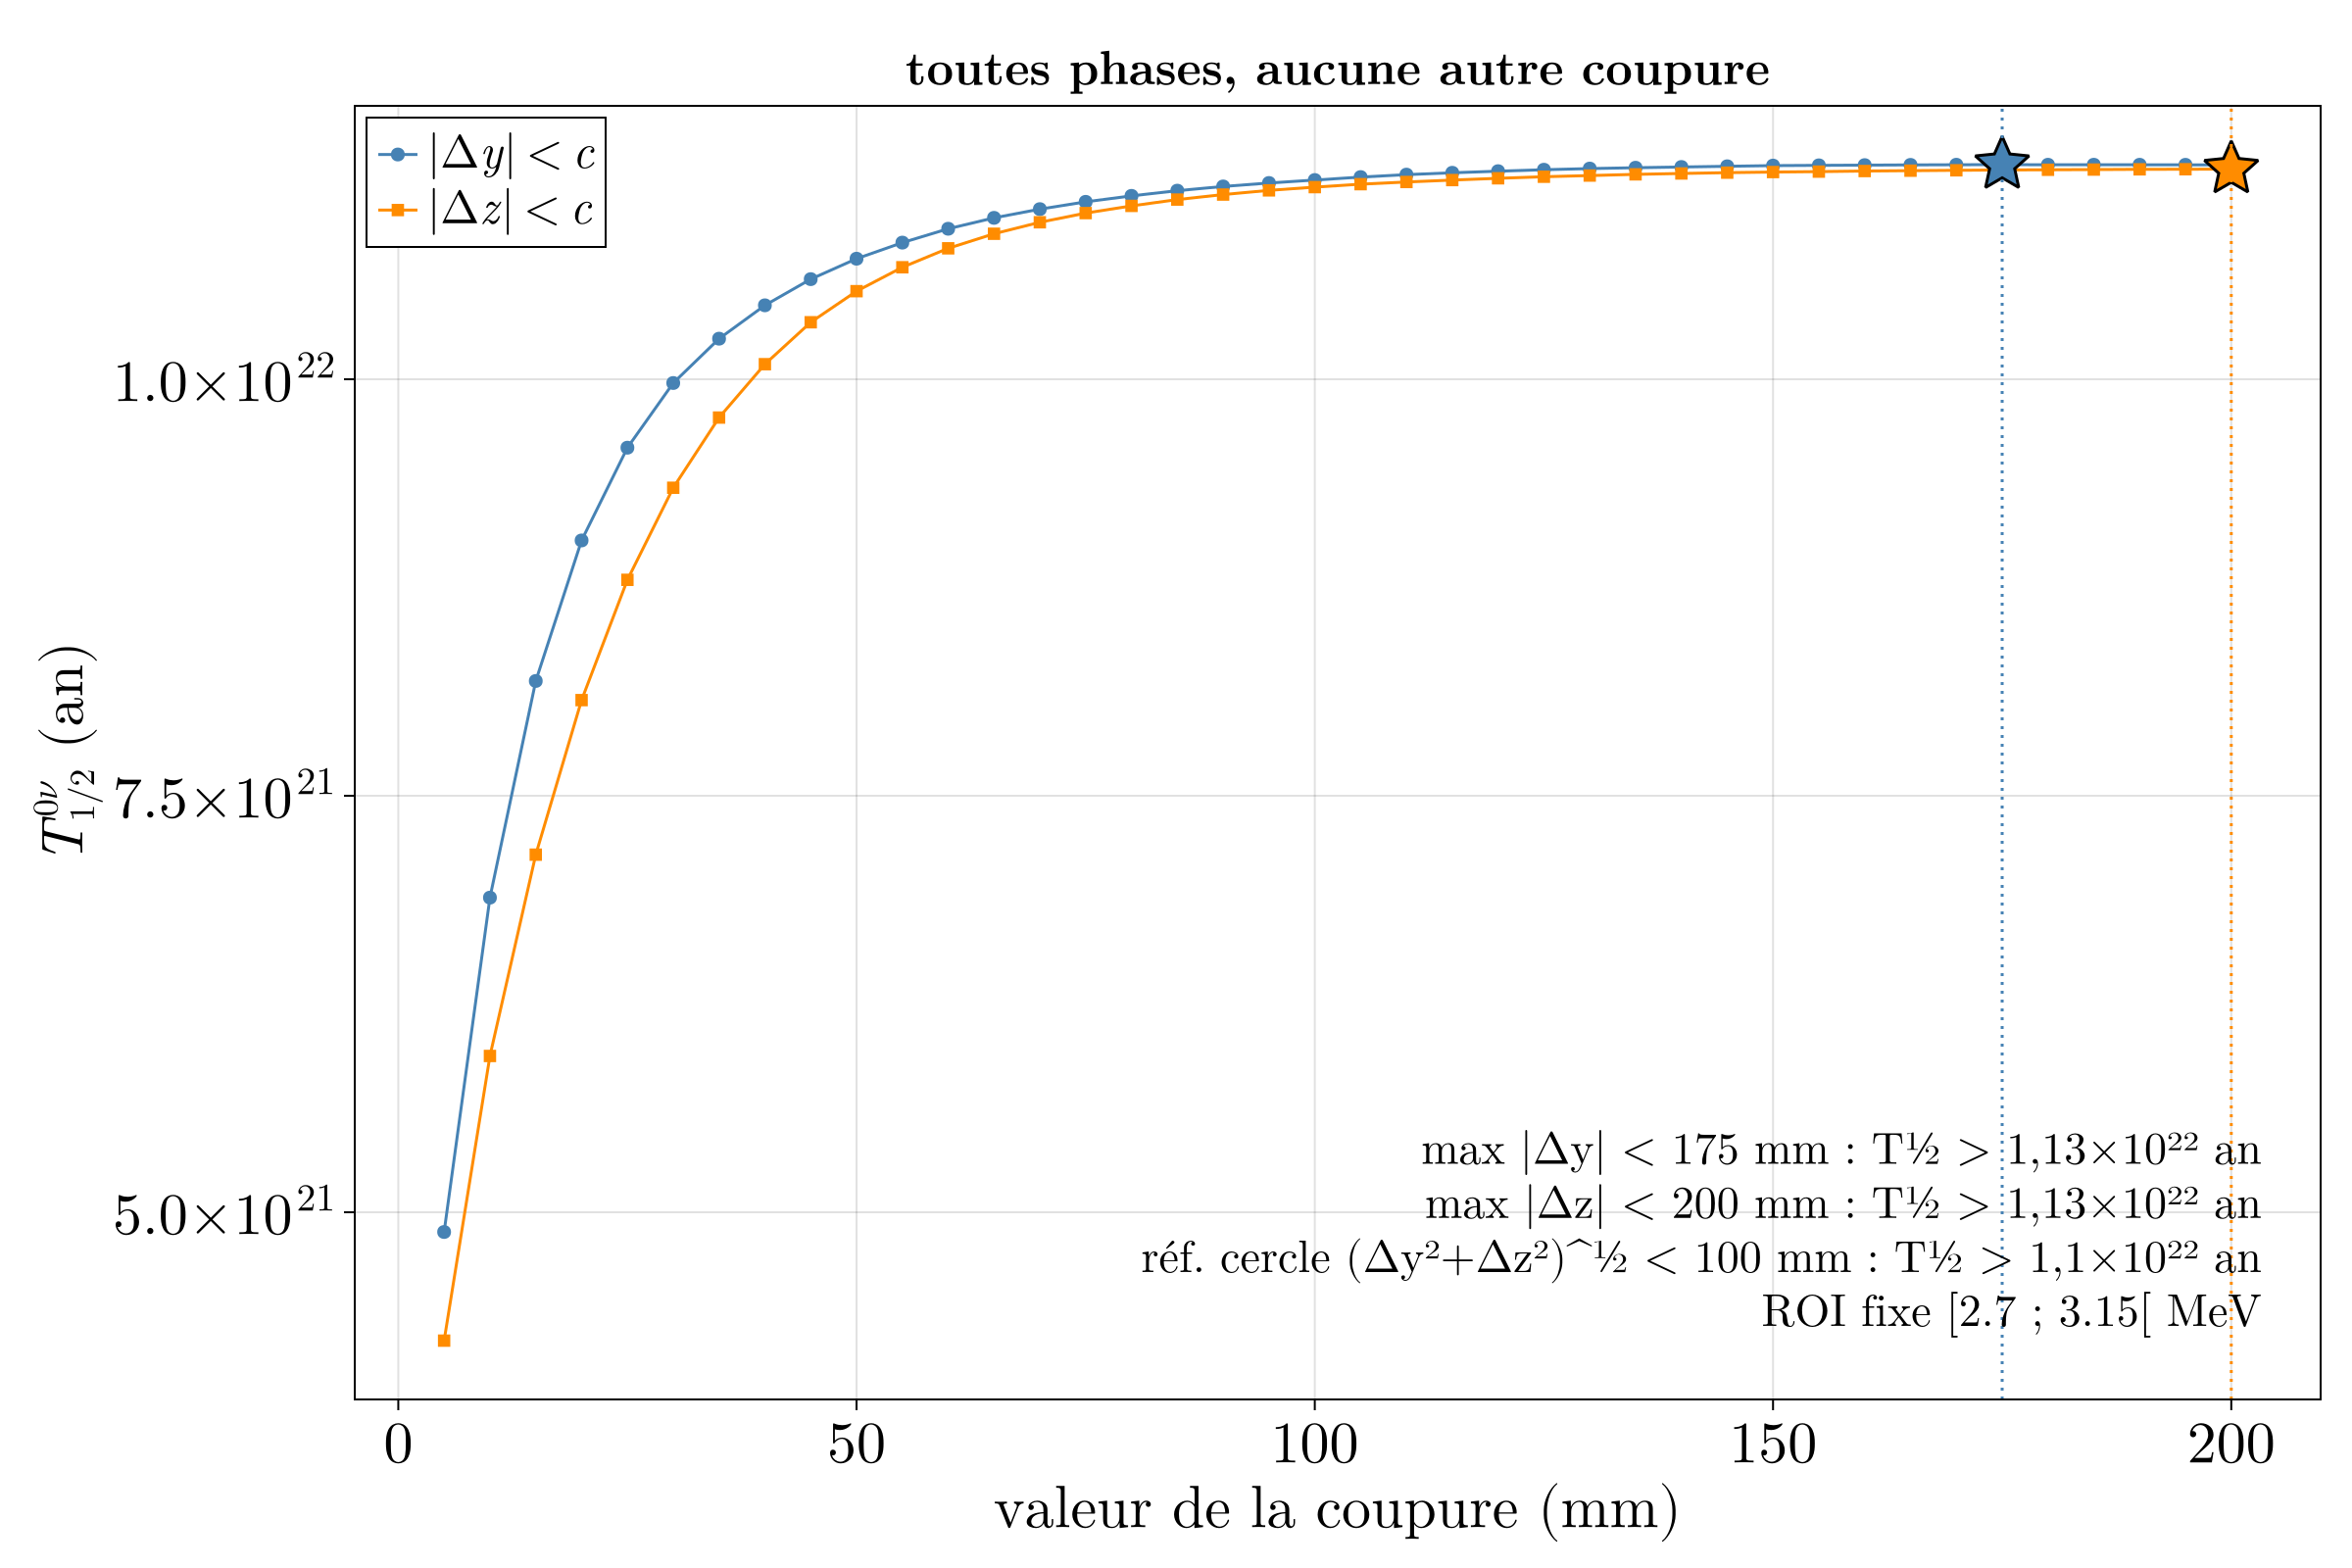

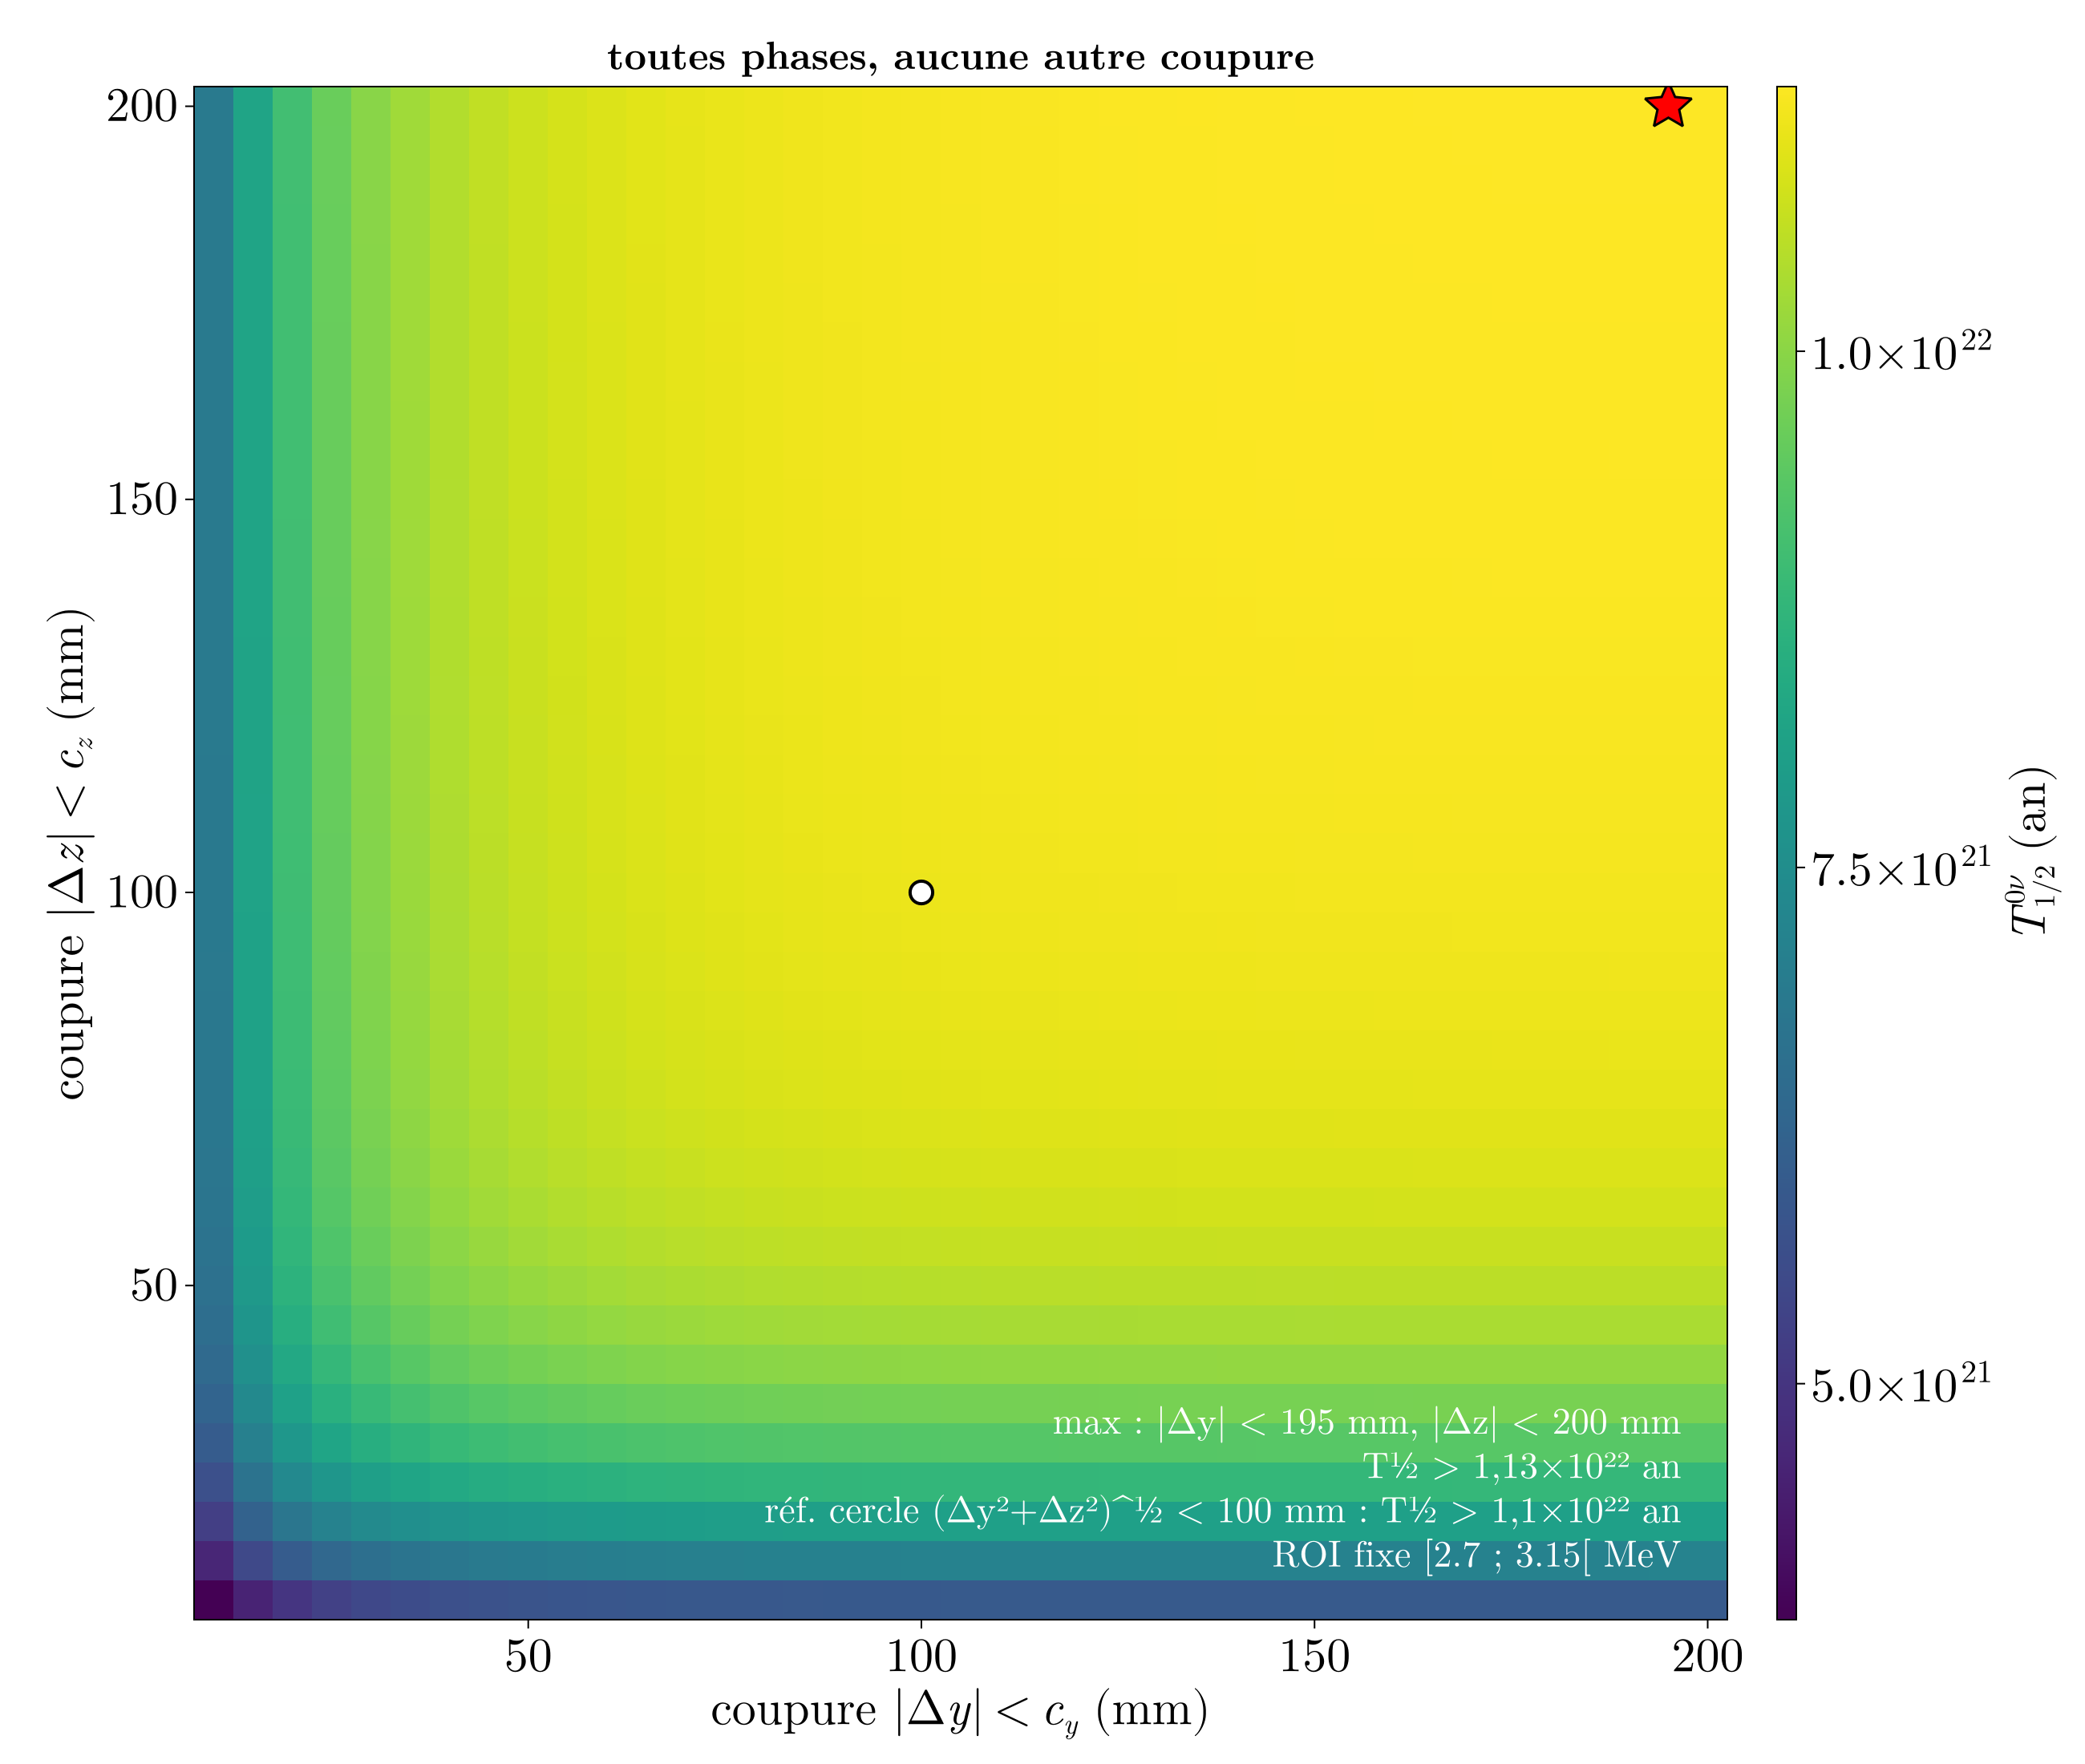

toutes phases  max |Δy| < 175 mm : T½ > 1,13×10²² (b = 19275.12)   max |Δz| < 200 mm : T½ > 1,13×10²² (b = 19391.42)   2D : |Δy| < 195, |Δz| < 200 mm : T½ > 1,13×10²²   réf. cercle : 1,1×10²² (b = 18577.75)

=== coupure temporelle seule ===
P0             max |Δy| <  35 mm : T½ > 1,85×10²² (b = 67.42)   max |Δz| <  60 mm : T½ > 1,71×10²² (b = 95.1)   2D : |Δy| < 45, |Δz| < 85 mm : T½ > 1,88×10²²   réf. cercle : 1,81×10²² (b = 89.36)
P1             max |Δy| <  45 mm : T½ > 1,48×10²² (b = 53.62)   max |Δz| <  60 mm : T½ > 1,38×10²² (b = 67.08)   2D : |Δy| < 45, |Δz| < 80 mm : T½ > 1,5×10²²   réf. cercle : 1,46×10²² (b = 63.07)
P2             max |Δy| <  40 mm : T½ > 1,31×10²² (b = 31.02)   max |Δz| <  55 mm : T½ > 1,21×10²² (b = 40.33)   2D : |Δy| < 45, |Δz| < 100 mm : T½ > 1,32×10²²   réf. cercle : 1,28×10²² (b = 38.91)
P3             max |Δy| <  45 mm : T½ > 3,29×10²² (b = 169.66)   max |Δz| <  60 mm : T½ > 3,02×10²² (b = 216.91)   2D : |Δy| < 40, |Δz| < 95 mm : T½ > 3,32×10²²   réf. c

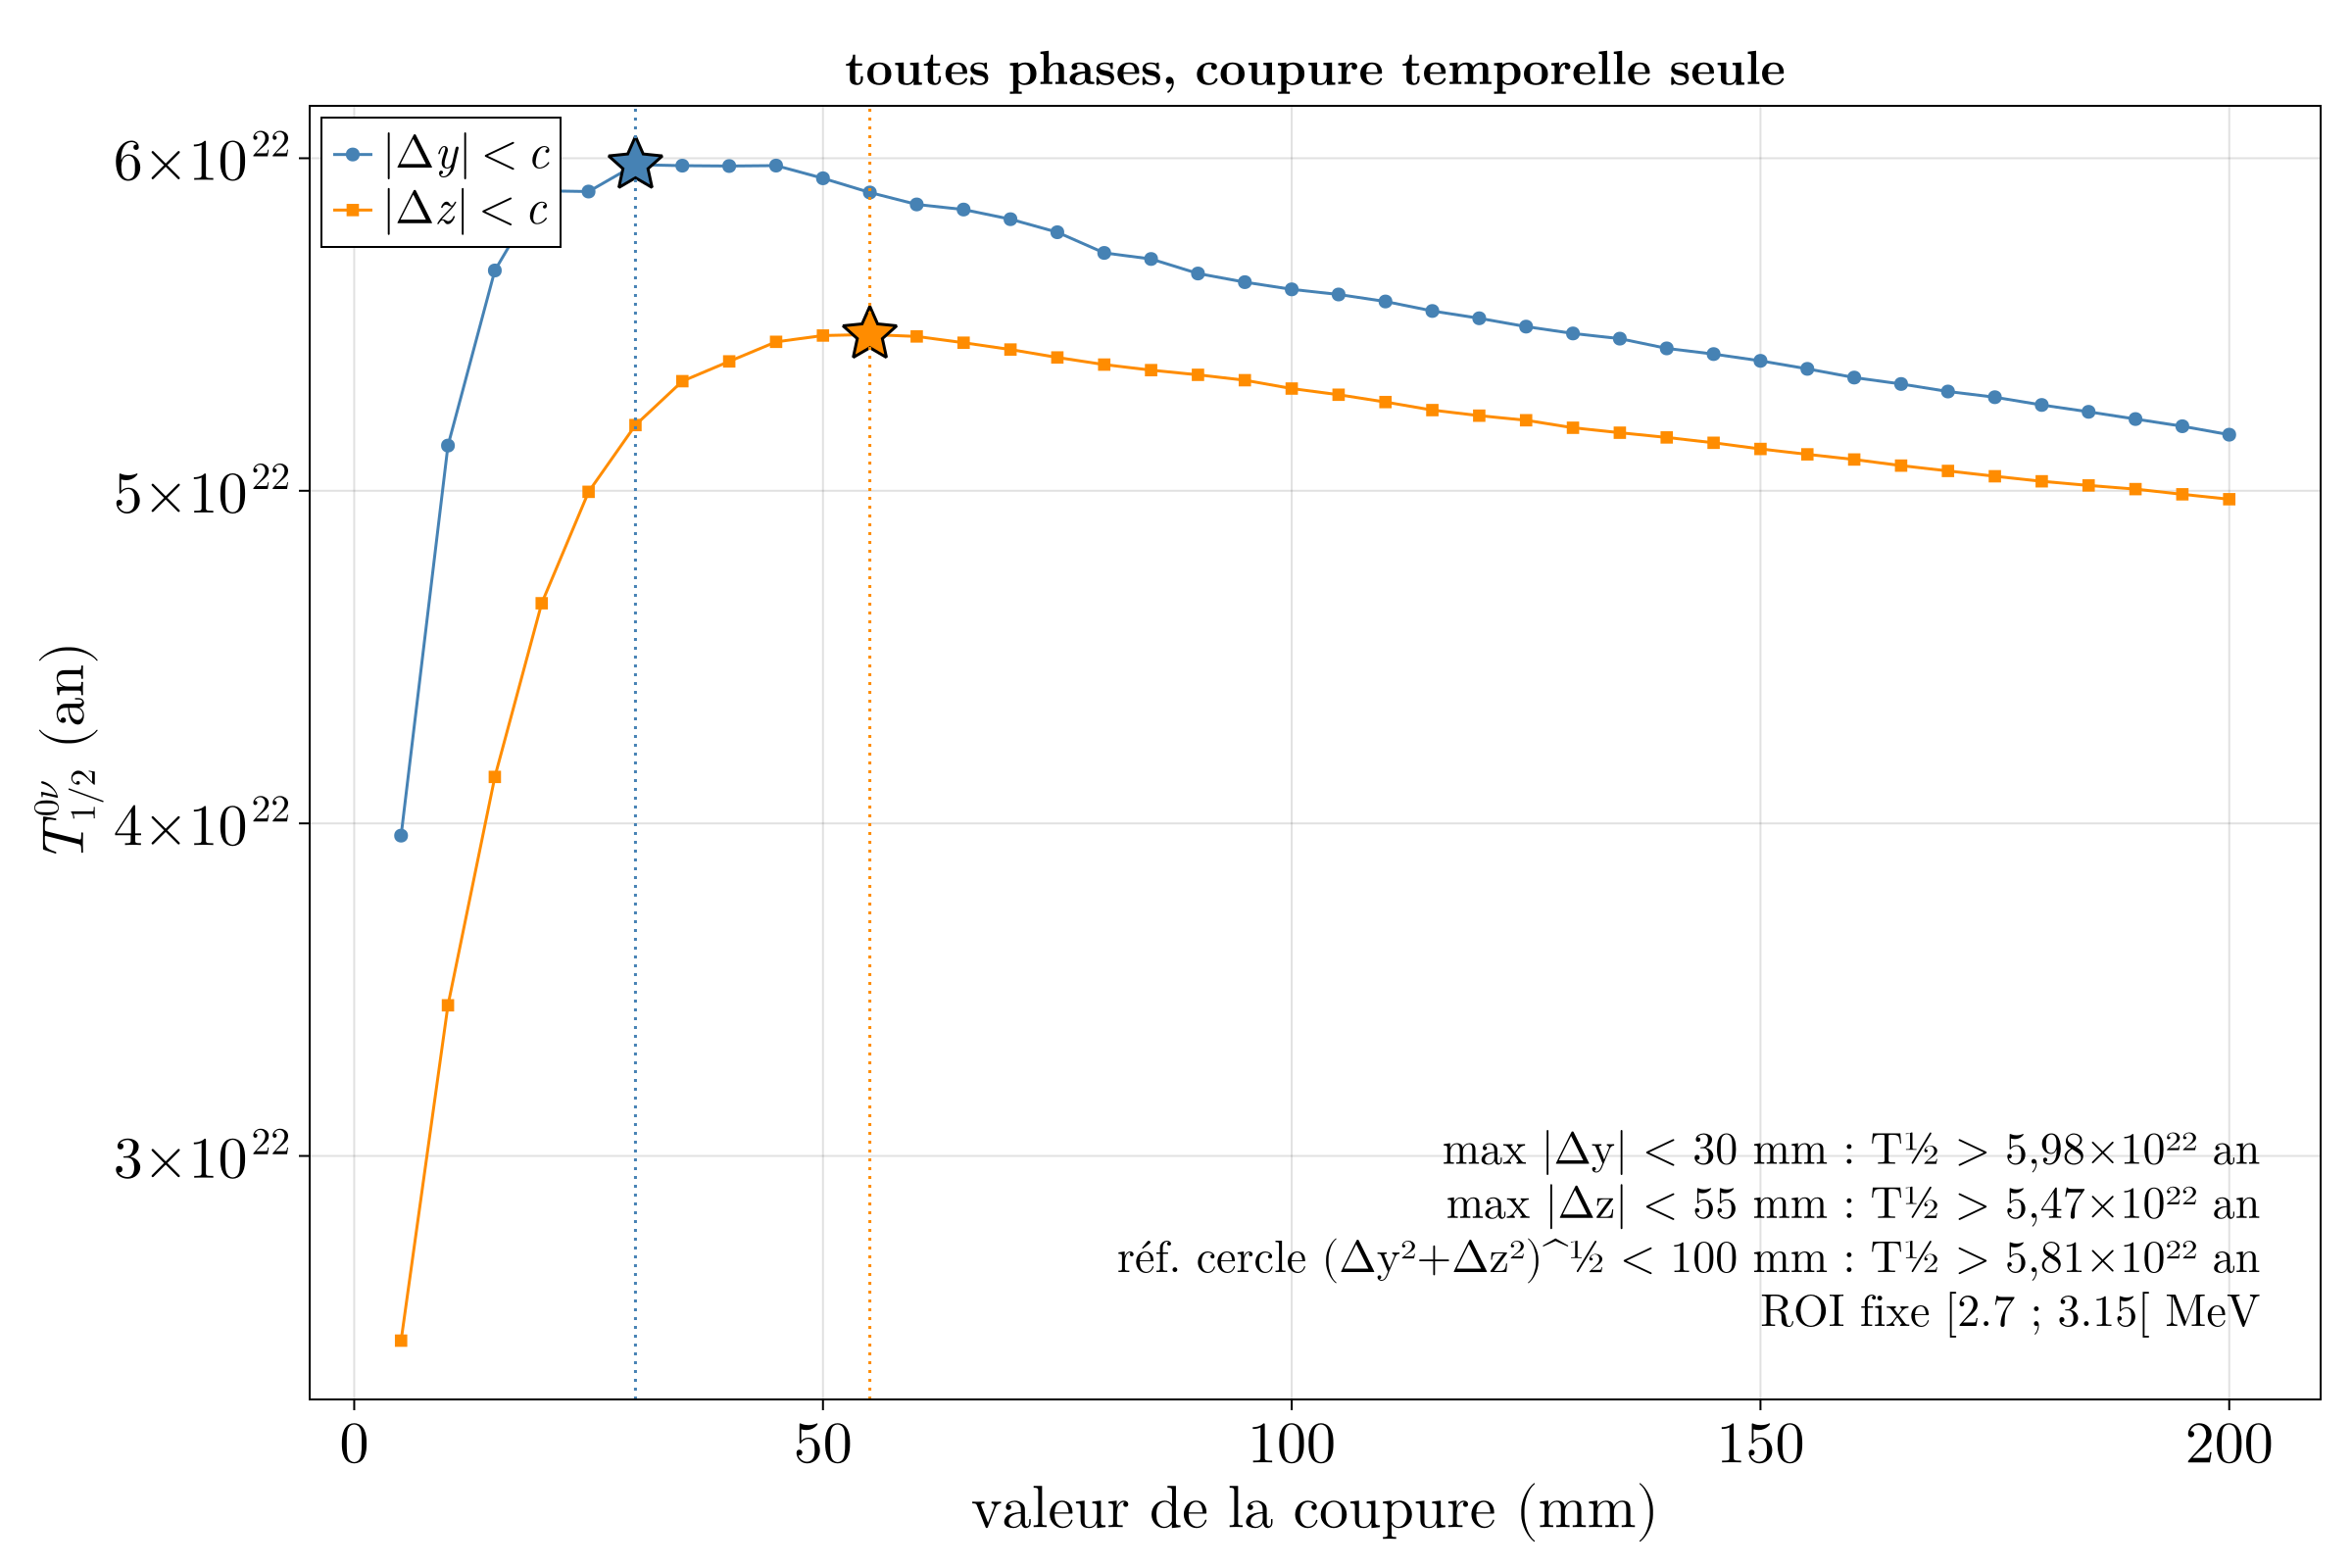

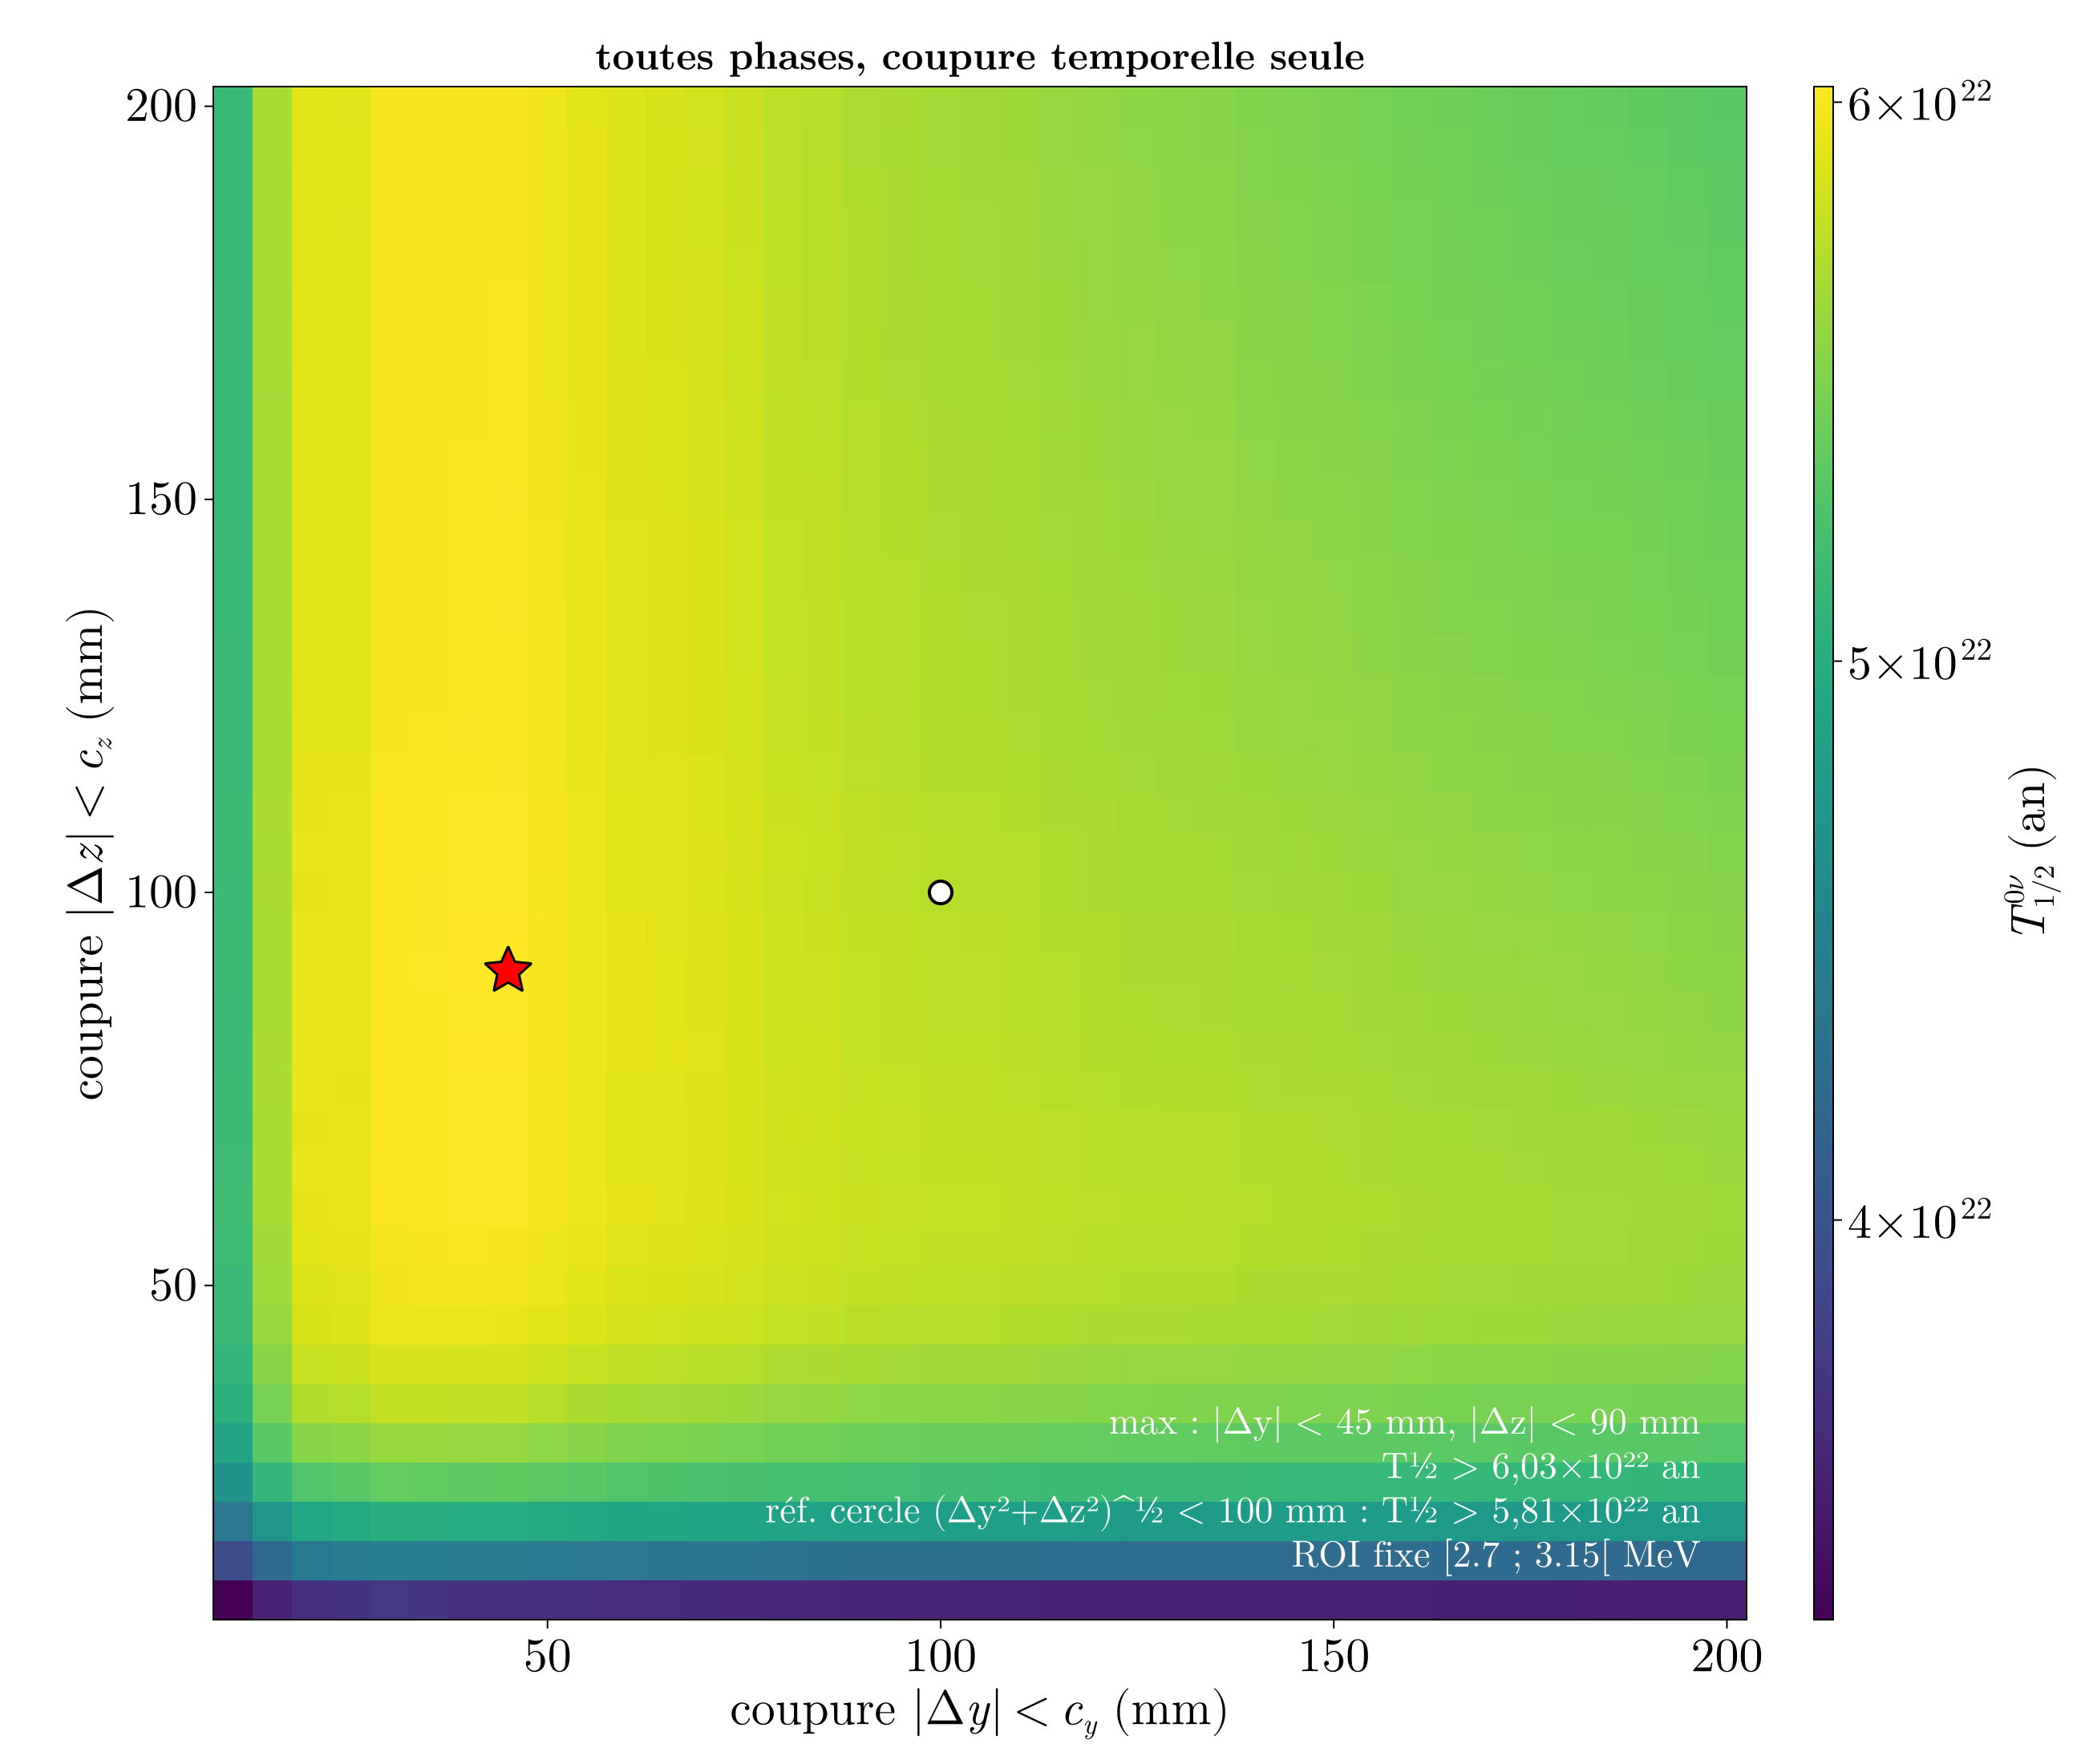

toutes phases  max |Δy| <  30 mm : T½ > 5,98×10²² (b = 455.49)   max |Δz| <  55 mm : T½ > 5,47×10²² (b = 679.63)   2D : |Δy| < 45, |Δz| < 90 mm : T½ > 6,03×10²²   réf. cercle : 5,81×10²² (b = 659.75)

=== toutes les coupures ===
P0             max |Δy| <  30 mm : T½ > 5,11×10²² (b = 3.62)   max |Δz| <  55 mm : T½ > 5,08×10²² (b = 5.0)   2D : |Δy| < 65, |Δz| < 55 mm : T½ > 5,33×10²²   réf. cercle : 5,07×10²² (b = 5.67)
P1             max |Δy| <  50 mm : T½ > 3,77×10²² (b = 3.19)   max |Δz| <  55 mm : T½ > 3,78×10²² (b = 3.04)   2D : |Δy| < 60, |Δz| < 60 mm : T½ > 3,94×10²²   réf. cercle : 3,77×10²² (b = 3.57)
P2             max |Δy| <  50 mm : T½ > 3,26×10²² (b = 1.61)   max |Δz| <  70 mm : T½ > 3,14×10²² (b = 1.99)   2D : |Δy| < 60, |Δz| < 115 mm : T½ > 3,28×10²²   réf. cercle : 3,22×10²² (b = 1.88)
P3             max |Δy| <  35 mm : T½ > 1,06×10²³ (b = 6.4)   max |Δz| <  60 mm : T½ > 1,05×10²³ (b = 8.09)   2D : |Δy| < 35, |Δz| < 65 mm : T½ > 1,11×10²³   réf. cercle : 1,05×10²³ (b = 8.

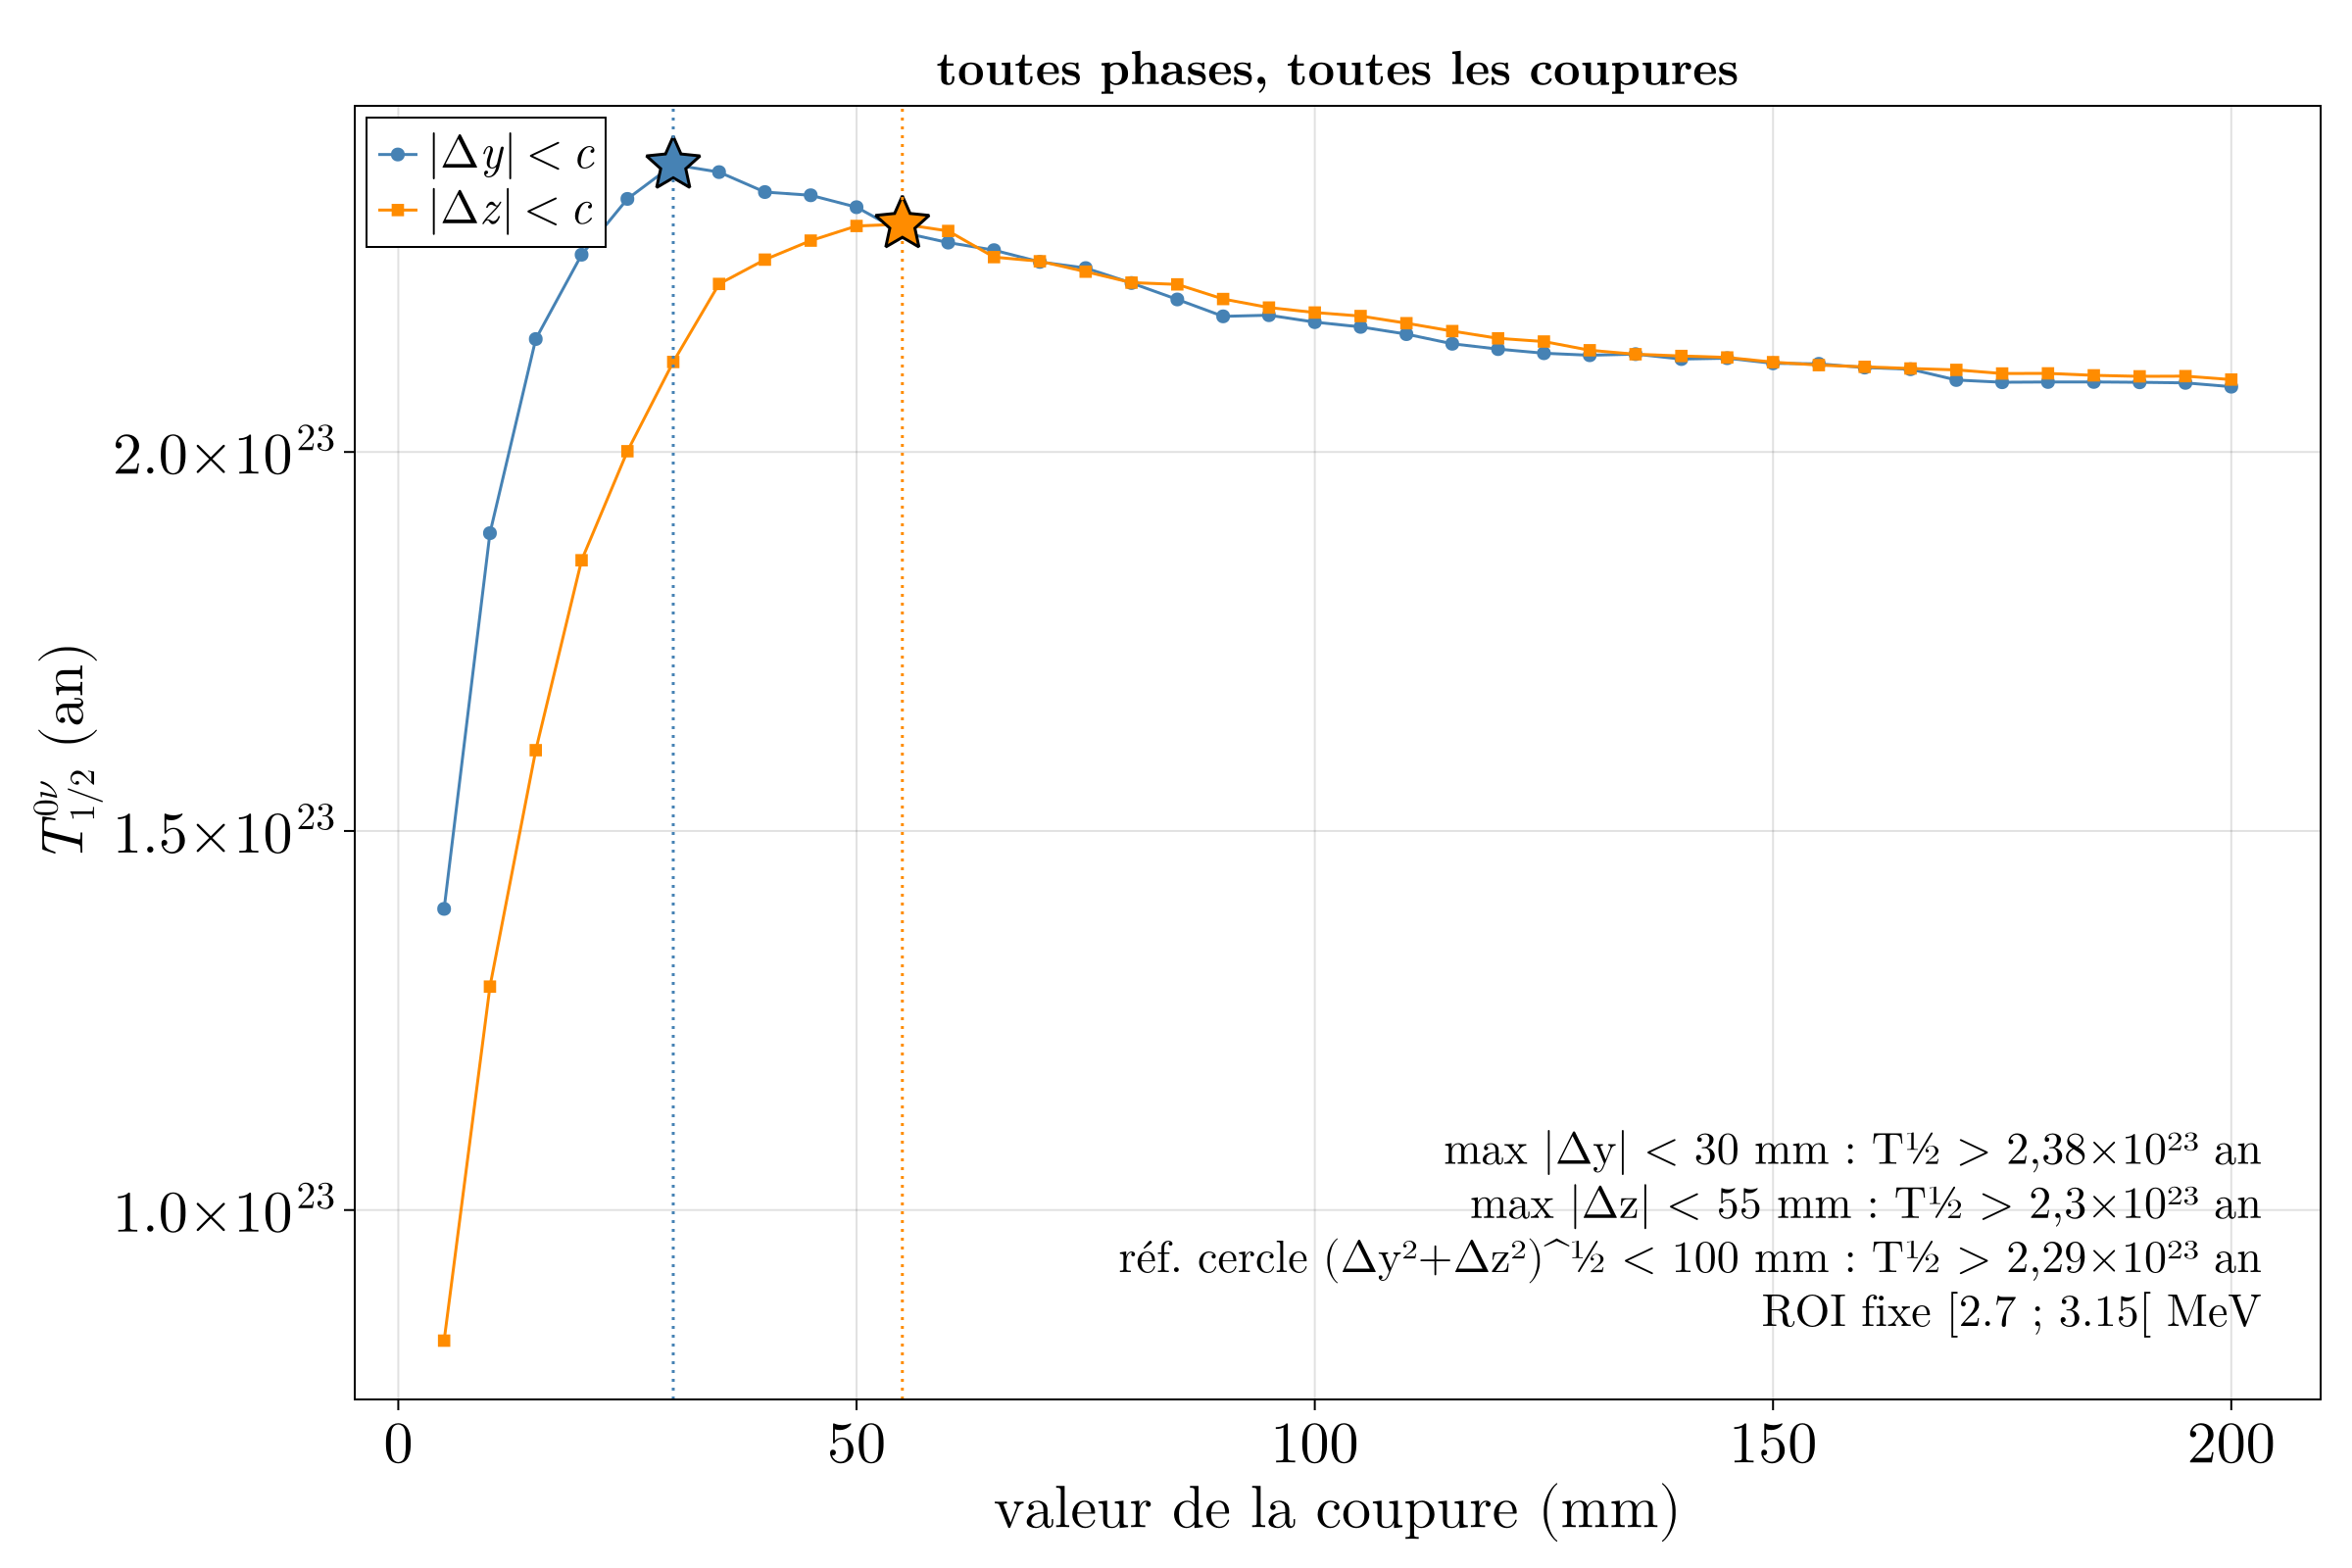

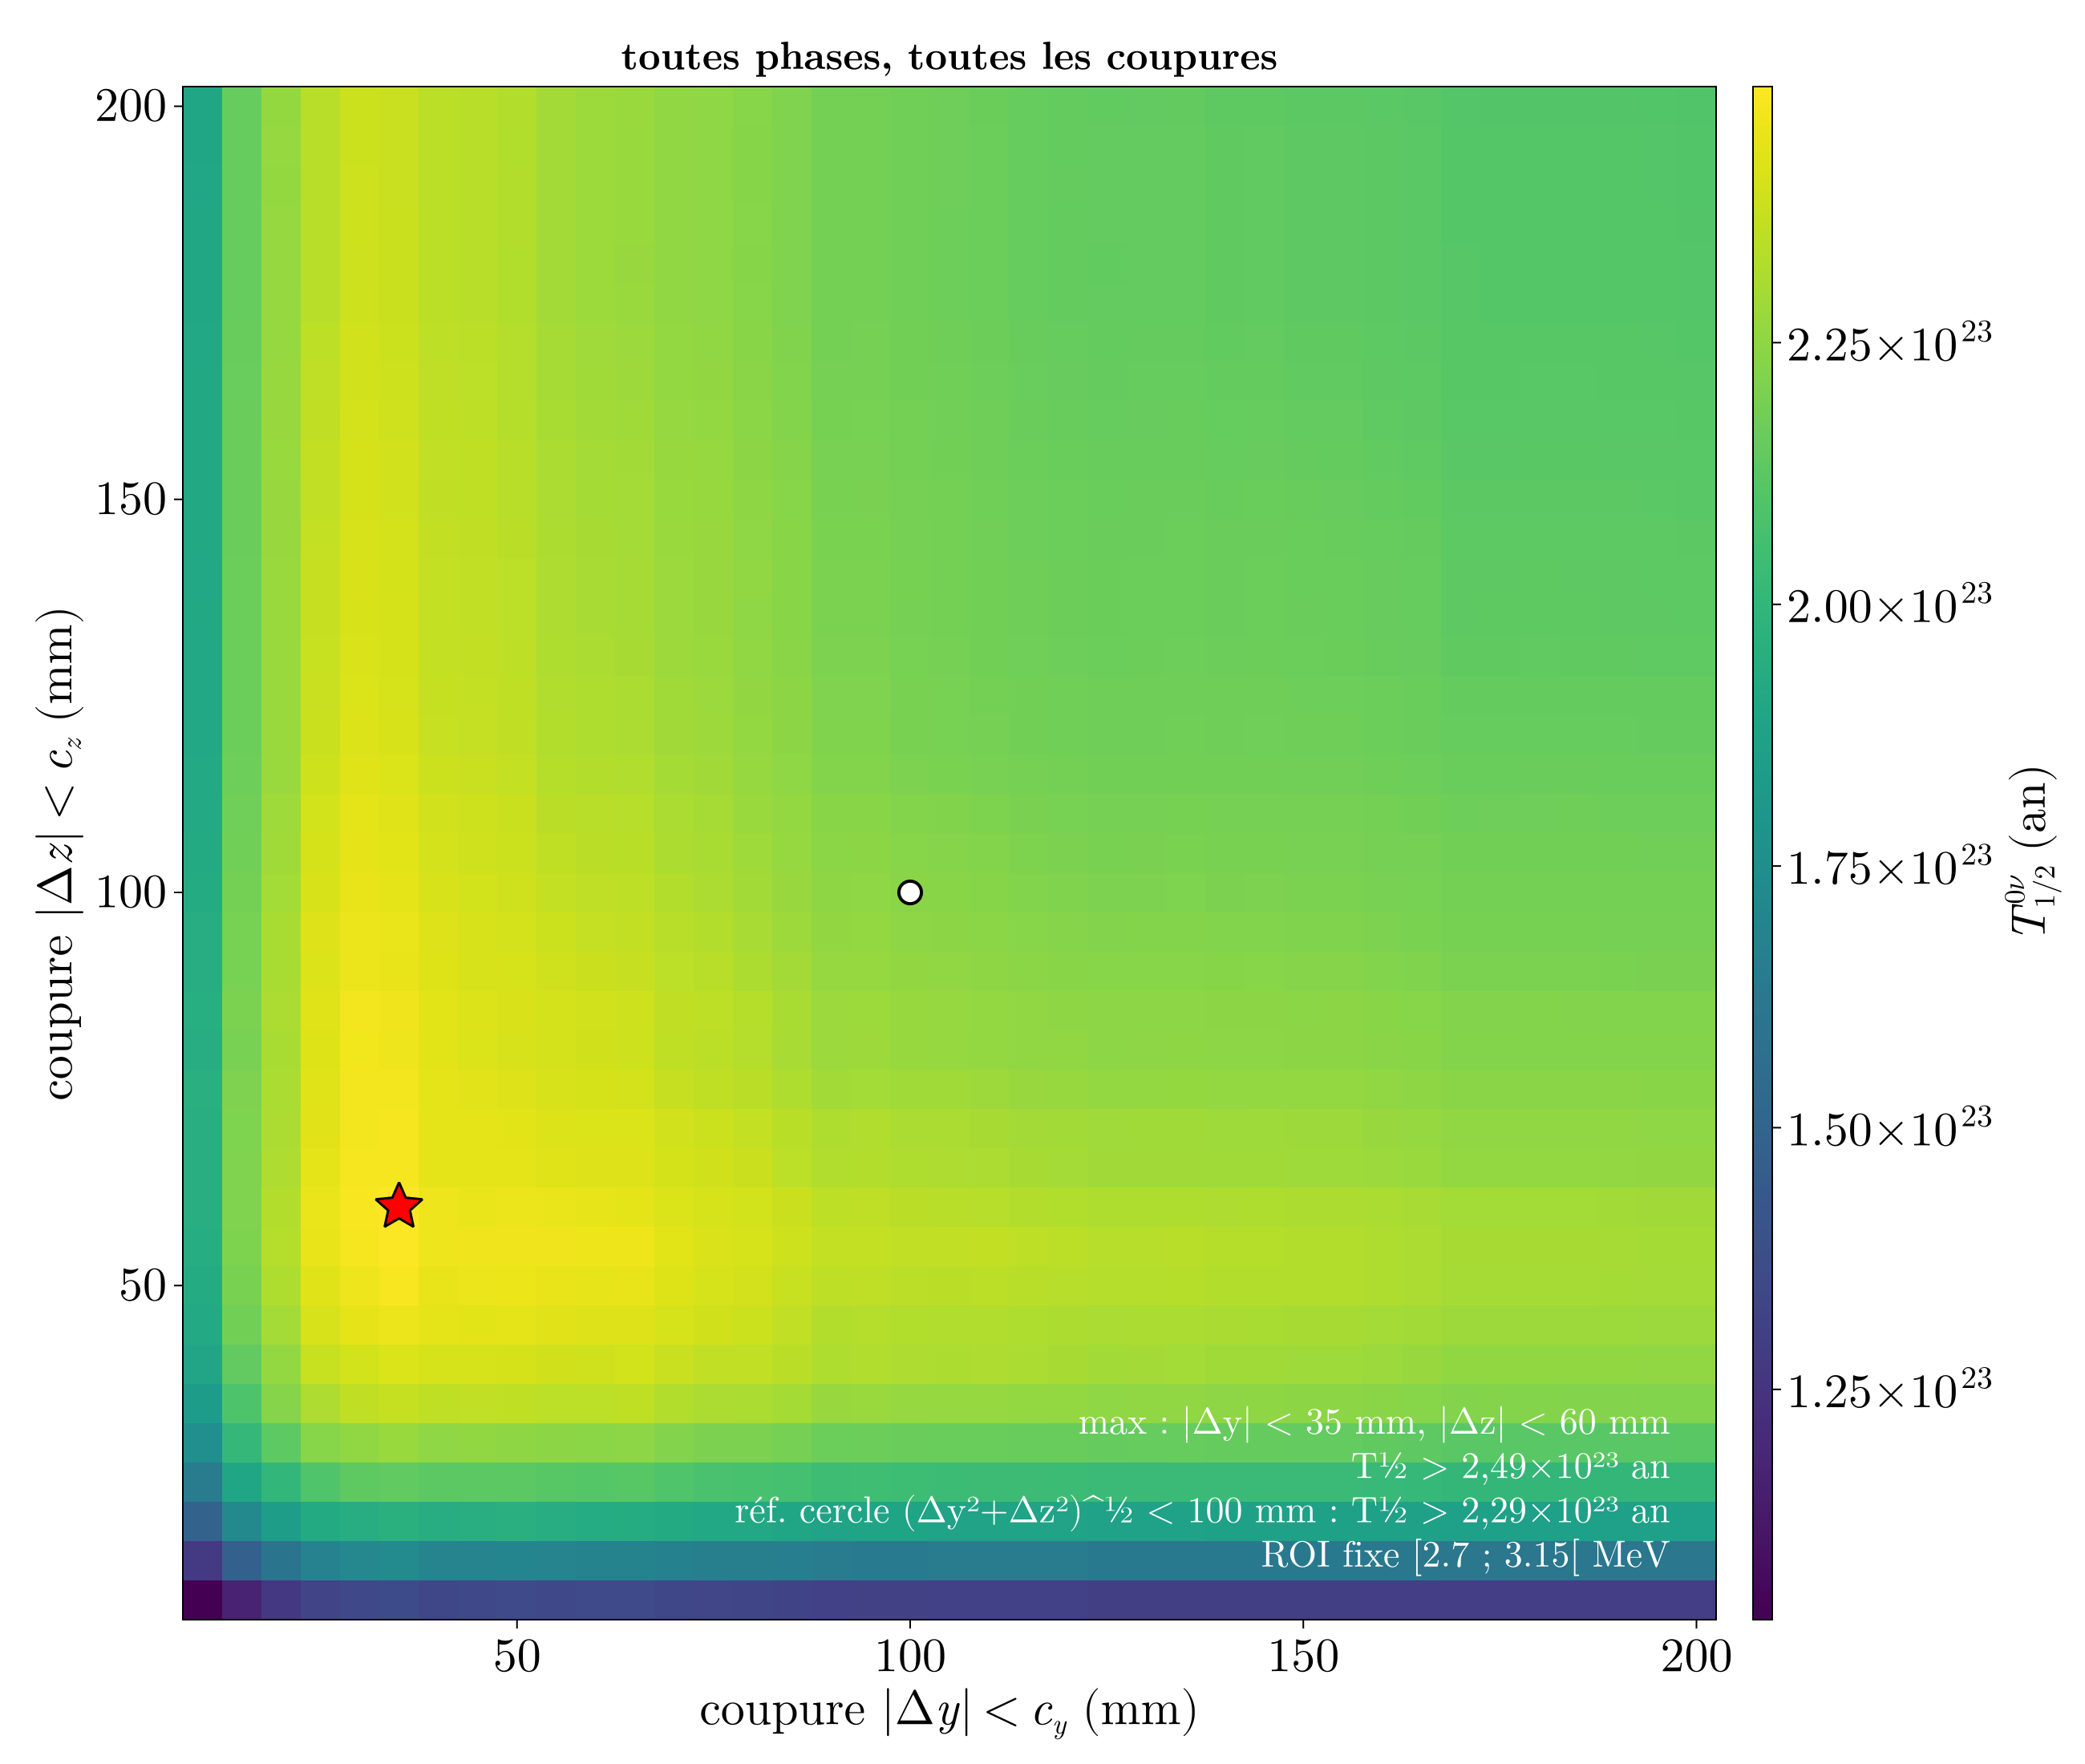

toutes phases  max |Δy| <  30 mm : T½ > 2,38×10²³ (b = 14.85)   max |Δz| <  55 mm : T½ > 2,3×10²³ (b = 20.16)   2D : |Δy| < 35, |Δz| < 60 mm : T½ > 2,49×10²³   réf. cercle : 2,29×10²³ (b = 22.48)

=== toutes les coupures, radon 2 mBq/m³ ===
P0             max |Δy| < 165 mm : T½ > 8,95×10²² (b = 0.87)   max |Δz| < 105 mm : T½ > 8,94×10²² (b = 0.82)   2D : |Δy| < 165, |Δz| < 105 mm : T½ > 8,95×10²²   réf. cercle : 8,86×10²² (b = 0.78)
P1             max |Δy| < 145 mm : T½ > 6,71×10²² (b = 0.3)   max |Δz| < 200 mm : T½ > 6,7×10²² (b = 0.31)   2D : |Δy| < 165, |Δz| < 200 mm : T½ > 6,71×10²²   réf. cercle : 6,54×10²² (b = 0.28)
P2             max |Δy| < 200 mm : T½ > 4,96×10²² (b = 0.18)   max |Δz| < 200 mm : T½ > 4,96×10²² (b = 0.18)   2D : |Δy| < 145, |Δz| < 195 mm : T½ > 4,96×10²²   réf. cercle : 4,82×10²² (b = 0.16)
P3             max |Δy| < 155 mm : T½ > 2,11×10²³ (b = 1.01)   max |Δz| < 140 mm : T½ > 2,11×10²³ (b = 0.99)   2D : |Δy| < 145, |Δz| < 195 mm : T½ > 2,11×10²³   réf. cercle 

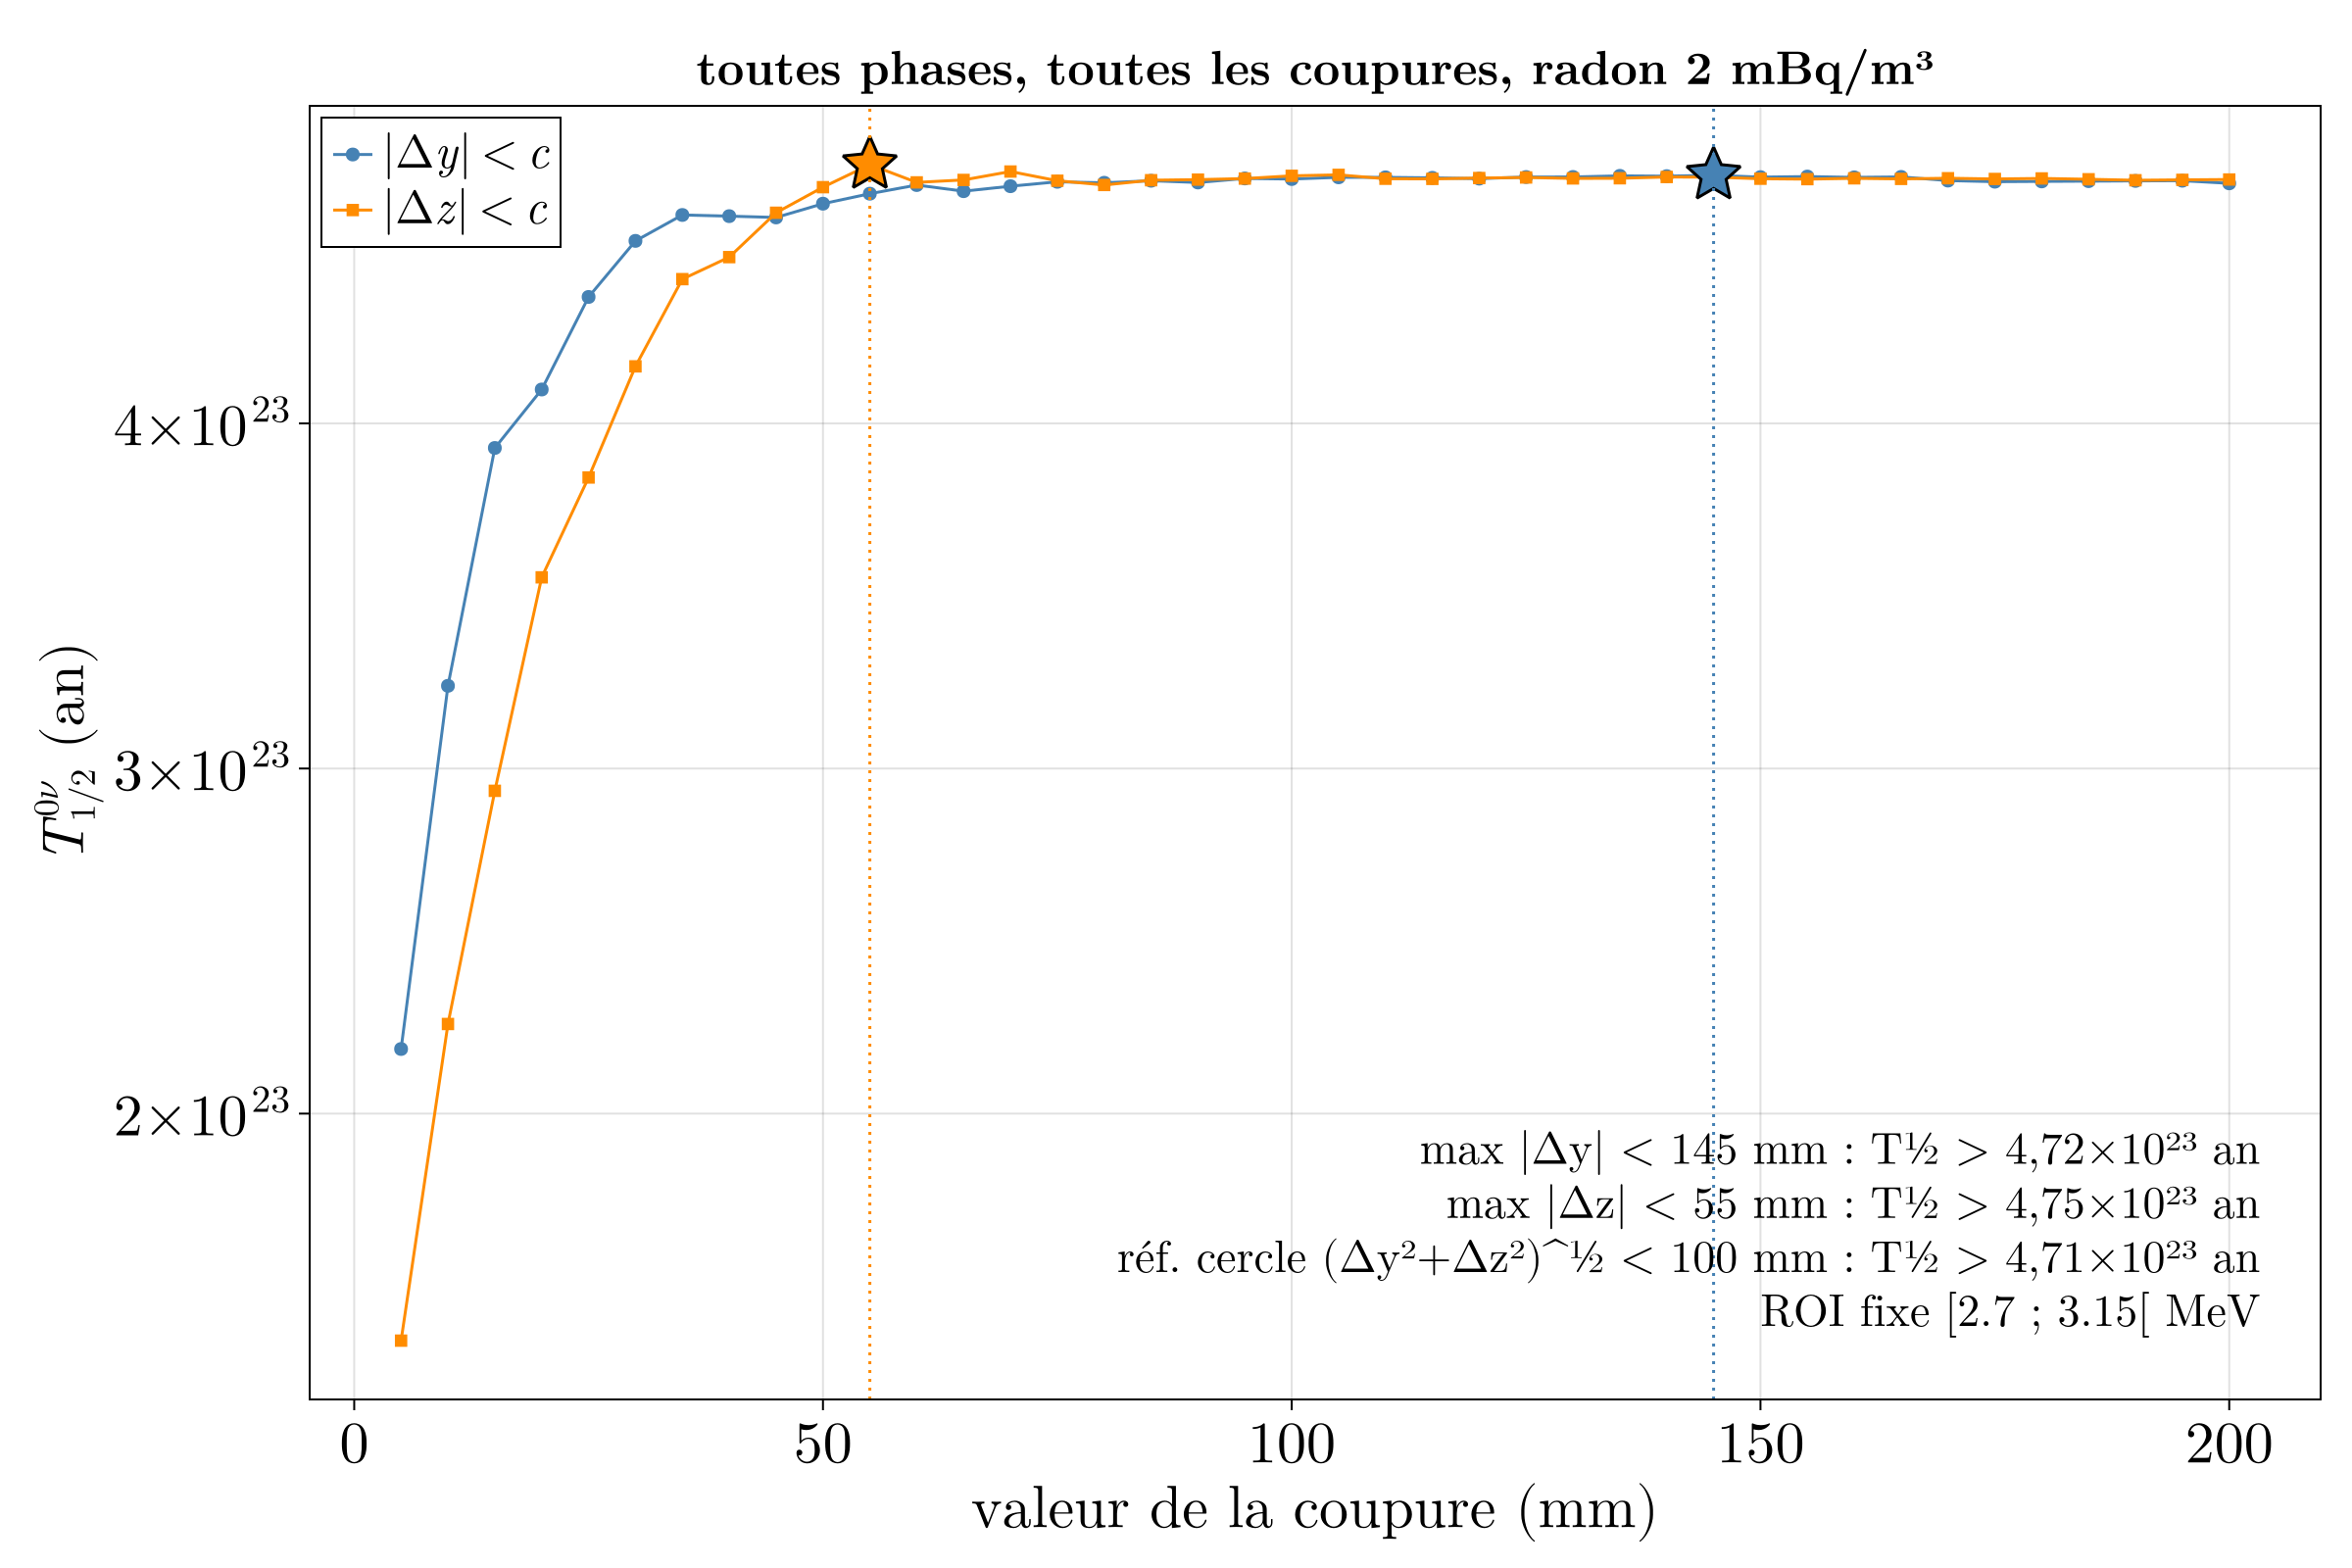

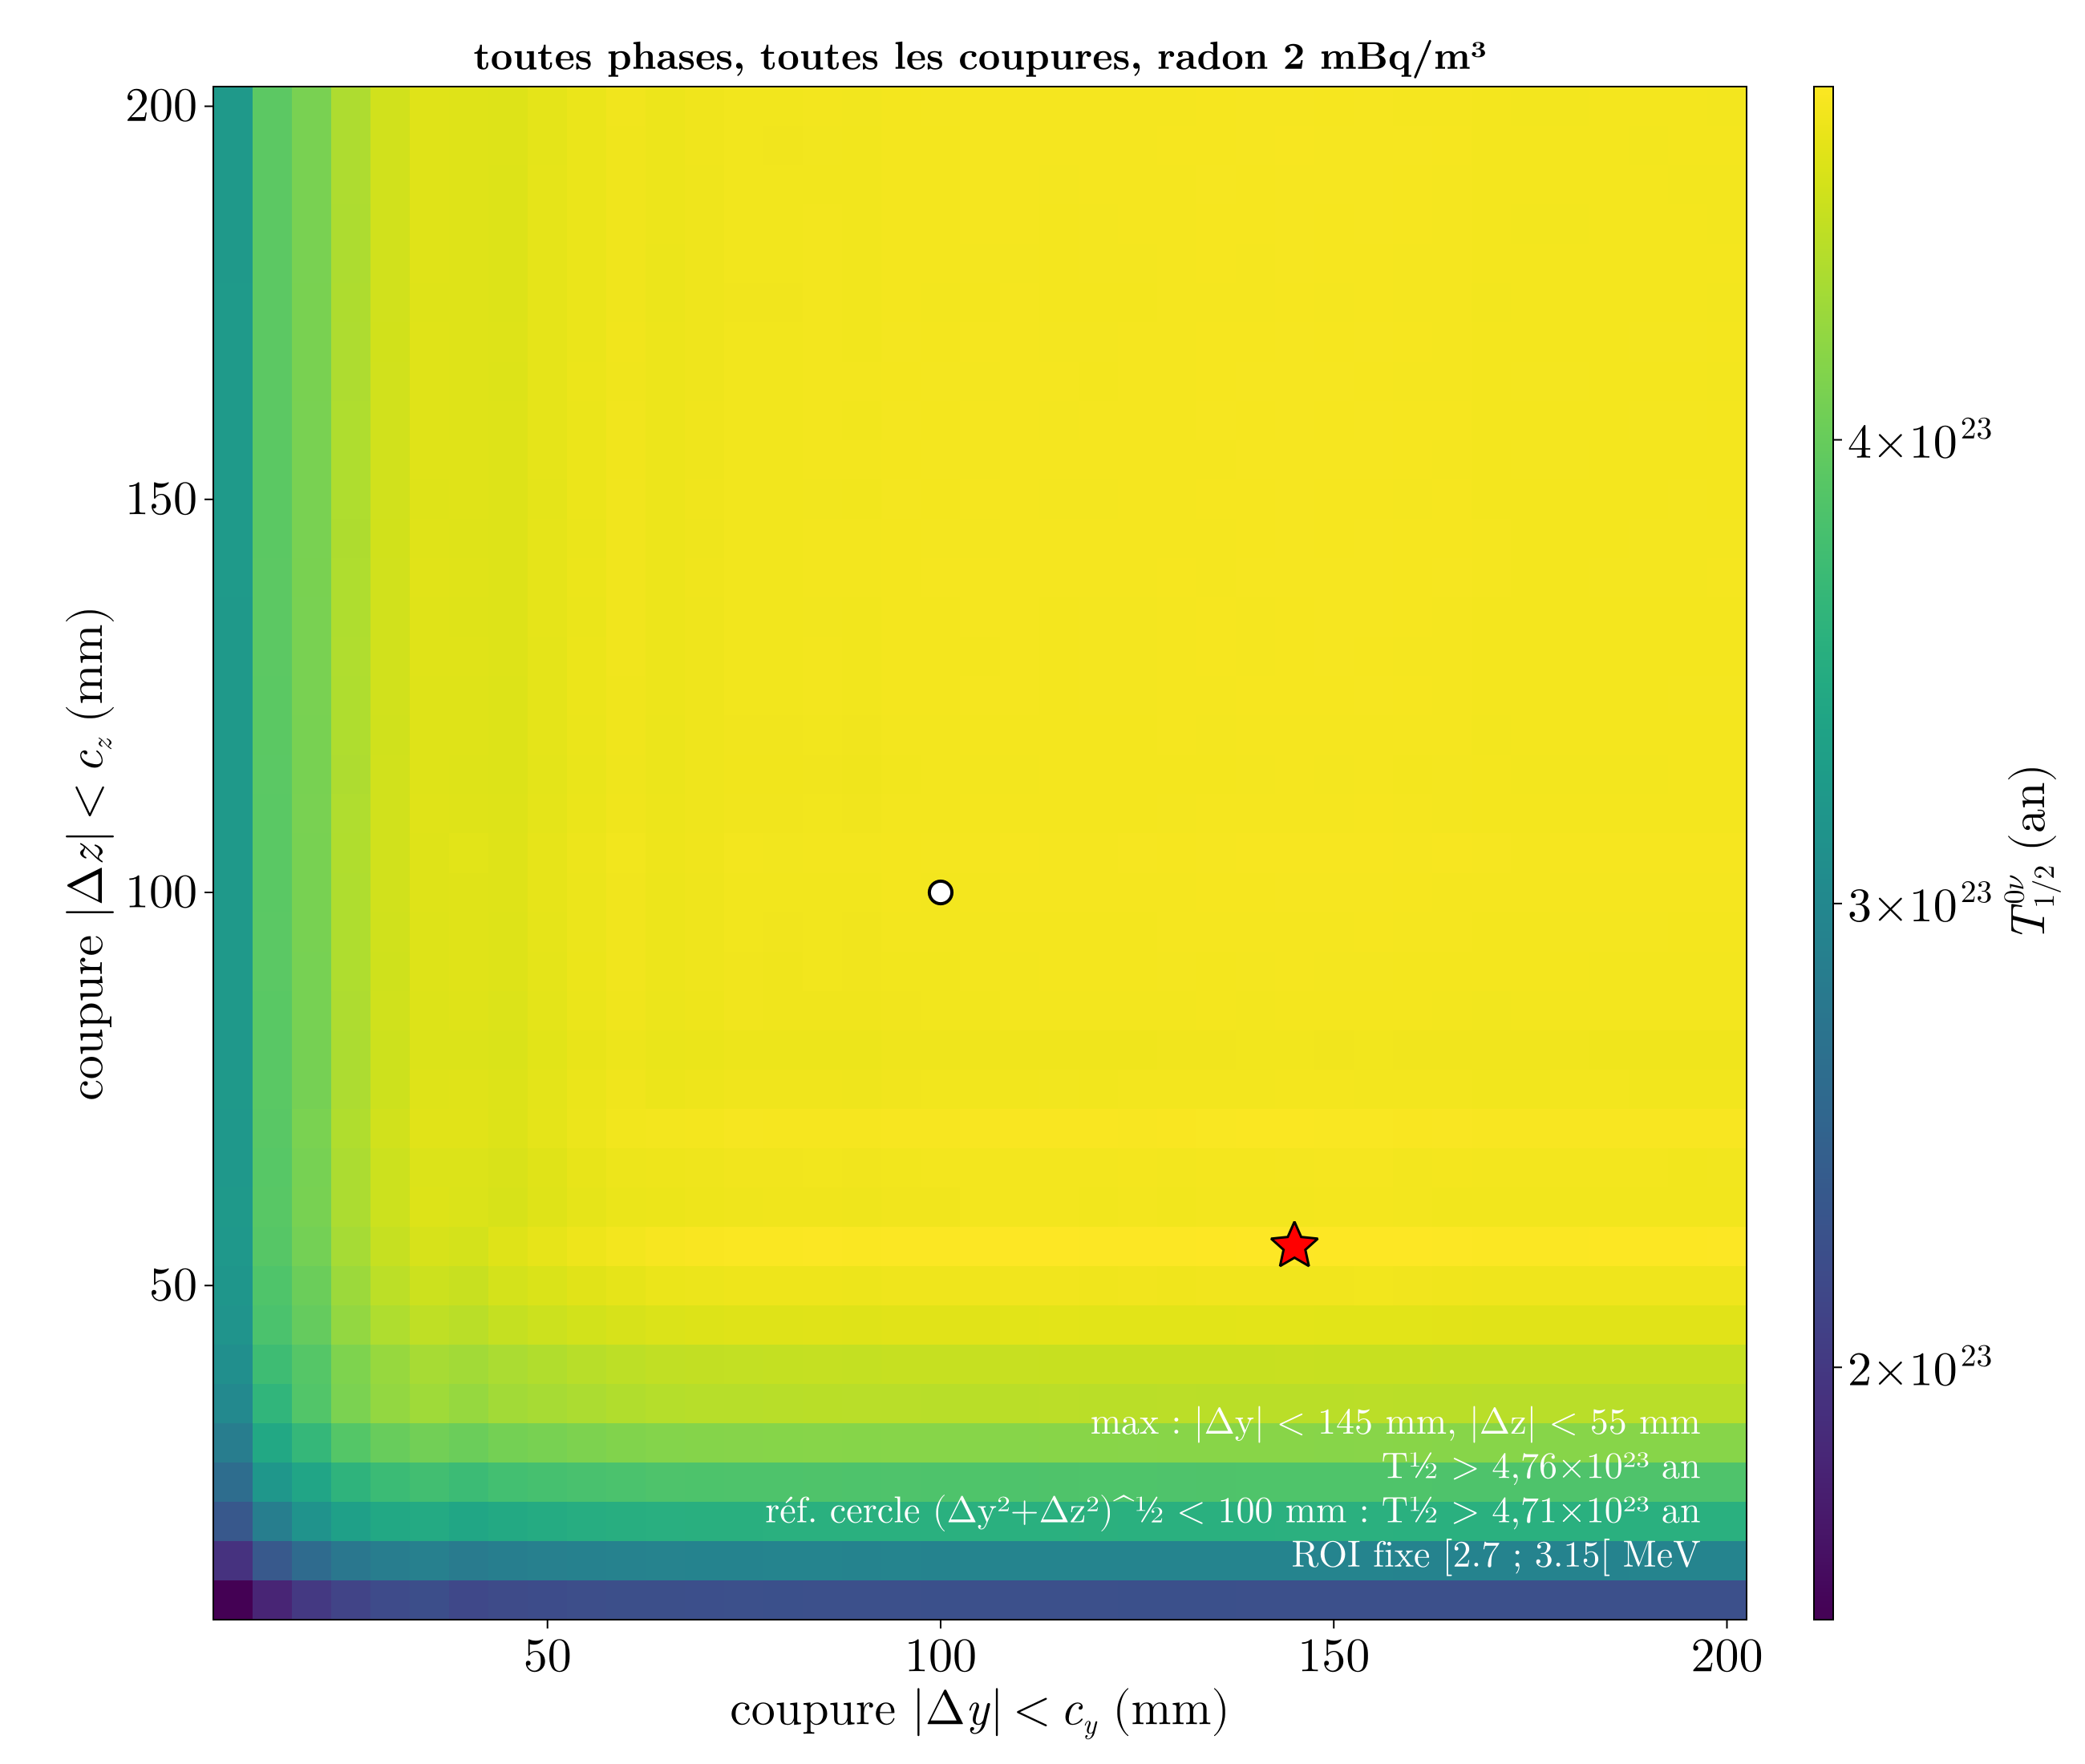

toutes phases  max |Δy| < 145 mm : T½ > 4,72×10²³ (b = 3.86)   max |Δz| <  55 mm : T½ > 4,75×10²³ (b = 2.93)   2D : |Δy| < 145, |Δz| < 55 mm : T½ > 4,76×10²³   réf. cercle : 4,71×10²³ (b = 3.5)

Tout est dans /sps/nemo/scratch/granjon/sensitivity_from_Maros_training/SN_Sensitivity_training/data/out/ex8/scan_dydz_final


In [64]:
# =====================================================================================
# SCAN FINAL DES COUPURES |Δy| / |Δz|  —  une seule cellule, à coller à la fin de ex8
#
# Prérequis : sections 1 à 3 du notebook (fonctions et constantes), et la cellule 4c si NEUTRON_K n'est pas
# donné à la main ci-dessous.
#
# Ce que fait la cellule :
#   • ROI FIXE [2,70 ; 3,15[ MeV pour tout (plus de ré-optimisation de la ROI)
#   • coupures identiques à select_esum (macro + angle), sauf √(Δy²+Δz²) < 100 mm remplacée par le scan
#   • 4 scénarios, toutes phases :
#        aucune        : aucune autre coupure (base : 2 électrons, 2 OMs valides)
#        temps         : seulement |Δt_int| < 1,5 ns
#        toutes        : toutes les coupures habituelles
#        toutes_radon2 : toutes les coupures, radon à 2 mBq/m³ dans toutes les phases
#   • pour chaque scénario : 1 plot 1D (|Δy| < c sans coupure sur Δz, |Δz| < c sans coupure sur Δy, même canvas)
#                            + 1 carte 2D (|Δy| < c_y ET |Δz| < c_z)
#   • neutrons renormalisés avec le facteur ajusté (mode :fitted, K de la cellule 4c)
#   • tout est ENREGISTRÉ par phase et en global dans OUT_DIR/scan_dydz_final/ ;
#     seuls les plots GLOBAUX sont affichés dans le notebook
# =====================================================================================

using Serialization

# ---------------- paramètres ----------------
ROI           = (2.70, 3.15)        # MeV, ROI fixe [E_min ; E_max[
RADON_LOW     = 2e-3                # Bq/m³ = 2 mBq/m³ pour le scénario toutes_radon2
NEUTRON_K_FIT = NEUTRON_K           # facteur ajusté en 4c ; si NEUTRON_K vaut nothing, mettre ici la valeur affichée par 4c
STEP          = 5.0                 # mm, pas des coupures
DYDZ_MAX      = 300.0               # mm, évènements gardés jusqu'à |Δ| < 300 mm (= pas de coupure)
NBIN          = round(Int, DYDZ_MAX / STEP)
CUTS1D        = 5.0:STEP:200.0
CUTS2D        = 10.0:STEP:200.0
E_SCAN_MIN    = 2.0                 # MeV, seuls les évènements au-dessus sont gardés en mémoire
OUT_SCAN      = joinpath(OUT_DIR, "scan_dydz_final"); mkpath(OUT_SCAN)

NEUTRON_K_FIT === nothing && error("NEUTRON_K_FIT vaut nothing : lance la cellule 4c ou mets la valeur de K à la main en haut de la cellule.")

# ---------------- coupures (identiques à select_esum) ----------------
CUT_LIST = [:same_calo, :closest_gamma, :closest_elec, :closest_track, :closest_time_track,
            :temps, :seuil_350keV, :kinks, :region_vertex, :angle]
BIT = Dict(c => UInt16(1) << (i - 1) for (i, c) in enumerate(CUT_LIST))
mask_of(cuts) = reduce(|, (BIT[c] for c in cuts); init = UInt16(0))

# lecture évènement par évènement (même boucle que select_esum) ; bit à 1 = l'évènement PASSE la coupure
function select_flags(path, good)
    t = UnROOT.LazyTree(UnROOT.ROOTFile(path), "Event", VAR_NAMES)
    E = Float64[]; ady = Float64[]; adz = Float64[]; fl = UInt16[]
    for ev in t
        ev.energy_elec_sum < E_SCAN_MIN && continue
        dy, dz = abs(ev.delta_y_elec), abs(ev.delta_z_elec)
        (dy >= DYDZ_MAX || dz >= DYDZ_MAX) && continue
        om = ev.num_om_elec_f
        length(om) != 2 && continue
        (om[1] > 520 || om[2] > 520) && continue
        (!good[om[1] + 1] || !good[om[2] + 1]) && continue
        f = UInt16(0)
        ev.hit_the_same_calo_hit == 1                          || (f |= BIT[:same_calo])
        abs(ev.closest_gamma) <= 50                            || (f |= BIT[:closest_gamma])
        abs(ev.closest_elec) <= 25                             || (f |= BIT[:closest_elec])
        abs(ev.closest_track) < 200                            || (f |= BIT[:closest_track])
        abs(ev.closest_time_track) < 10                        || (f |= BIT[:closest_time_track])
        abs(ev.internal_theoretical_time_diff) >= 1.5          || (f |= BIT[:temps])
        (ev.energy_elec_1 < 0.350 || ev.energy_elec_2 < 0.350) || (f |= BIT[:seuil_350keV])
        ev.has_kinks == 1                                      || (f |= BIT[:kinks])
        vy, vz = ev.vertex_3D_start_y, ev.vertex_3D_start_z
        inreg = false
        if length(vy) >= 2 && length(vz) >= 2
            y = 0.5 * (vy[1] + vy[2]); z = 0.5 * (vz[1] + vz[2])
            inreg = ((y - 1180) / 60)^2 + ((z + 850) / 140)^2 <= 1 || ((y - 1144) / 25)^2 + ((z - 196) / 40)^2 <= 1 ||
                    ((y - 1114) / 25)^2 + ((z + 257) / 40)^2 <= 1 || abs(y) > 2360 || abs(z) > 1340
        end
        inreg                                                  || (f |= BIT[:region_vertex])
        ev.angle_3D_between_ep_em < 50                         || (f |= BIT[:angle])
        push!(E, ev.energy_elec_sum); push!(ady, dy); push!(adz, dz); push!(fl, f)
    end
    return (E = E, ady = ady, adz = adz, fl = fl)
end

function load_phase_flags(ph)
    sim = SIM_OF[ph]; t = LIVE_S[ph]; bkg = NamedTuple[]
    for (name, pmt, A, _, _) in COMPONENTS
        p = mc_file(name, sim; pmt = pmt)
        (haskey(PARAMS, p) && PARAMS[p][1] > 0) || continue
        push!(bkg, (name = name, w = A(ph) * t / PARAMS[p][1], ev = select_flags(p, GOOD[ph])))
    end
    if INCLUDE_NEUTRONS
        np = NEUTRON_OF[ph]; suffix = "_phase" * np
        for (k, sf) in NEUTRON_SCALES
            endswith(k, suffix) || continue
            speed, dir, elem = split(k[1:end-length(suffix)], "_"; limit = 3)
            elem == "inelastic" && continue
            fn = joinpath(NEUTRON_PATH, speed, dir, elem, "phase$np", "combined_phase$np.root")
            isfile(fn) || continue
            push!(bkg, (name = "n_$(speed)_$(dir)_$(elem)", w = neutron_rate_per_event(sf, t) * t, ev = select_flags(fn, GOOD[ph])))
        end
    end
    sp = isfile(BB0NU_FILE(sim)) ? BB0NU_FILE(sim) : BB0NU_FALLBACK(sim)
    nsim = haskey(PARAMS, sp) && PARAMS[sp][1] > 0 ? PARAMS[sp][1] : BB0NU_NSIM_FALLBACK
    return (phase = ph, t_s = t, bkg = bkg, sig = (w = 1 / nsim, ev = select_flags(sp, GOOD[ph])),
            data = select_flags(joinpath(DATA_PATH, "phase_$ph.root"), GOOD[ph]))
end

# ---------------- chargement (une seule fois, ~35 min, puis relu en quelques secondes) ----------------
SCAN_FILE = joinpath(OUT_DIR, "SETS_SCAN.jls")
V2_FILE   = joinpath(OUT_DIR, "SETS_FLAGS_v2.jls")      # produit par cellule_scan_dy_dz_coupures.jl (corrigée), si déjà lancé
if isfile(SCAN_FILE)
    tmp = deserialize(SCAN_FILE); SETS_RAW = tmp.sets; LOAD_MODE = tmp.neutron_mode
    println("Évènements relus depuis $SCAN_FILE (neutrons chargés en mode $LOAD_MODE)")
elseif isfile(V2_FILE)
    SETS_RAW = deserialize(V2_FILE); LOAD_MODE = :fit_ref   # mode des neutrons au moment où ce fichier a été créé
    println("Évènements relus depuis $V2_FILE (neutrons chargés en mode $LOAD_MODE)")
else
    LOAD_MODE = NEUTRON_MODE
    @time SETS_RAW = Threads.nthreads() > 1 ? fetch.([Threads.@spawn load_phase_flags(ph) for ph in PHASES]) :
                                              [load_phase_flags(ph) for ph in PHASES]
    serialize(SCAN_FILE, (sets = SETS_RAW, neutron_mode = LOAD_MODE))
end

# ---------------- renormalisation des neutrons sur le facteur ajusté (mode :fitted) ----------------
function rate_mode(mode, t)
    old_m, old_k = NEUTRON_MODE, NEUTRON_K
    global NEUTRON_MODE = mode; global NEUTRON_K = NEUTRON_K_FIT
    r = neutron_rate_per_event(1.0, t)
    global NEUTRON_MODE = old_m; global NEUTRON_K = old_k
    return r
end
SETS_N = [merge(s, (bkg = NamedTuple[startswith(p.name, "n_") ? merge(p, (w = p.w * rate_mode(:fitted, s.t_s) / rate_mode(LOAD_MODE, s.t_s),)) : p
                                     for p in s.bkg],)) for s in SETS_RAW]
println("Neutrons : poids × ", join([string(round(rate_mode(:fitted, s.t_s) / rate_mode(LOAD_MODE, s.t_s), sigdigits = 3)) for s in SETS_RAW], ", "),
        " (phases ", join([s.phase for s in SETS_RAW], ", "), "), K = $NEUTRON_K_FIT")

radon_at(sets, A) = [merge(s, (bkg = NamedTuple[p.name in ("radon", "radon_surface") ? merge(p, (w = p.w * A / RADON_BQ_M3[s.phase],)) : p
                                               for p in s.bkg],)) for s in sets]

SCENARIOS = [("aucune",        "aucune autre coupure",                           mask_of(Symbol[]), SETS_N),
             ("temps",         "coupure temporelle seule",                       mask_of([:temps]), SETS_N),
             ("toutes",        "toutes les coupures",                            mask_of(CUT_LIST), SETS_N),
             ("toutes_radon2", "toutes les coupures, radon 2 mBq/m³",            mask_of(CUT_LIST), radon_at(SETS_N, RADON_LOW))]

# ---------------- outils ----------------
inroi(E) = ROI[1] <= E < ROI[2]
dbin(d)  = min(floor(Int, d / STEP) + 1, NBIN)
ic(c)    = round(Int, c / STEP)                      # |Δ| < c  ⇔  bin ≤ c/STEP

# histogramme 2D cumulé (|Δy|, |Δz|) des poids dans la ROI : C[i, j] = Σ w pour |Δy| < i·STEP et |Δz| < j·STEP
function cum2d(ev, w, m)
    H = zeros(NBIN, NBIN)
    @inbounds for k in eachindex(ev.E)
        inroi(ev.E[k]) || continue
        (ev.fl[k] & m) == m || continue
        H[dbin(ev.ady[k]), dbin(ev.adz[k])] += w
    end
    return cumsum(cumsum(H, dims = 1), dims = 2)
end
# b et ε (par phase) pour une coupure quelconque pass(|Δy|, |Δz|), évènement par évènement (pour la référence cercle)
bε_event(s, pass, m) = (sum(p.w * count(k -> inroi(p.ev.E[k]) && (p.ev.fl[k] & m) == m && pass(p.ev.ady[k], p.ev.adz[k]), eachindex(p.ev.E)) for p in s.bkg),
                        s.sig.w * count(k -> inroi(s.sig.ev.E[k]) && (s.sig.ev.fl[k] & m) == m && pass(s.sig.ev.ady[k], s.sig.ev.adz[k]), eachindex(s.sig.ev.E)))
# T½ pour une liste de phases : ε pondérée par les durées, b sommé
function thalf(ts, bs, εs)
    T = sum(ts); ε = sum(εs .* ts) / T; b = sum(bs)
    return (tHalf = κ * (T / YEAR) * ε / N_exclus(b), eff = ε, bkg = b)
end

# contrôle : coupure circulaire 100 mm, ROI ré-optimisée, toutes coupures, radon mesuré (doit redonner la carte E_min/E_max)
function sens_opt(sets, pass, m)
    NBE = length(BINS) - 1; T = sum(s.t_s for s in sets); b = zeros(NBE); ε = zeros(NBE)
    function addh!(h, ev, w)
        for k in eachindex(ev.E)
            ((ev.fl[k] & m) == m && pass(ev.ady[k], ev.adz[k])) || continue
            i = searchsortedlast(BINS, ev.E[k]); 1 <= i <= NBE && (h[i] += w)
        end
    end
    for s in sets
        for p in s.bkg; addh!(b, p.ev, p.w); end
        addh!(ε, s.sig.ev, s.sig.w * s.t_s / T)
    end
    cb = [0.0; cumsum(b)]; cε = [0.0; cumsum(ε)]; best = (tHalf = 0.0, roi = (0.0, 0.0), bkg = 0.0)
    for i in searchsortedlast(BINS, E_SCAN_MIN):NBE, j in i:NBE
        th = κ * (T / YEAR) * (cε[j + 1] - cε[i]) / N_exclus(cb[j + 1] - cb[i])
        th > best.tHalf && (best = (tHalf = th, roi = (round(BINS[i], digits = 2), round(BINS[j + 1], digits = 2)), bkg = cb[j + 1] - cb[i]))
    end
    best
end
circ100(y, z) = y^2 + z^2 < 100^2
C0 = sens_opt(SETS_N, circ100, mask_of(CUT_LIST))
println("Contrôle (cercle 100 mm, toutes coupures, ROI ré-optimisée) : ROI $(C0.roi), b = $(round(C0.bkg, digits = 2)), T½ > $(sci(C0.tHalf)) an  (attendu 2,16×10²³)")

function save_fig(f, name, disp)
    save(joinpath(OUT_SCAN, name * ".pdf"), f); save(joinpath(OUT_SCAN, name * ".png"), f, px_per_unit = 2)
    disp && display(f)
end

function plot1d(Ty, Tz, ref, titre, name, disp)
    iy = argmax(Ty); iz = argmax(Tz)
    f = with_theme(theme_latexfonts()) do
        f = Figure(size = (1200, 800), fontsize = 30)
        ax = Axis(f[1, 1], xlabel = "valeur de la coupure (mm)", ylabel = L"T_{1/2}^{0\nu}\ \mathrm{(an)}", title = titre, titlesize = 24)
        scatterlines!(ax, collect(CUTS1D), Ty, color = :steelblue,  marker = :circle, markersize = 10, label = L"|\Delta y| < c")
        scatterlines!(ax, collect(CUTS1D), Tz, color = :darkorange, marker = :rect,   markersize = 10, label = L"|\Delta z| < c")
        scatter!(ax, [CUTS1D[iy]], [Ty[iy]], color = :steelblue,  marker = :star5, markersize = 32, strokecolor = :black, strokewidth = 1.5)
        scatter!(ax, [CUTS1D[iz]], [Tz[iz]], color = :darkorange, marker = :star5, markersize = 32, strokecolor = :black, strokewidth = 1.5)
        vlines!(ax, [CUTS1D[iy]], color = :steelblue, linestyle = :dot); vlines!(ax, [CUTS1D[iz]], color = :darkorange, linestyle = :dot)
        text!(ax, 0.97, 0.05, space = :relative, align = (:right, :bottom), fontsize = 23,
              text = "max |Δy| < $(Int(CUTS1D[iy])) mm : T½ > $(sci(Ty[iy])) an\nmax |Δz| < $(Int(CUTS1D[iz])) mm : T½ > $(sci(Tz[iz])) an\n" *
                     "réf. cercle (Δy²+Δz²)^½ < 100 mm : T½ > $(sci(ref)) an\nROI fixe [$(ROI[1]) ; $(ROI[2])[ MeV")
        axislegend(ax, position = :lt, framevisible = true, labelsize = 24)
        f
    end
    save_fig(f, name, disp)
    return (iy = iy, iz = iz)
end

function plot2d(T2, ref, titre, name, disp)
    I = argmax(T2)
    f = with_theme(theme_latexfonts()) do
        f = Figure(size = (1300, 1100), fontsize = 30)
        ax = Axis(f[1, 1], xlabel = L"\mathrm{coupure}\ |\Delta y| < c_y\ \mathrm{(mm)}", ylabel = L"\mathrm{coupure}\ |\Delta z| < c_z\ \mathrm{(mm)}",
                  title = titre, titlesize = 24, aspect = 1)
        hm = heatmap!(ax, CUTS2D, CUTS2D, T2, colormap = :viridis)
        scatter!(ax, [100.0], [100.0], color = :white, marker = :circle, markersize = 20, strokecolor = :black, strokewidth = 2)
        scatter!(ax, [CUTS2D[I[1]]], [CUTS2D[I[2]]], color = :red, marker = :star5, markersize = 34, strokecolor = :black, strokewidth = 1.5)
        text!(ax, 0.97, 0.03, space = :relative, align = (:right, :bottom), fontsize = 23, color = :white,
              text = "max : |Δy| < $(Int(CUTS2D[I[1]])) mm, |Δz| < $(Int(CUTS2D[I[2]])) mm\nT½ > $(sci(T2[I])) an\n" *
                     "réf. cercle (Δy²+Δz²)^½ < 100 mm : T½ > $(sci(ref)) an\nROI fixe [$(ROI[1]) ; $(ROI[2])[ MeV")
        Colorbar(f[1, 2], hm, label = L"T_{1/2}^{0\nu}\;\mathrm{(an)}")
        f
    end
    save_fig(f, name, disp)
    return I
end

# ---------------- calcul et figures ----------------
ROWS = []; ROWS2D = []
function run_scenario(tag, titre, m, sets)
    Cb = [sum(cum2d(p.ev, p.w, m) for p in s.bkg) for s in sets]          # bruit de fond cumulé, par phase
    Cs = [cum2d(s.sig.ev, s.sig.w, m) for s in sets]                       # efficacité cumulée, par phase
    ts = [s.t_s for s in sets]
    REFS = [bε_event(s, circ100, m) for s in sets]
    groups = [[("P$(s.phase)", [k], false) for (k, s) in enumerate(sets)]; [("toutes phases", collect(eachindex(sets)), true)]]
    println("\n=== $titre ===")
    for (lab, ks, disp) in groups
        res = (iy, iz) -> thalf(ts[ks], [Cb[k][iy, iz] for k in ks], [Cs[k][iy, iz] for k in ks])
        ref = thalf(ts[ks], [REFS[k][1] for k in ks], [REFS[k][2] for k in ks])
        Ry  = [res(ic(c), NBIN) for c in CUTS1D]                           # |Δy| < c, aucune coupure sur Δz
        Rz  = [res(NBIN, ic(c)) for c in CUTS1D]                           # |Δz| < c, aucune coupure sur Δy
        R2  = [res(ic(cy), ic(cz)) for cy in CUTS2D, cz in CUTS2D]
        ftag = lab == "toutes phases" ? "global" : lab
        tit  = "$lab, $titre"
        o1 = plot1d([r.tHalf for r in Ry], [r.tHalf for r in Rz], ref.tHalf, tit, "scan1D_$(tag)_$(ftag)", disp)
        I2 = plot2d([r.tHalf for r in R2], ref.tHalf, tit, "map2D_$(tag)_$(ftag)", disp)
        println(rpad(lab, 15), "max |Δy| < ", lpad(Int(CUTS1D[o1.iy]), 3), " mm : T½ > ", sci(Ry[o1.iy].tHalf), " (b = ", round(Ry[o1.iy].bkg, digits = 2), ")   ",
                "max |Δz| < ", lpad(Int(CUTS1D[o1.iz]), 3), " mm : T½ > ", sci(Rz[o1.iz].tHalf), " (b = ", round(Rz[o1.iz].bkg, digits = 2), ")   ",
                "2D : |Δy| < ", Int(CUTS2D[I2[1]]), ", |Δz| < ", Int(CUTS2D[I2[2]]), " mm : T½ > ", sci(R2[I2].tHalf), "   ",
                "réf. cercle : ", sci(ref.tHalf), " (b = ", round(ref.bkg, digits = 2), ")")
        for (i, c) in enumerate(CUTS1D)
            push!(ROWS, (scenario = tag, groupe = lab, cut_mm = c,
                         tHalf_dy = Ry[i].tHalf, b_dy = Ry[i].bkg, eff_dy = Ry[i].eff,
                         tHalf_dz = Rz[i].tHalf, b_dz = Rz[i].bkg, eff_dz = Rz[i].eff, tHalf_ref_cercle = ref.tHalf))
        end
        for I in CartesianIndices(R2)
            push!(ROWS2D, (scenario = tag, groupe = lab, cut_y = CUTS2D[I[1]], cut_z = CUTS2D[I[2]],
                           tHalf = R2[I].tHalf, b = R2[I].bkg, eff = R2[I].eff))
        end
    end
    return nothing
end
for sc in SCENARIOS; run_scenario(sc...); end
CSV.write(joinpath(OUT_SCAN, "scan1D_tous.csv"), DataFrame(ROWS))
CSV.write(joinpath(OUT_SCAN, "map2D_tous.csv"),  DataFrame(ROWS2D))
println("\nTout est dans $OUT_SCAN")

In [70]:
# =====================================================================================
# EFFICACITÉ PAR SIMULATION : nom + ε
# ε = N_sélectionnés / N_simulés avec toutes les coupures de select_esum (celles de SETS),
# phases combinées en pondérant par leur durée : ε = Σ_p ε_p t_p / T.
# Sorties : OUT_DIR/table_efficacites.tex et .csv
# =====================================================================================
T_EFF = sum(s.t_s for s in SETS)
NAMES_EFF = vcat("bb0nu", [c[1] for c in COMPONENTS])

function eff_of(name)
    ε = 0.0; found = false
    for s in SETS, p in s.procs
        p.isotopeName == name || continue
        found = true; ε += 100*(s.t_s / T_EFF) * length(p.dataVector) / p.nTotalSim
    end
    return found ? ε : missing
end

function tex_sci(x; d = 1)
    x == 0 && return "0"
    e = floor(Int, log10(abs(x))); m = round(x / 10.0^e, digits = d)
    m >= 10 && (m /= 10; e += 1)
    ms = replace(string(m), "." => "{,}")
    return e == 0 ? "\$$ms\$" : "\$$ms\\times10^{$e}\$"
end

dfE = DataFrame(simulation = NAMES_EFF, efficacite = [eff_of(n) for n in NAMES_EFF])
dfE = dfE[.!ismissing.(dfE.efficacite), :]
CSV.write(joinpath(OUT_DIR, "table_efficacites.csv"), dfE)
let io = IOBuffer()
    println(io, "\\begin{tabular}{lc}\n\\toprule\nSimulation & \$\\varepsilon\$ \\\\\n\\midrule")
    for r in eachrow(dfE)
        println(io, replace(r.simulation, "_" => "\\_"), " & ", tex_sci(r.efficacite), " \\\\")
    end
    println(io, "\\bottomrule\n\\end{tabular}")
    write(joinpath(OUT_DIR, "table_efficacites.tex"), String(take!(io)))
end
dfE

Row,simulation,efficacite
,String,Float64
1,bb0nu,13.8033
2,bb2nu,3.06714
3,radon,0.00458969
4,radon_surface,0.0468607
5,214Bi,0.0722632
6,234Pa,0.0495769
7,40K,0.00151338
8,208Tl,0.0436088
9,212Bi,0.0126798
